# 05 - Results Visualization

This notebook visualizes model predictions and performance metrics.

## Objectives
- Load trained models and generate predictions
- Visualize predictions vs actual values
- Create performance comparison plots
- Generate publication-ready figures

In [1]:
import sys
from pathlib import Path

# Get project root
project_root = Path.cwd().parent if 'notebooks' in str(Path.cwd()) else Path.cwd()

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils.config import Config
from src.evaluation.metrics import calculate_all_metrics
from src.evaluation.plots import (
    plot_predictions, plot_residuals
)

import tensorflow as tf

plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

In [2]:
import matplotlib as mpl
mpl.rcParams['axes.prop_cycle'] = mpl.cycler(color=['#3498db', '#e74c3c'])

In [3]:
# Configuration
config = Config.load()
assets = config.get_all_assets()
SEEDS = config.base.get('seeds', [42])  # Load all seeds from config

GROUPS = list(config.experiments['groups'].keys())

MODELS = ['lstm', 'gru']

## 1. Load Models and Generate Predictions

In [4]:
# Load all predictions
all_predictions = {}
all_metrics = []

for asset in assets:
    asset_config = config.get_asset_config(asset)
    category = asset_config["category"]

    predictions = {}

    for model_type in MODELS:
        for group in GROUPS:

            seed_predictions = []
            seed_metrics = []

            # Load test data
            processed_path = config.get_processed_path(asset, group)
            x_path = processed_path / "X_test.npy"
            y_path = processed_path / "y_test.npy"

            if not x_path.exists() or not y_path.exists():
                print(f"Test data not found for {asset}/{group}")
                continue

            X_test = np.load(x_path)
            y_test = np.load(y_path)

            for seed in SEEDS:

                model_dir = (
                    config.get_path("models")
                    / category
                    / asset
                    / group
                    / model_type
                    / str(seed)
                )

                best_path = model_dir / "best_model.keras"
                final_path = model_dir / "final_model.keras"

                if final_path.exists():
                    model_path = final_path
                elif best_path.exists():
                    model_path = best_path
                else:
                    print(f"Model not found for {asset}/{model_type}/{group}/{seed}")
                    continue

                model = tf.keras.models.load_model(model_path)

                # Predict
                y_pred = model.predict(X_test, verbose=0)

                seed_predictions.append(y_pred)

                metrics = calculate_all_metrics(
                    y_test.flatten(),
                    y_pred.flatten()
                )

                seed_metrics.append(metrics)

                # Save per-seed results
                per_seed_dir = (
                    config.get_path("results")
                    / category
                    / asset
                    / group
                    / model_type
                    / str(seed)
                )
                per_seed_dir.mkdir(parents=True, exist_ok=True)

                pd.DataFrame({
                    "y_true": y_test.flatten(),
                    "y_pred": y_pred.flatten()
                }).to_csv(per_seed_dir / "predictions.csv", index=False)

                pd.DataFrame([metrics]).to_csv(per_seed_dir / "metrics.csv", index=False)

                print(
                    f"{asset}/{model_type}/{group}/{seed}: "
                    f"RMSE={metrics['rmse']:.6f}, "
                    f"DA={metrics['directional_accuracy']:.2f}%"
                )

            if not seed_predictions:
                continue

            # ======================
            # ENSEMBLE PREDICTION
            # ======================

            y_pred_avg = np.mean(seed_predictions, axis=0)

            # Mean/std across seeds (run-to-run)
            avg_metrics_by_seeds = {
                k: np.mean([m[k] for m in seed_metrics])
                for k in seed_metrics[0]
            }

            std_metrics_by_seeds = {
                k: np.std([m[k] for m in seed_metrics])
                for k in seed_metrics[0]
            }

            # Metrics on ensemble prediction
            ensemble_metrics = calculate_all_metrics(
                y_test.flatten(),
                y_pred_avg.flatten()
            )

            # Save aggregated predictions
            results_dir = (
                config.get_path("results")
                / category
                / asset
                / group
                / model_type
                / "aggregated"
            )
            results_dir.mkdir(parents=True, exist_ok=True)

            pd.DataFrame({
                "y_true": y_test.flatten(),
                "y_pred": y_pred_avg.flatten()
            }).to_csv(results_dir / "predictions.csv", index=False)

            # Combine ensemble + mean + std
            aggregated_metrics = {}

            for k in ensemble_metrics:
                aggregated_metrics[f"{k}_ensemble"] = ensemble_metrics[k]
                aggregated_metrics[f"{k}_mean"] = avg_metrics_by_seeds[k]
                aggregated_metrics[f"{k}_std"] = std_metrics_by_seeds[k]

            pd.DataFrame([aggregated_metrics]).to_csv(
                results_dir / "metrics.csv",
                index=False
            )

            key = f"{model_type}_{group}"
            predictions[key] = {
                "y_test": y_test,
                "y_pred": y_pred_avg,
                "metrics": aggregated_metrics
            }

            # Global metrics collection
            all_metrics.append({
                "asset": asset,
                "model": model_type.upper(),
                "group": group,

                "rmse_ensemble": ensemble_metrics["rmse"],
                "rmse_mean": avg_metrics_by_seeds["rmse"],
                "rmse_std": std_metrics_by_seeds["rmse"],

                "mae_ensemble": ensemble_metrics["mae"],
                "mae_mean": avg_metrics_by_seeds["mae"],
                "mae_std": std_metrics_by_seeds["mae"],

                "mape_ensemble": ensemble_metrics["mape"],
                "mape_mean": avg_metrics_by_seeds["mape"],
                "mape_std": std_metrics_by_seeds["mape"],

                "da_ensemble": ensemble_metrics["directional_accuracy"],
                "da_mean": avg_metrics_by_seeds["directional_accuracy"],
                "da_std": std_metrics_by_seeds["directional_accuracy"]
            })

    if predictions:
        all_predictions[asset] = predictions


crudeoil/lstm/group0_ohlcv/42: RMSE=0.032938, DA=45.13%
crudeoil/lstm/group0_ohlcv/123: RMSE=0.019818, DA=46.02%
crudeoil/lstm/group0_ohlcv/456: RMSE=0.022537, DA=45.72%
crudeoil/lstm/group0_ohlcv/739: RMSE=0.021533, DA=45.43%
crudeoil/lstm/group0_ohlcv/1126: RMSE=0.022359, DA=45.43%
crudeoil/lstm/group1_momentum/42: RMSE=0.030799, DA=46.31%
crudeoil/lstm/group1_momentum/123: RMSE=0.025321, DA=42.18%
crudeoil/lstm/group1_momentum/456: RMSE=0.023495, DA=42.18%
crudeoil/lstm/group1_momentum/739: RMSE=0.019782, DA=42.77%
crudeoil/lstm/group1_momentum/1126: RMSE=0.029142, DA=43.66%
crudeoil/lstm/group2_trend/42: RMSE=0.026646, DA=41.89%
crudeoil/lstm/group2_trend/123: RMSE=0.019778, DA=42.48%
crudeoil/lstm/group2_trend/456: RMSE=0.030716, DA=44.25%
crudeoil/lstm/group2_trend/739: RMSE=0.018746, DA=42.18%
crudeoil/lstm/group2_trend/1126: RMSE=0.024574, DA=40.41%
crudeoil/lstm/group3_volatility/42: RMSE=0.026265, DA=43.36%
crudeoil/lstm/group3_volatility/123: RMSE=0.023178, DA=46.02%
crudeoi

## 2. Prediction Visualizations

In [5]:
rmse = 'rmse_mean'
mae = 'mae_mean'
mape = 'mape_mean'
directional_accuracy = 'da_mean'

Best model for crudeoil: gru_group4_all
RMSE: 0.015529


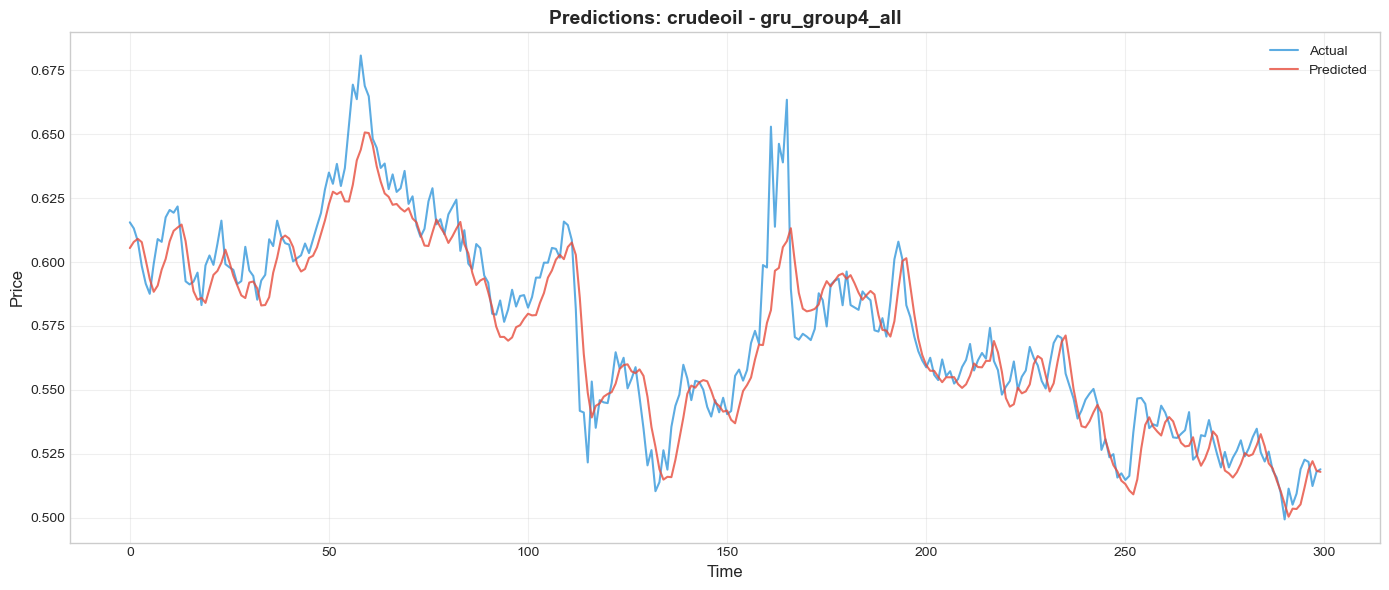

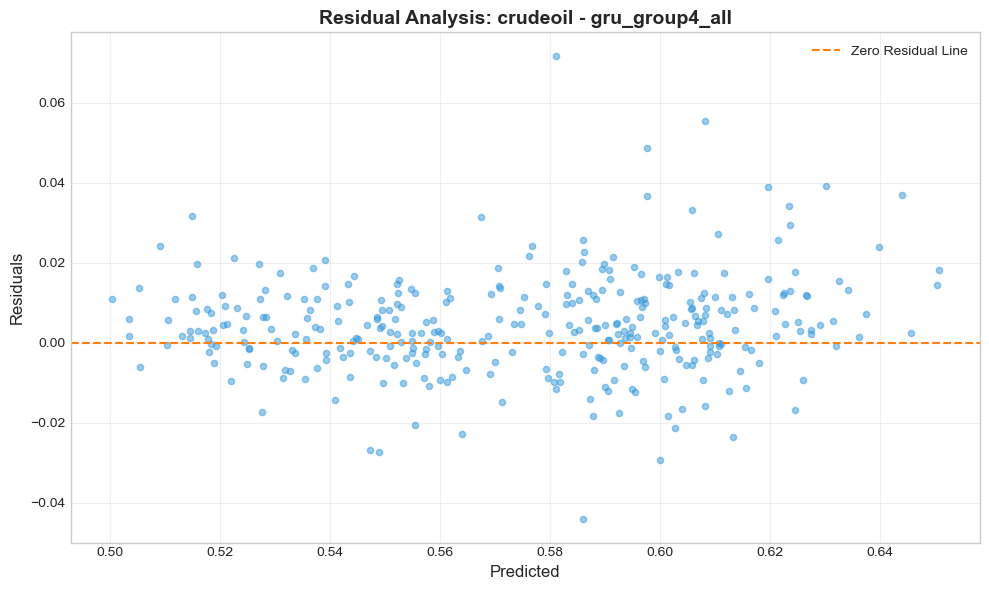

Best model for gold: lstm_group0_ohlcv
RMSE: 0.452457


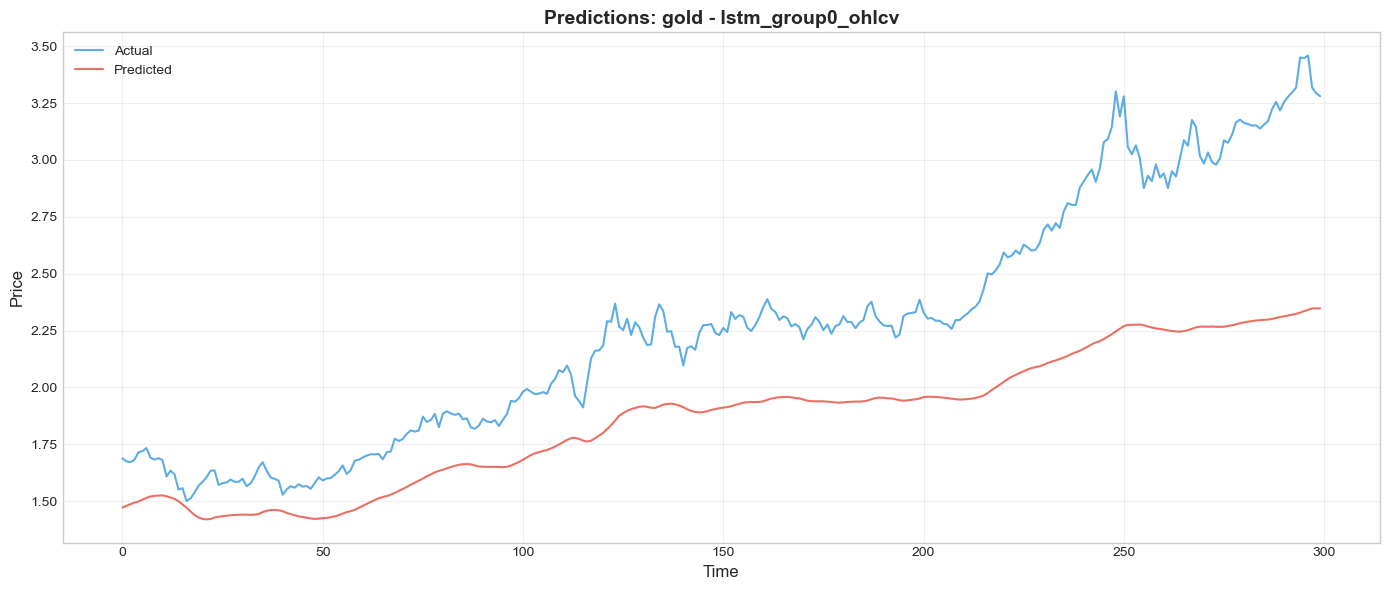

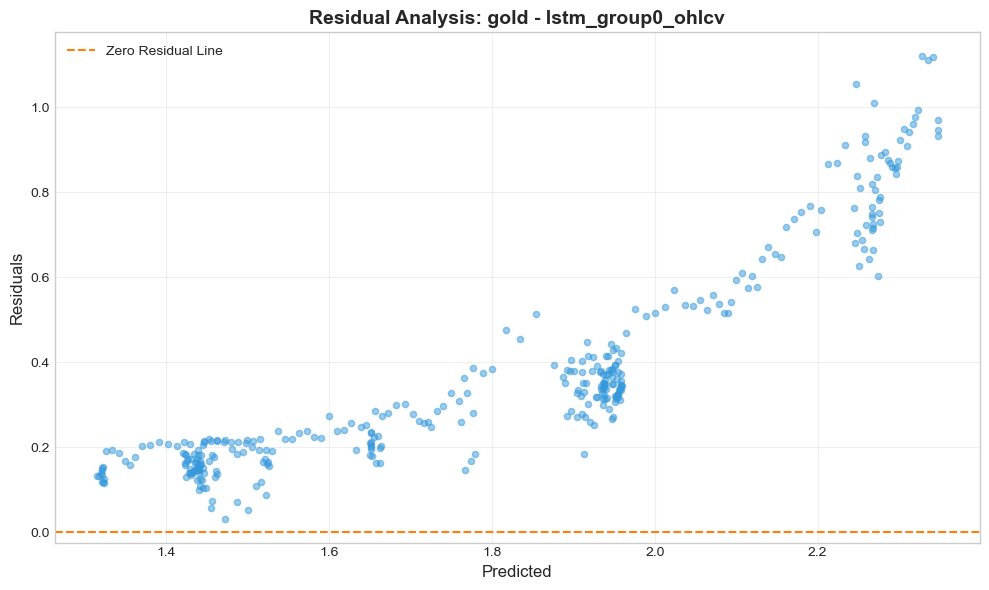

Best model for bitcoin: lstm_group0_ohlcv
RMSE: 0.181118


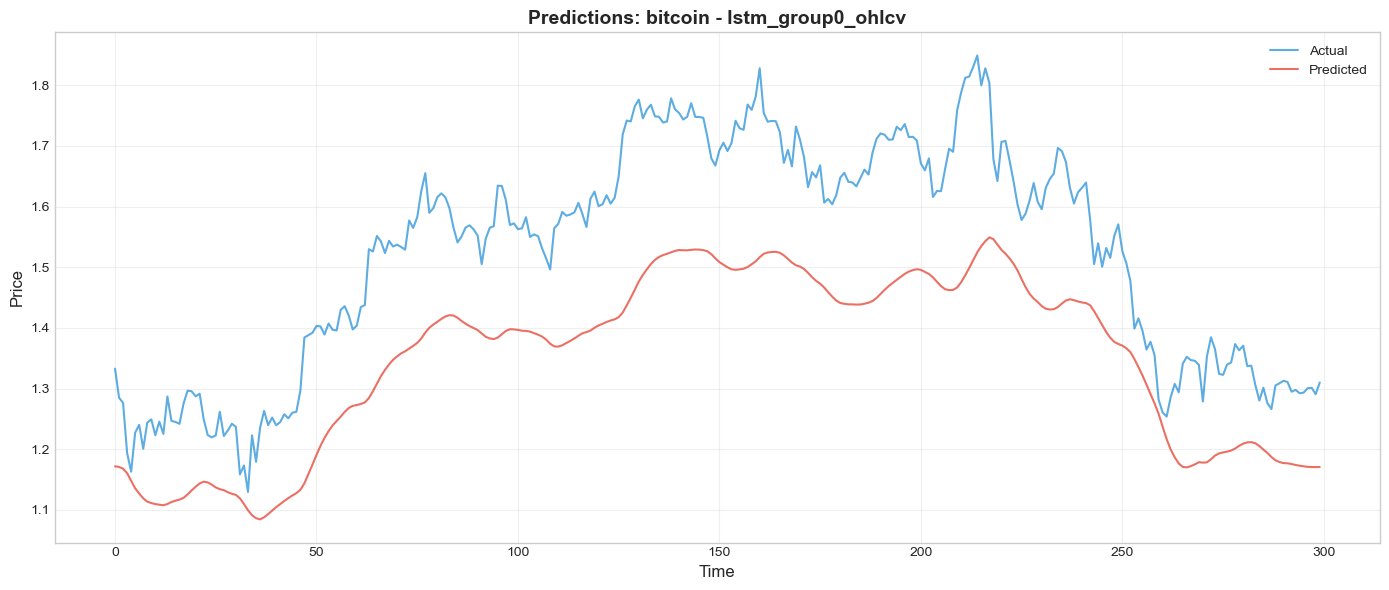

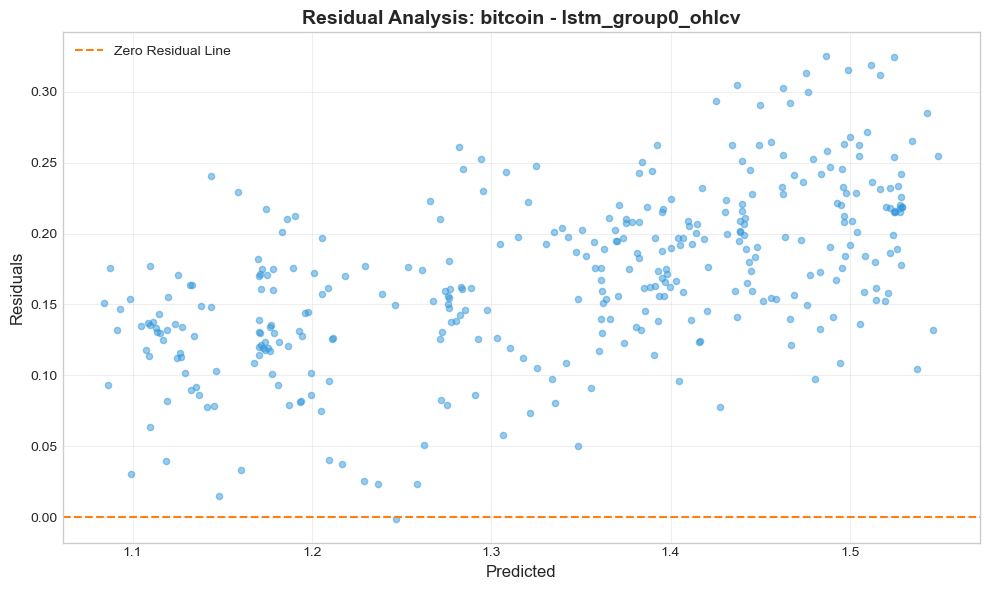

Best model for ethereum: gru_group3_volatility
RMSE: 0.045227


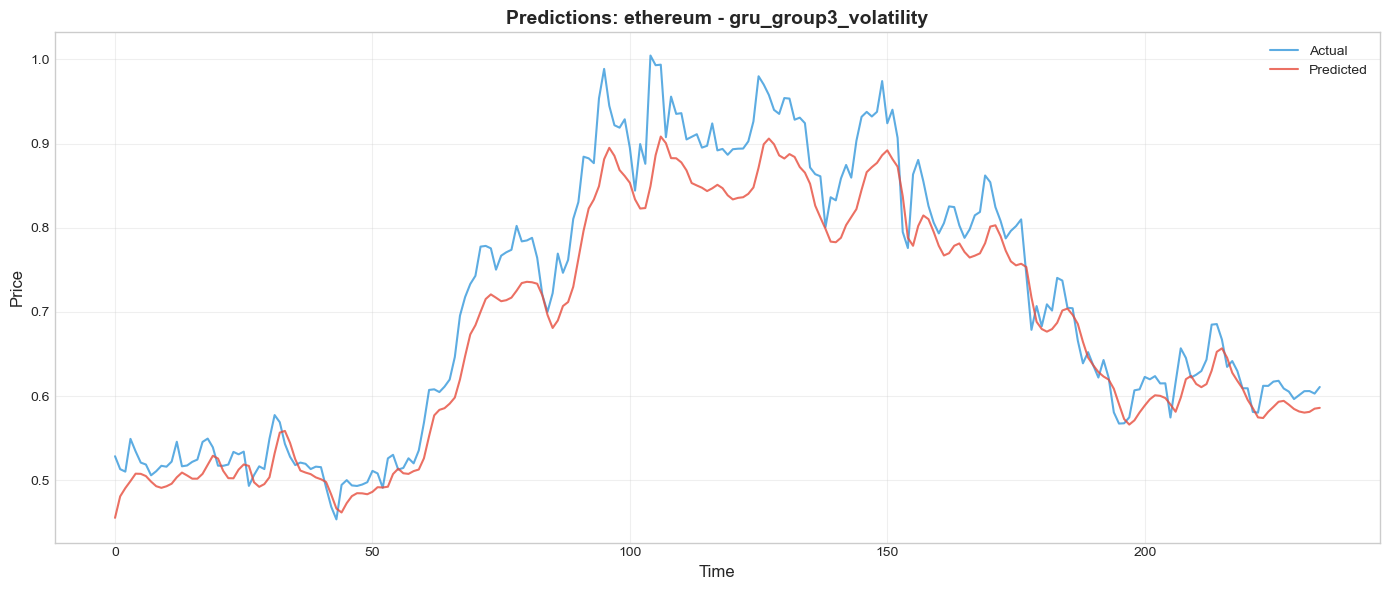

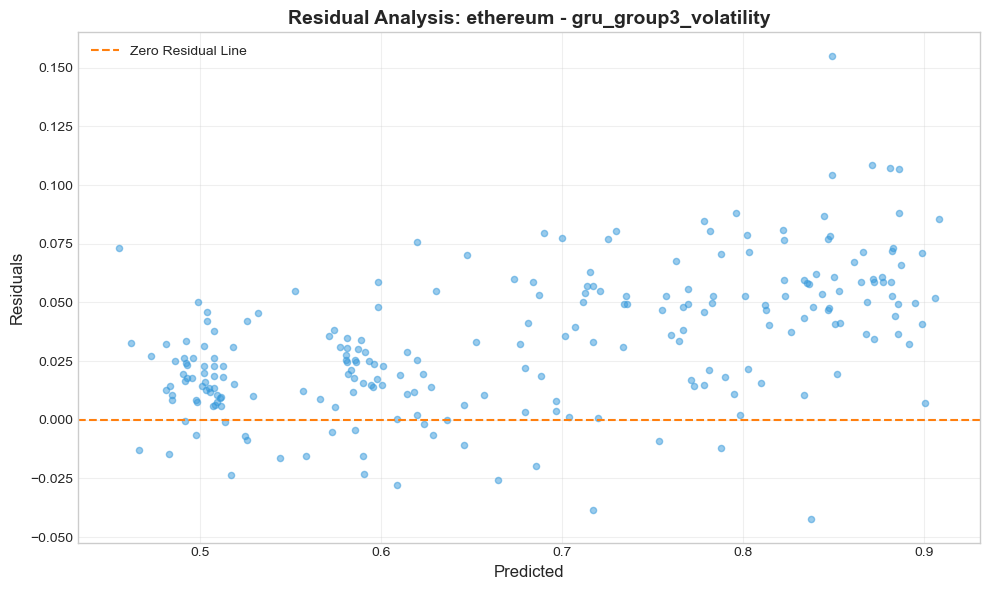

Best model for apple: gru_group0_ohlcv
RMSE: 0.175145


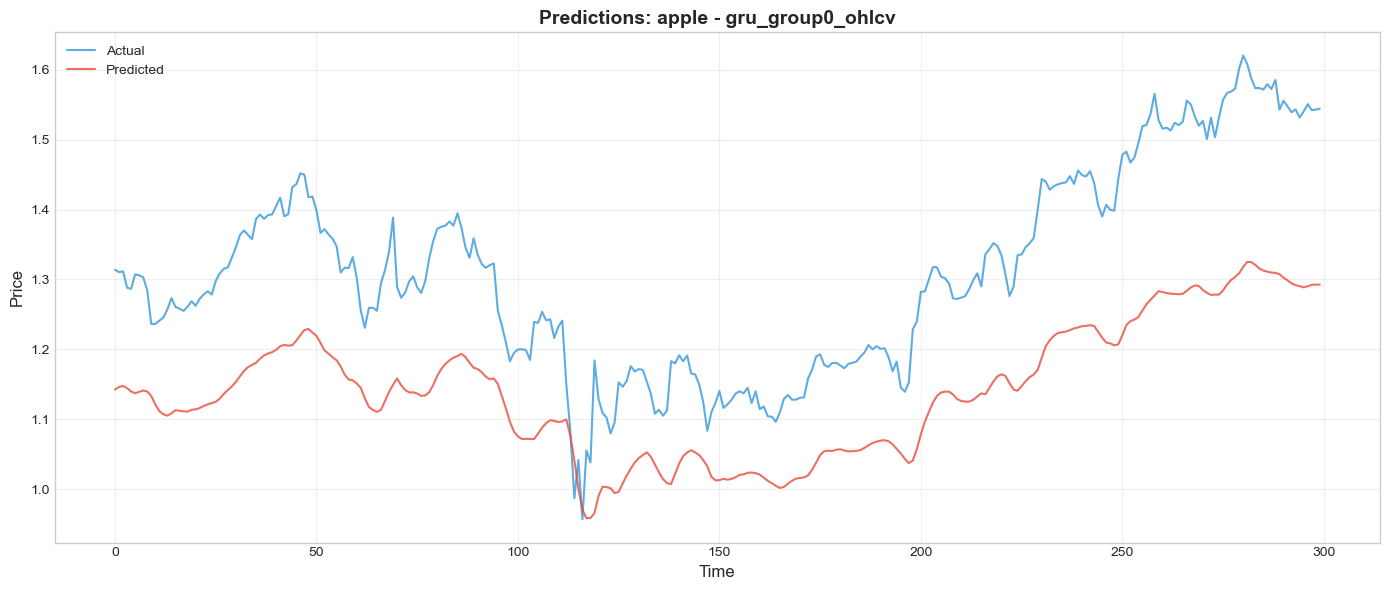

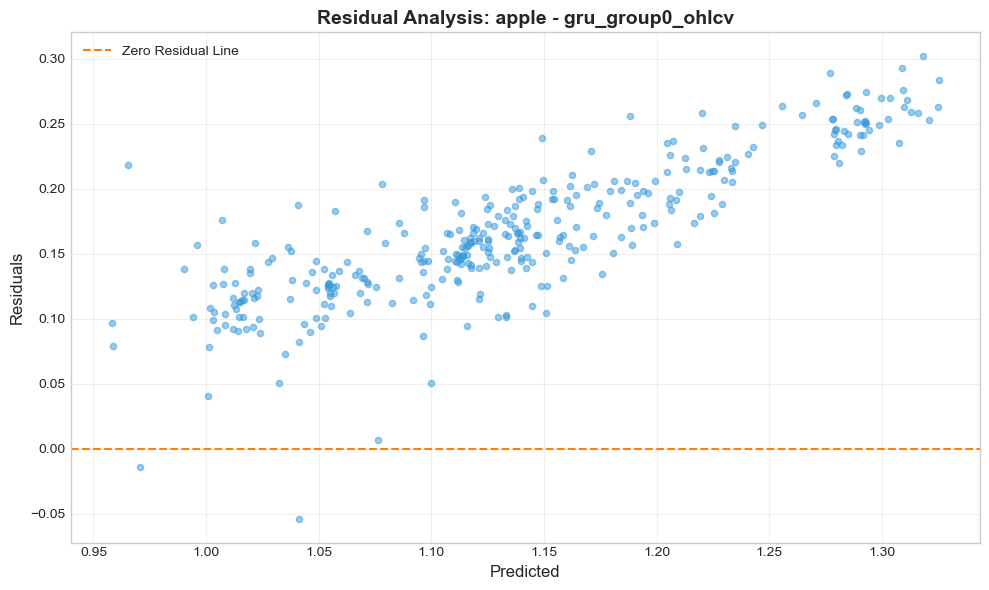

Best model for microsoft: lstm_group3_volatility
RMSE: 0.171020


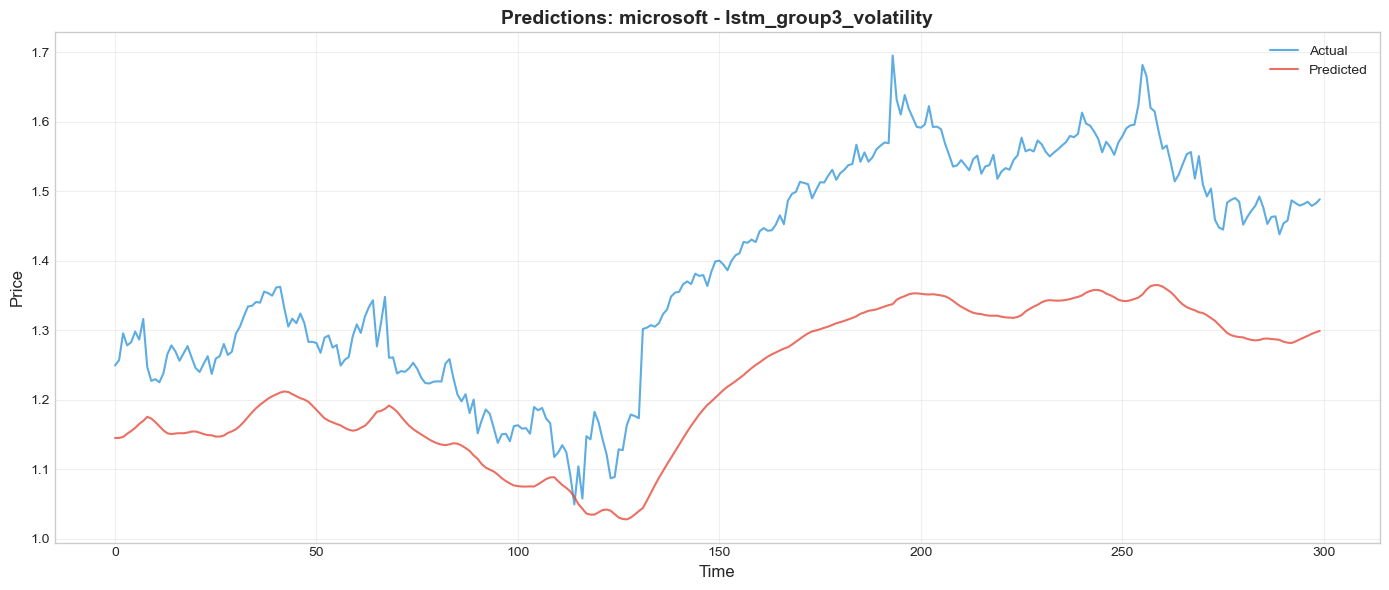

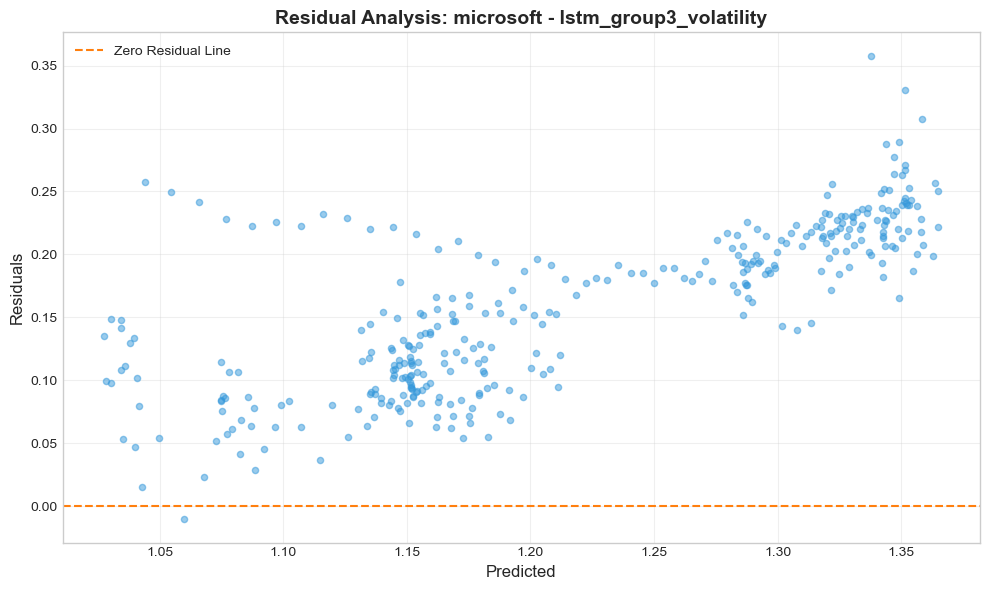

Best model for eurusd: gru_group4_all
RMSE: 0.019108


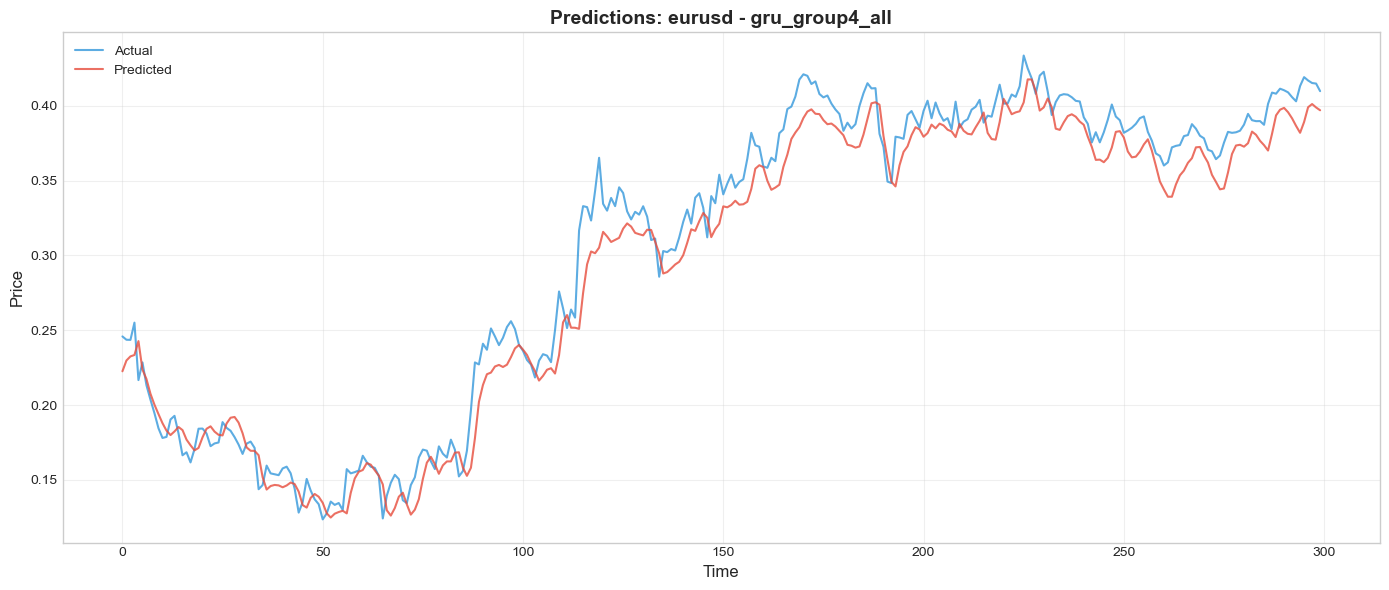

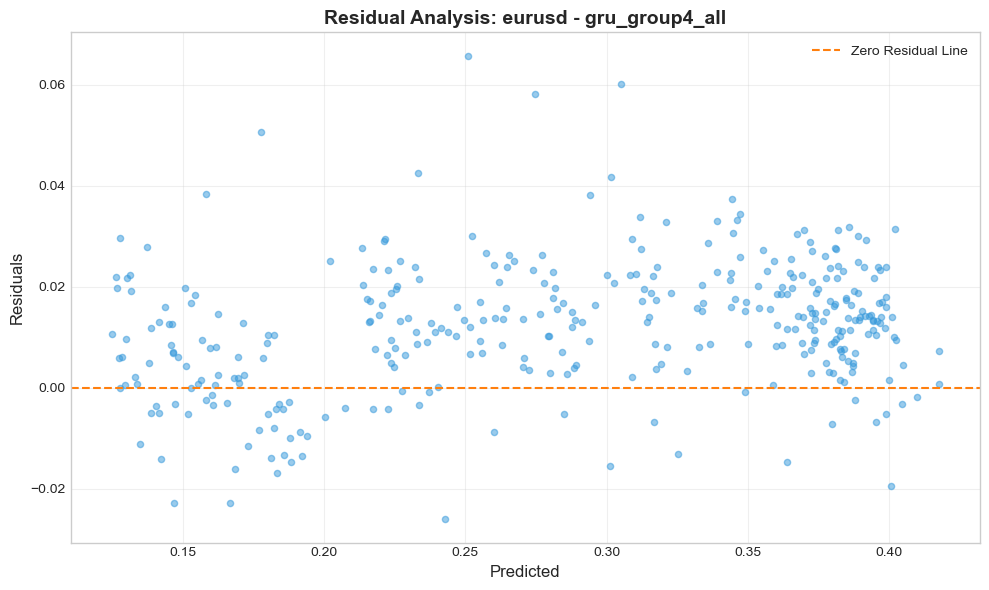

Best model for usdjpy: lstm_group3_volatility
RMSE: 0.045300


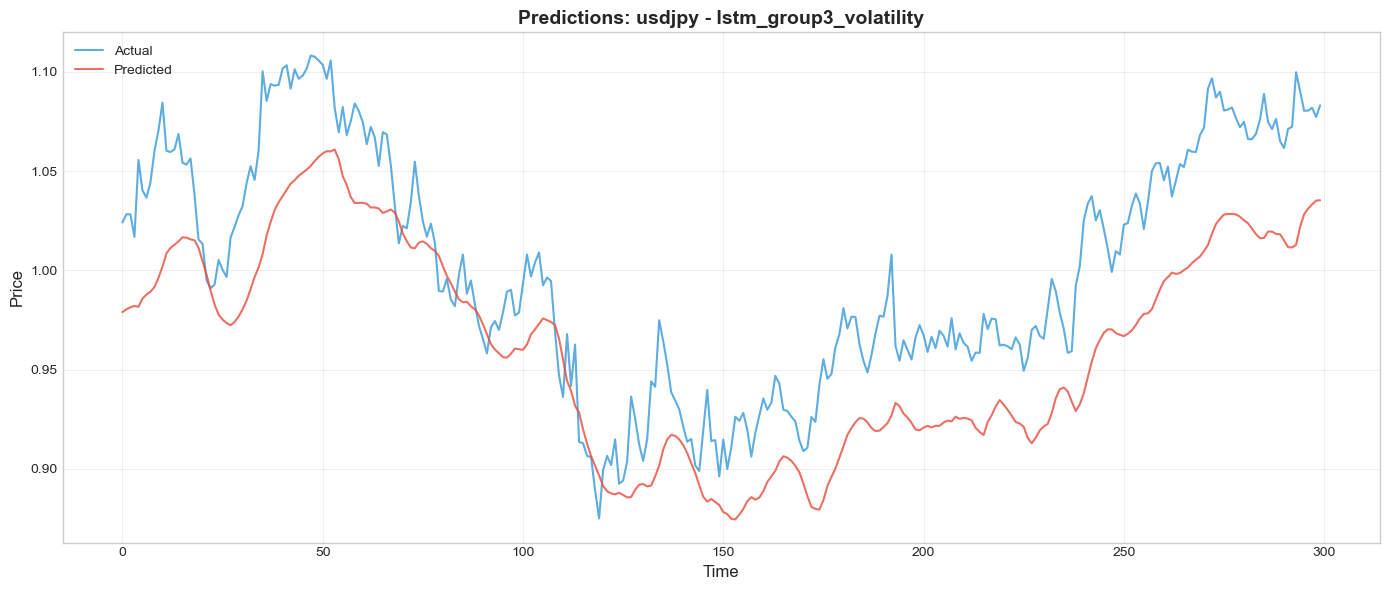

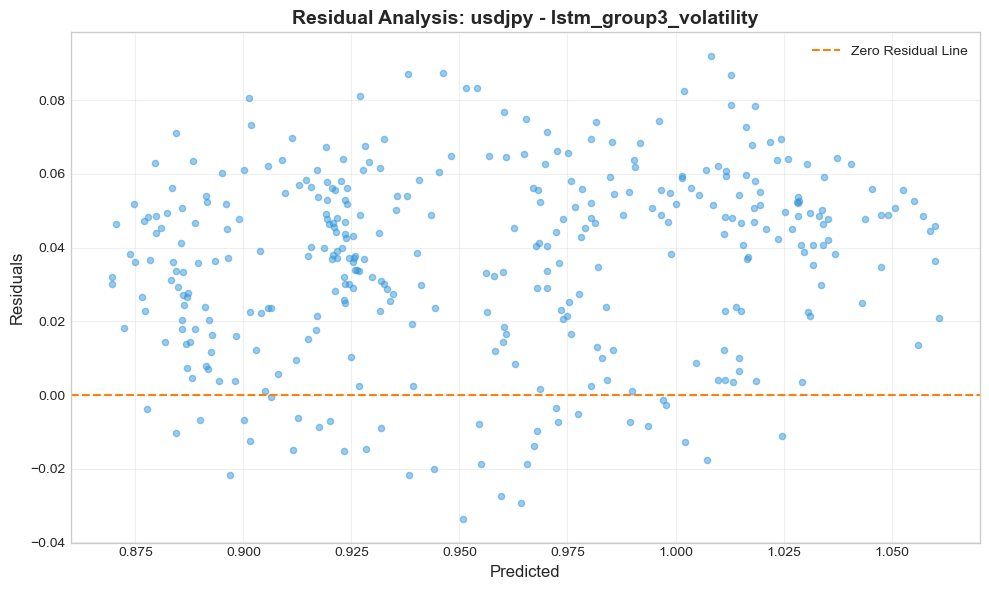

Best model for nasdaq: gru_group0_ohlcv
RMSE: 0.151877


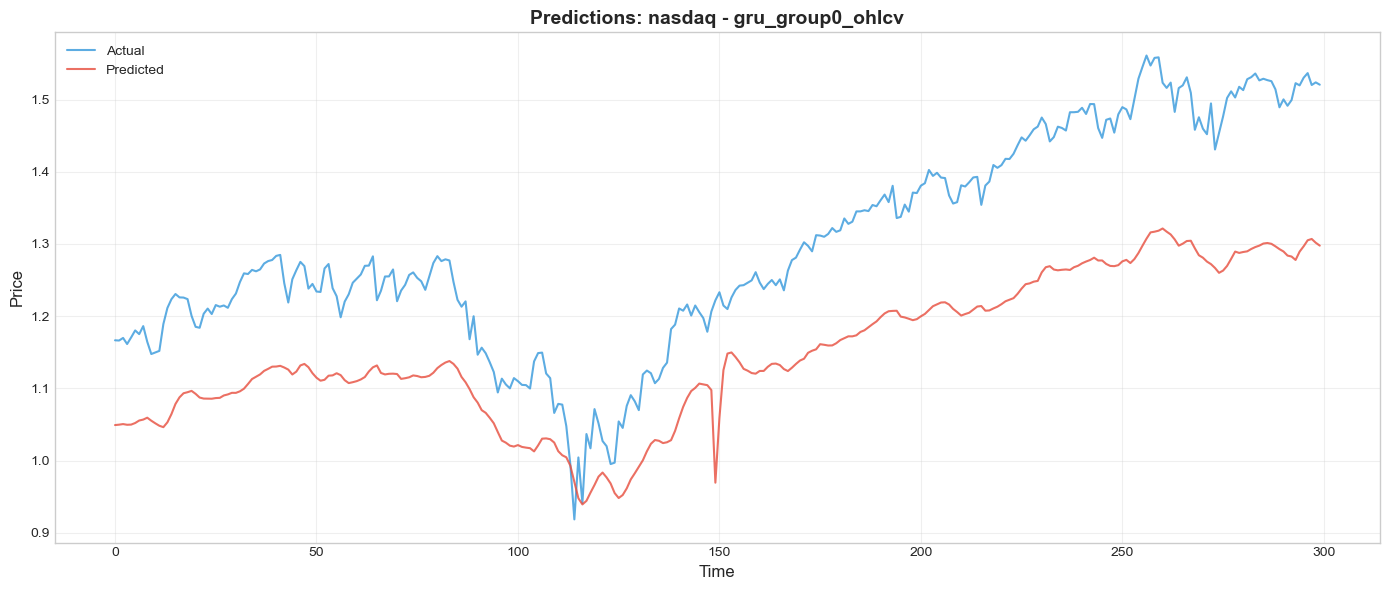

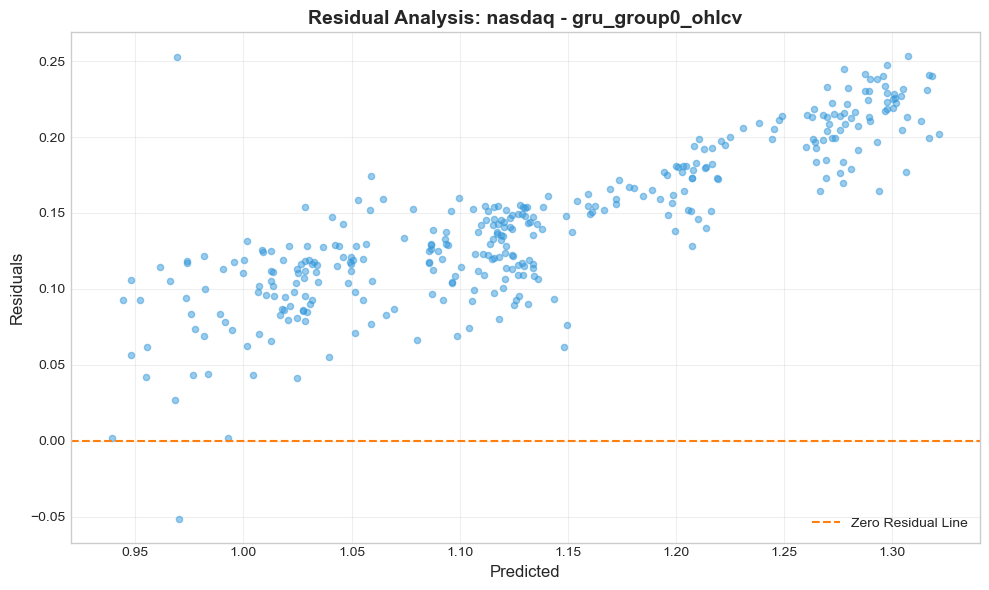

Best model for sp500: gru_group0_ohlcv
RMSE: 0.168392


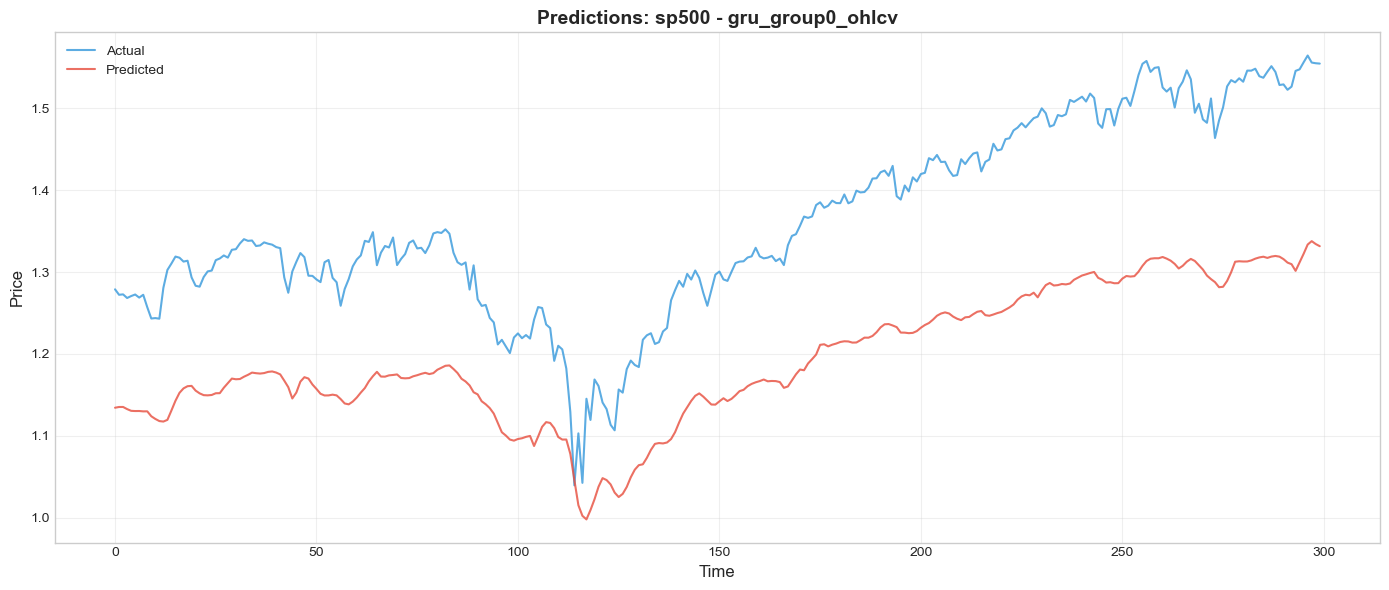

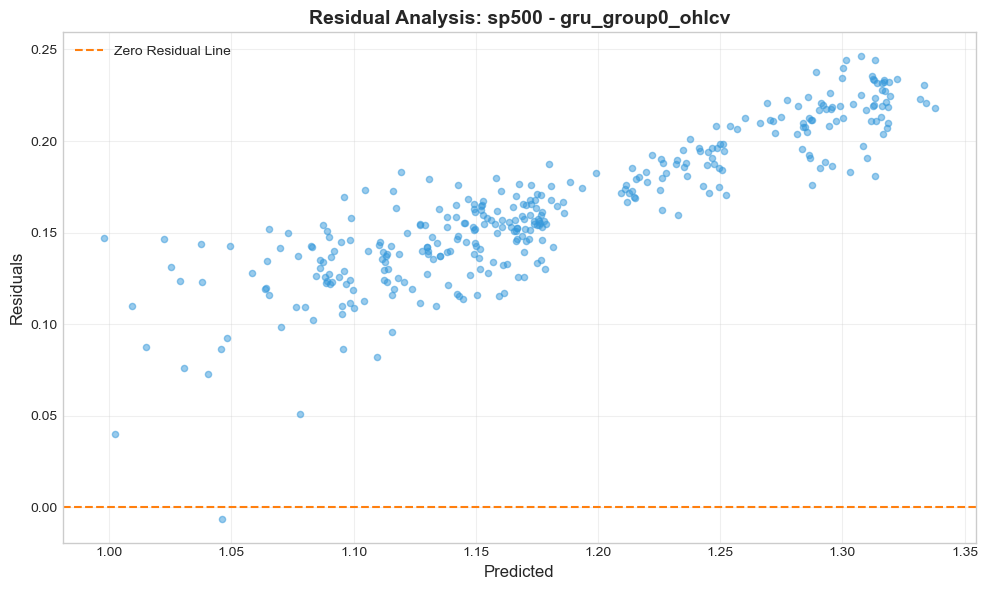

In [6]:
# Prediction Visualizations
for asset, predictions in all_predictions.items():
    if not predictions:
        continue
        
    asset_config = config.get_asset_config(asset)
    category = asset_config['category']
    
    # Find best model by RMSE
    best_key = min(predictions.keys(),key=lambda k: predictions[k]['metrics'].get('rmse', predictions[k]['metrics'].get(rmse, np.inf)))
    best_data = predictions[best_key]
    
    print(f"Best model for {asset}: {best_key}")
    print(f"RMSE: {best_data['metrics'][rmse]:.6f}")
    
    # Plot predictions (last 300 points)
    fig = plot_predictions(
        best_data['y_test'].flatten()[-300:],
        best_data['y_pred'].flatten()[-300:],
        title=f'Predictions: {asset} - {best_key}'
    )
    plt.show()
    
    # Residual analysis
    fig = plot_residuals(
        best_data['y_test'].flatten(),
        best_data['y_pred'].flatten(),
        title=f'Residual Analysis: {asset} - {best_key}'
    )
    plt.show()

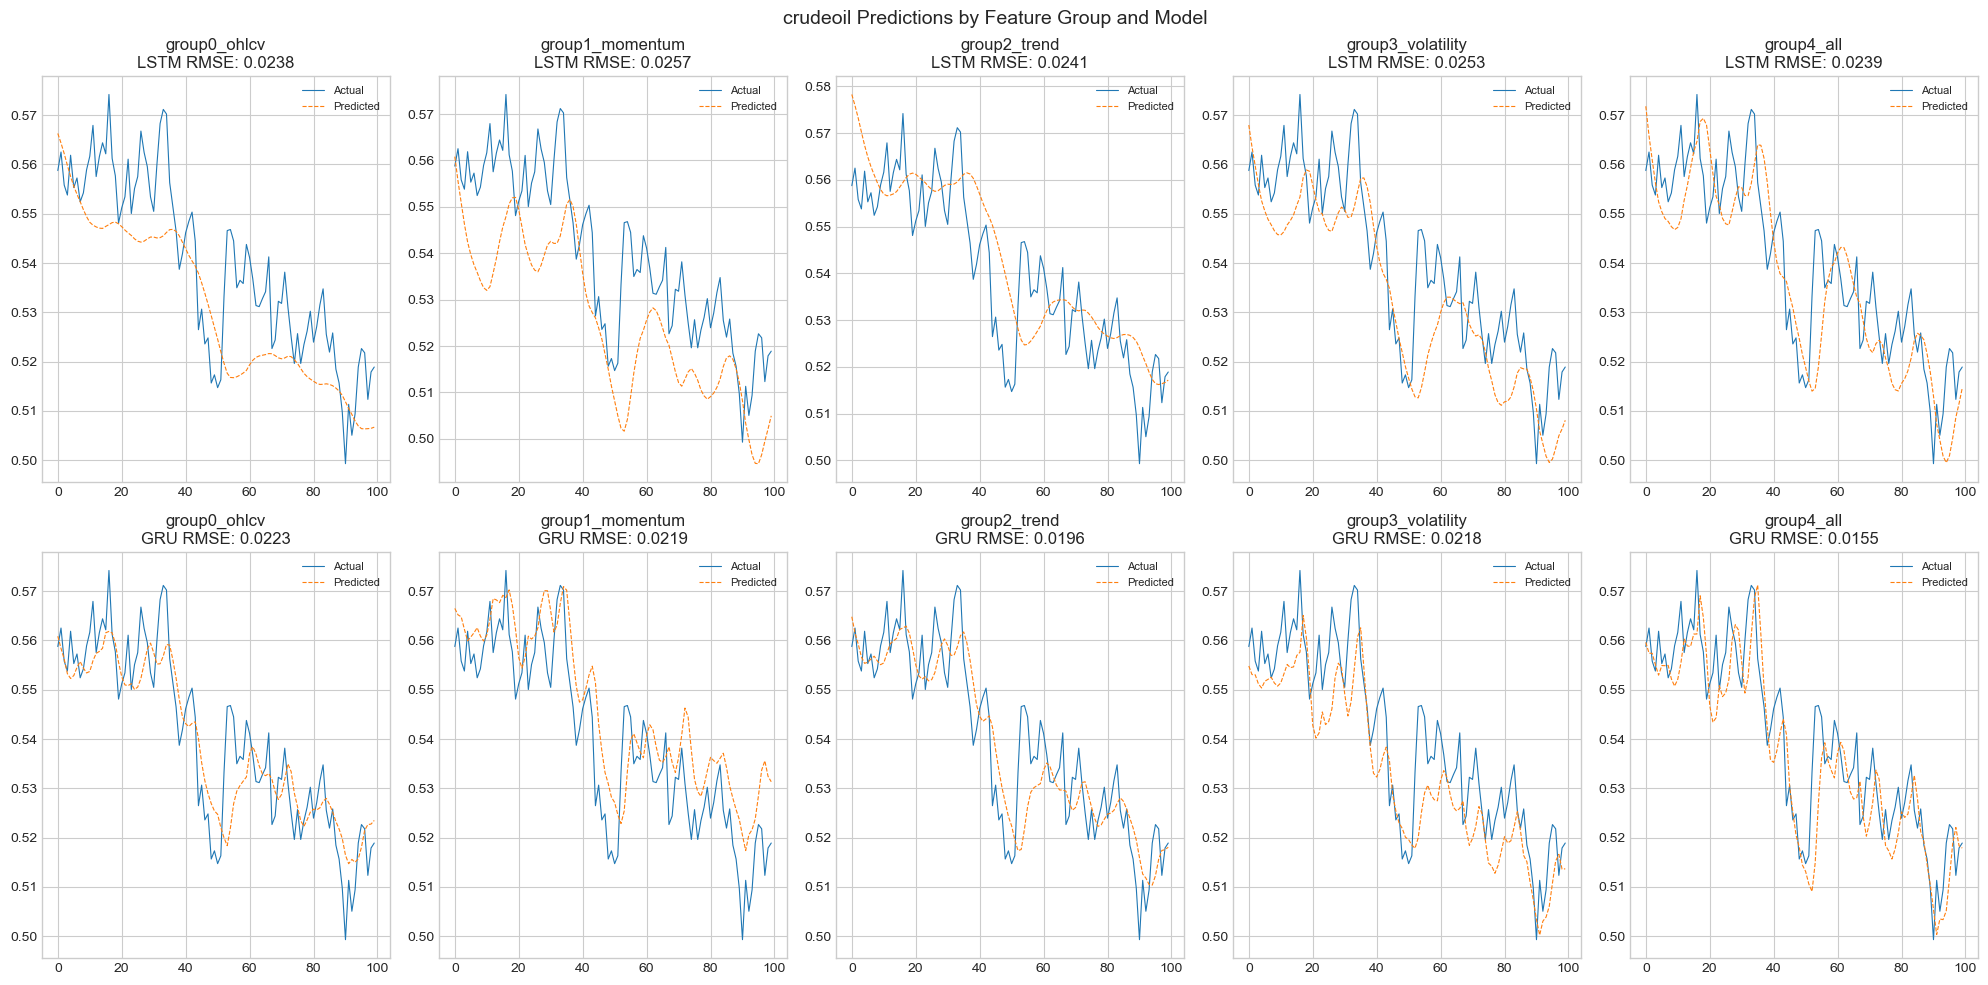

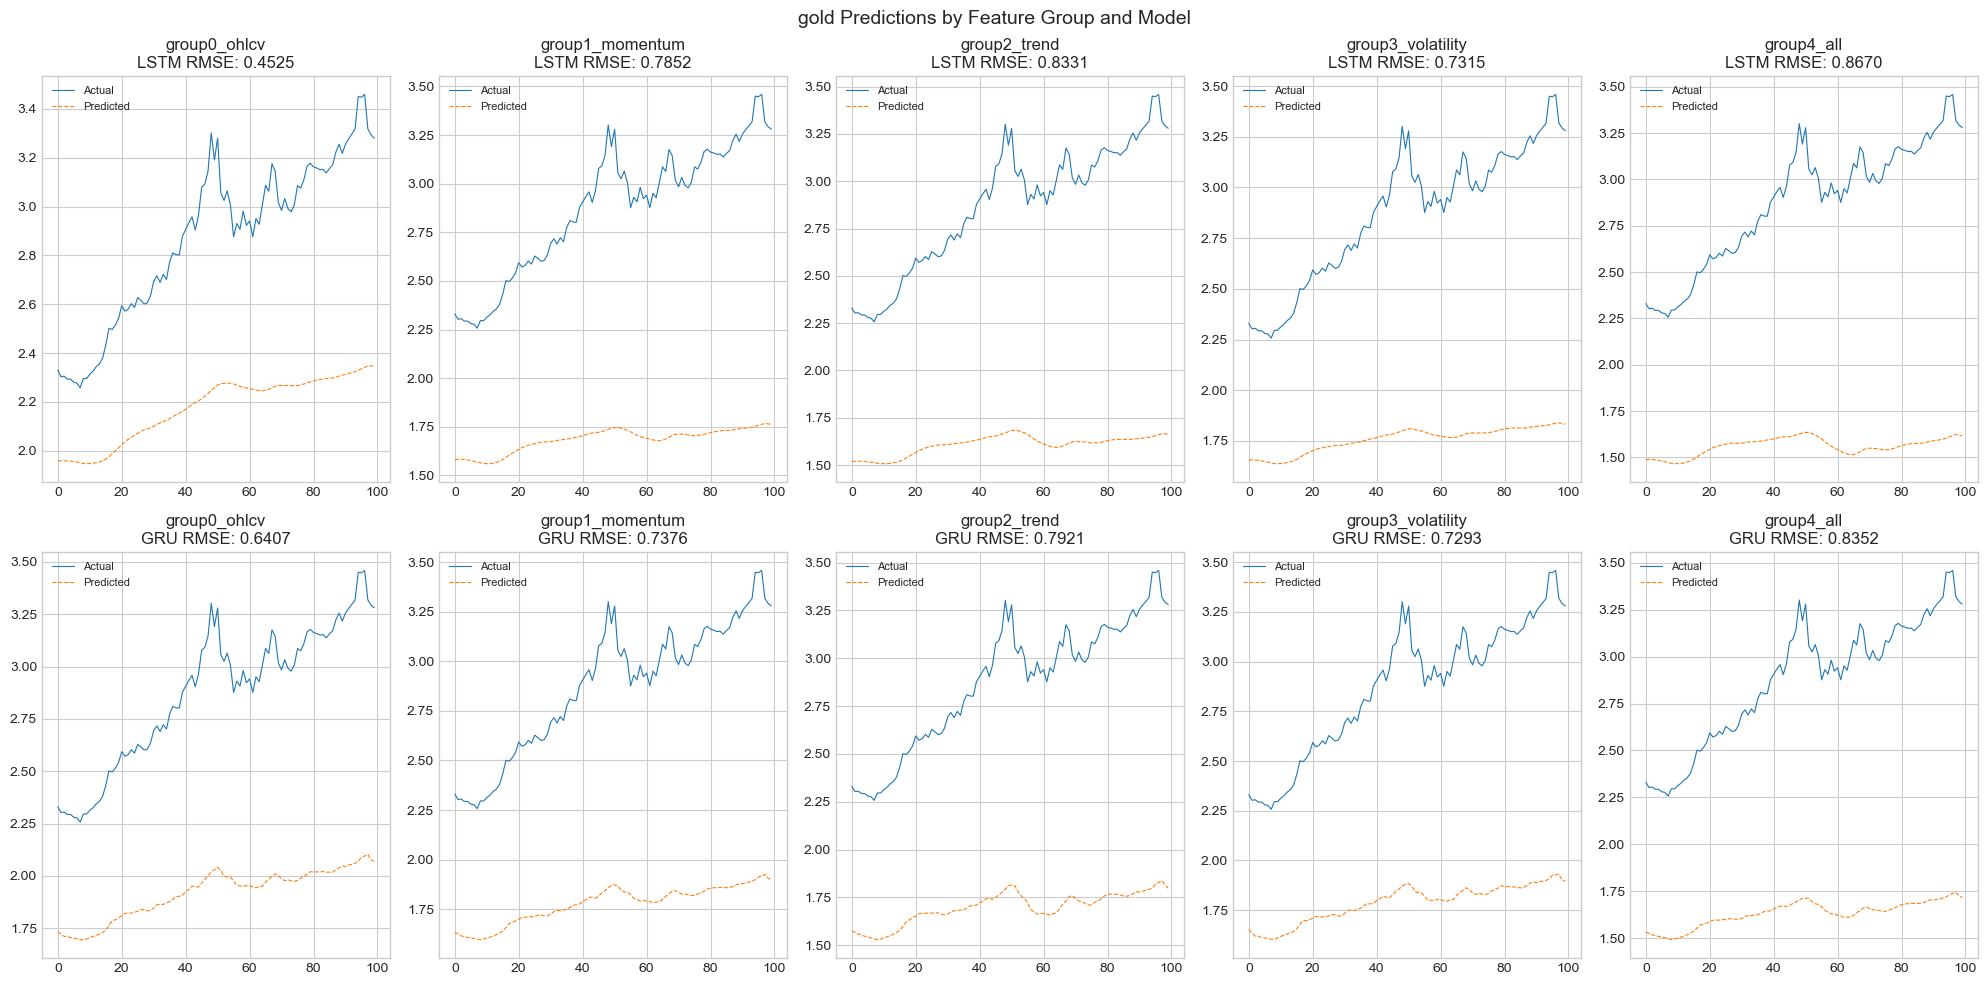

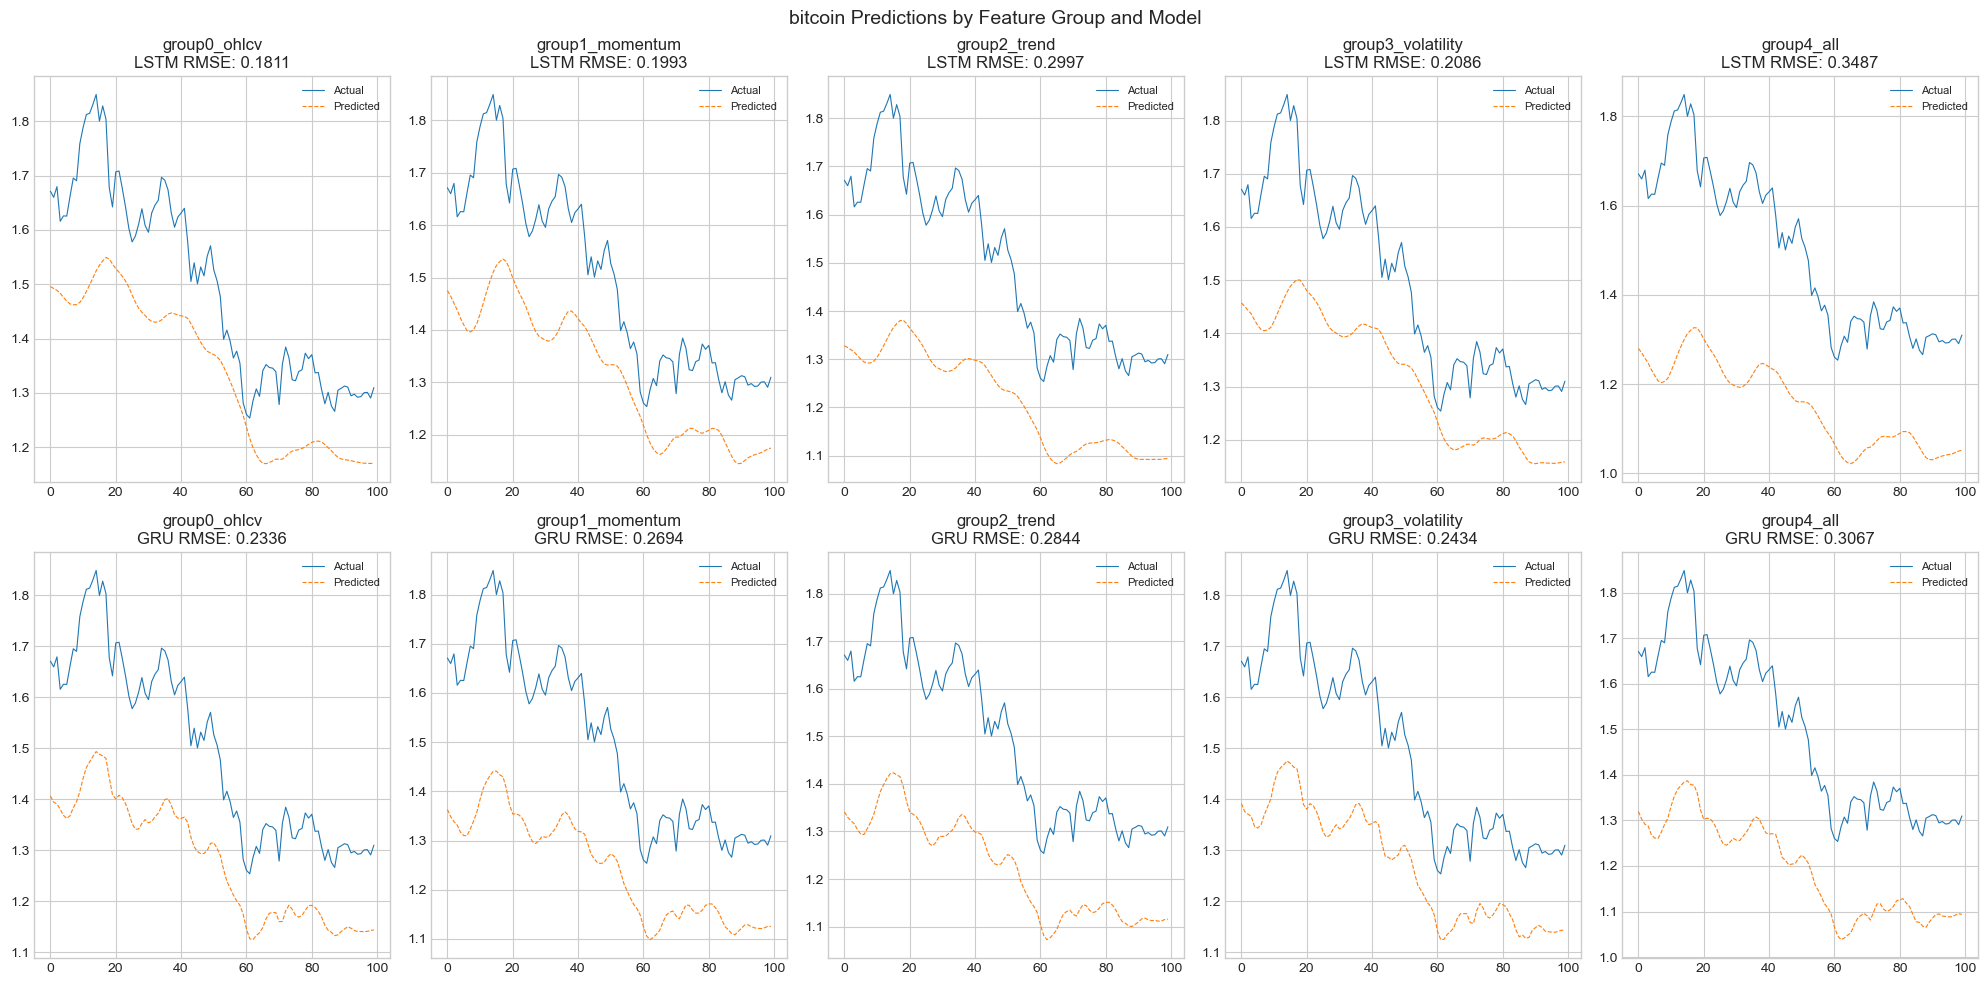

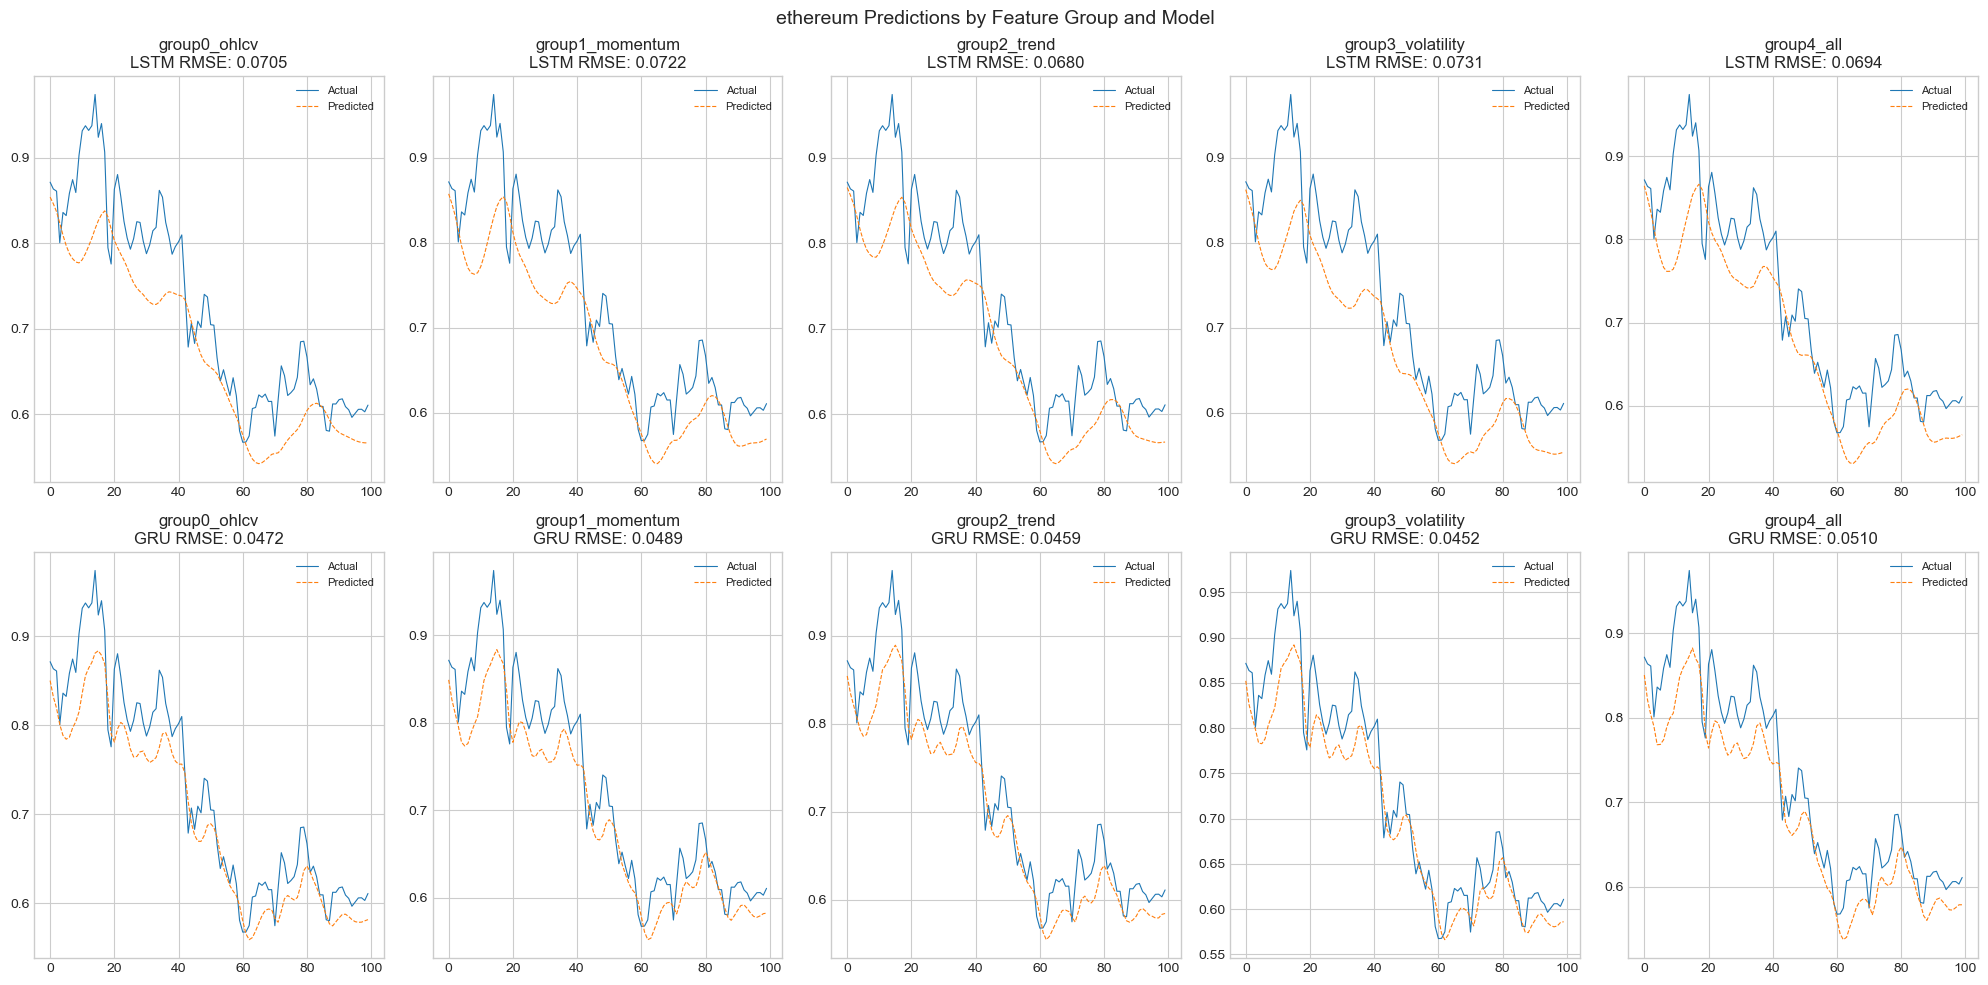

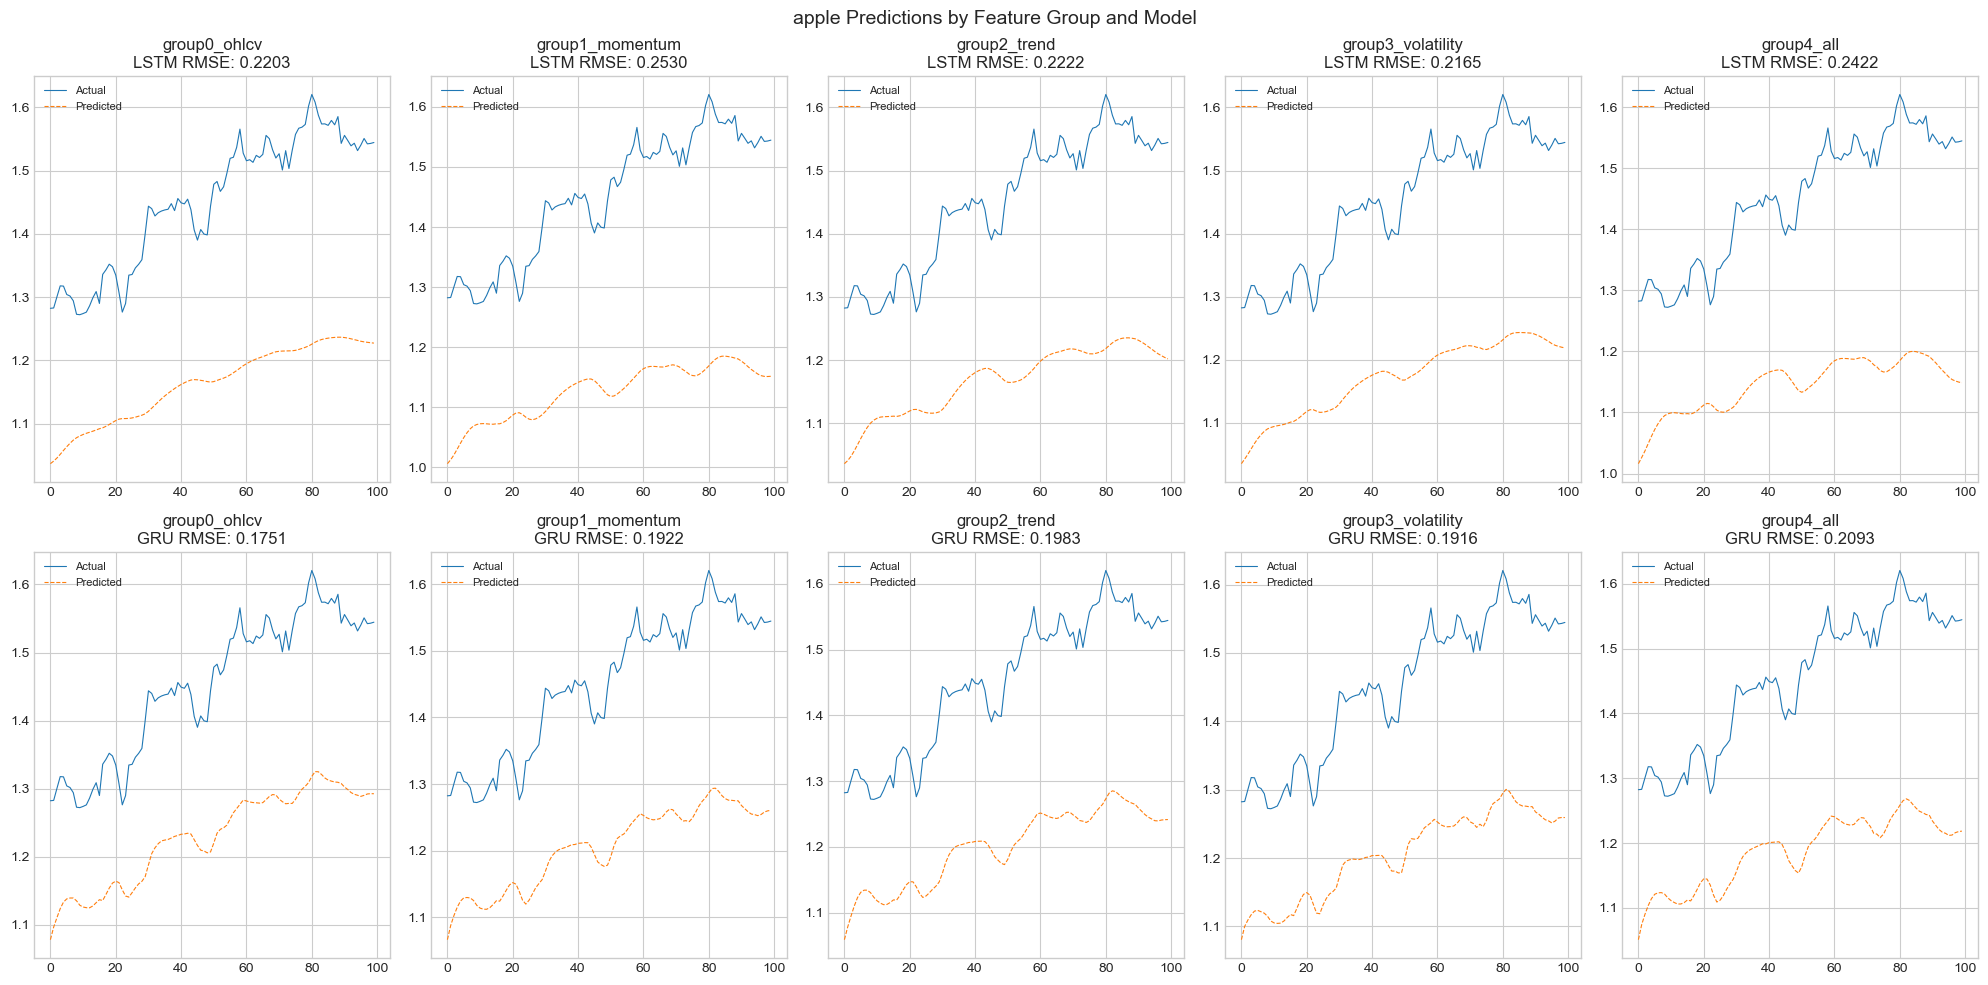

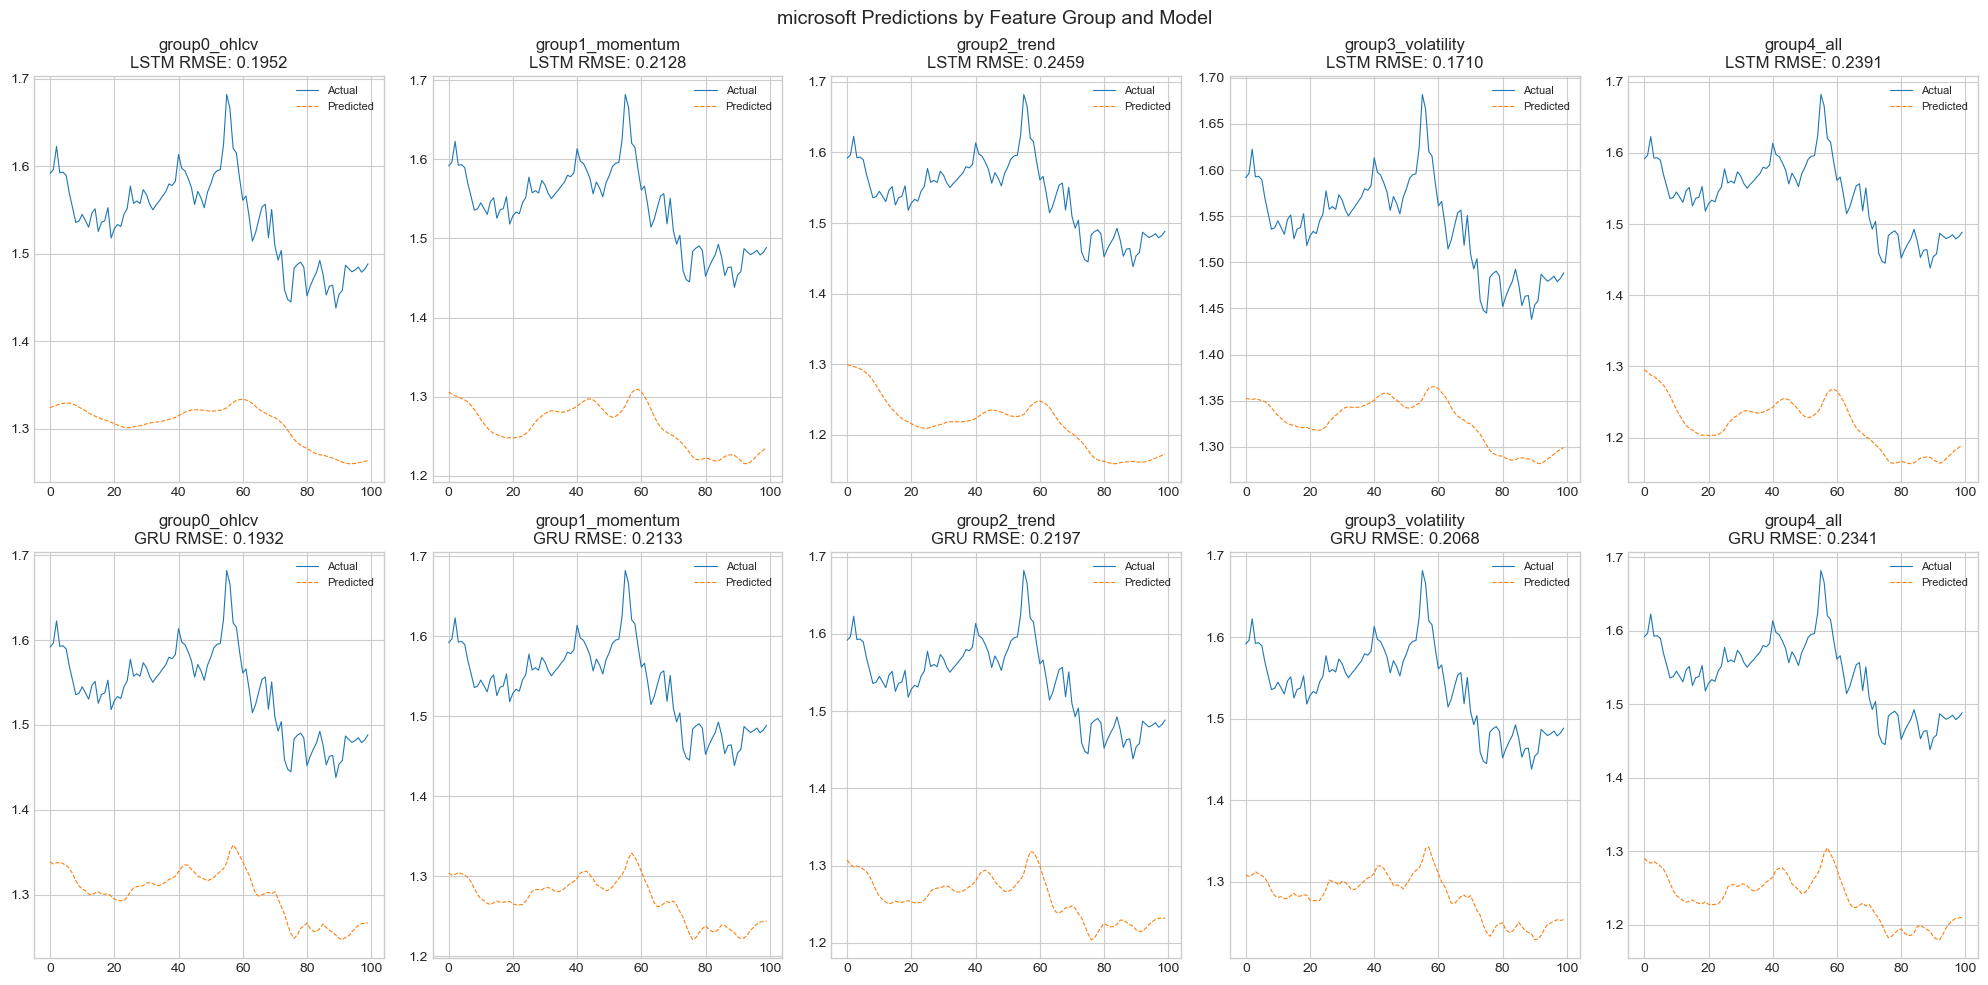

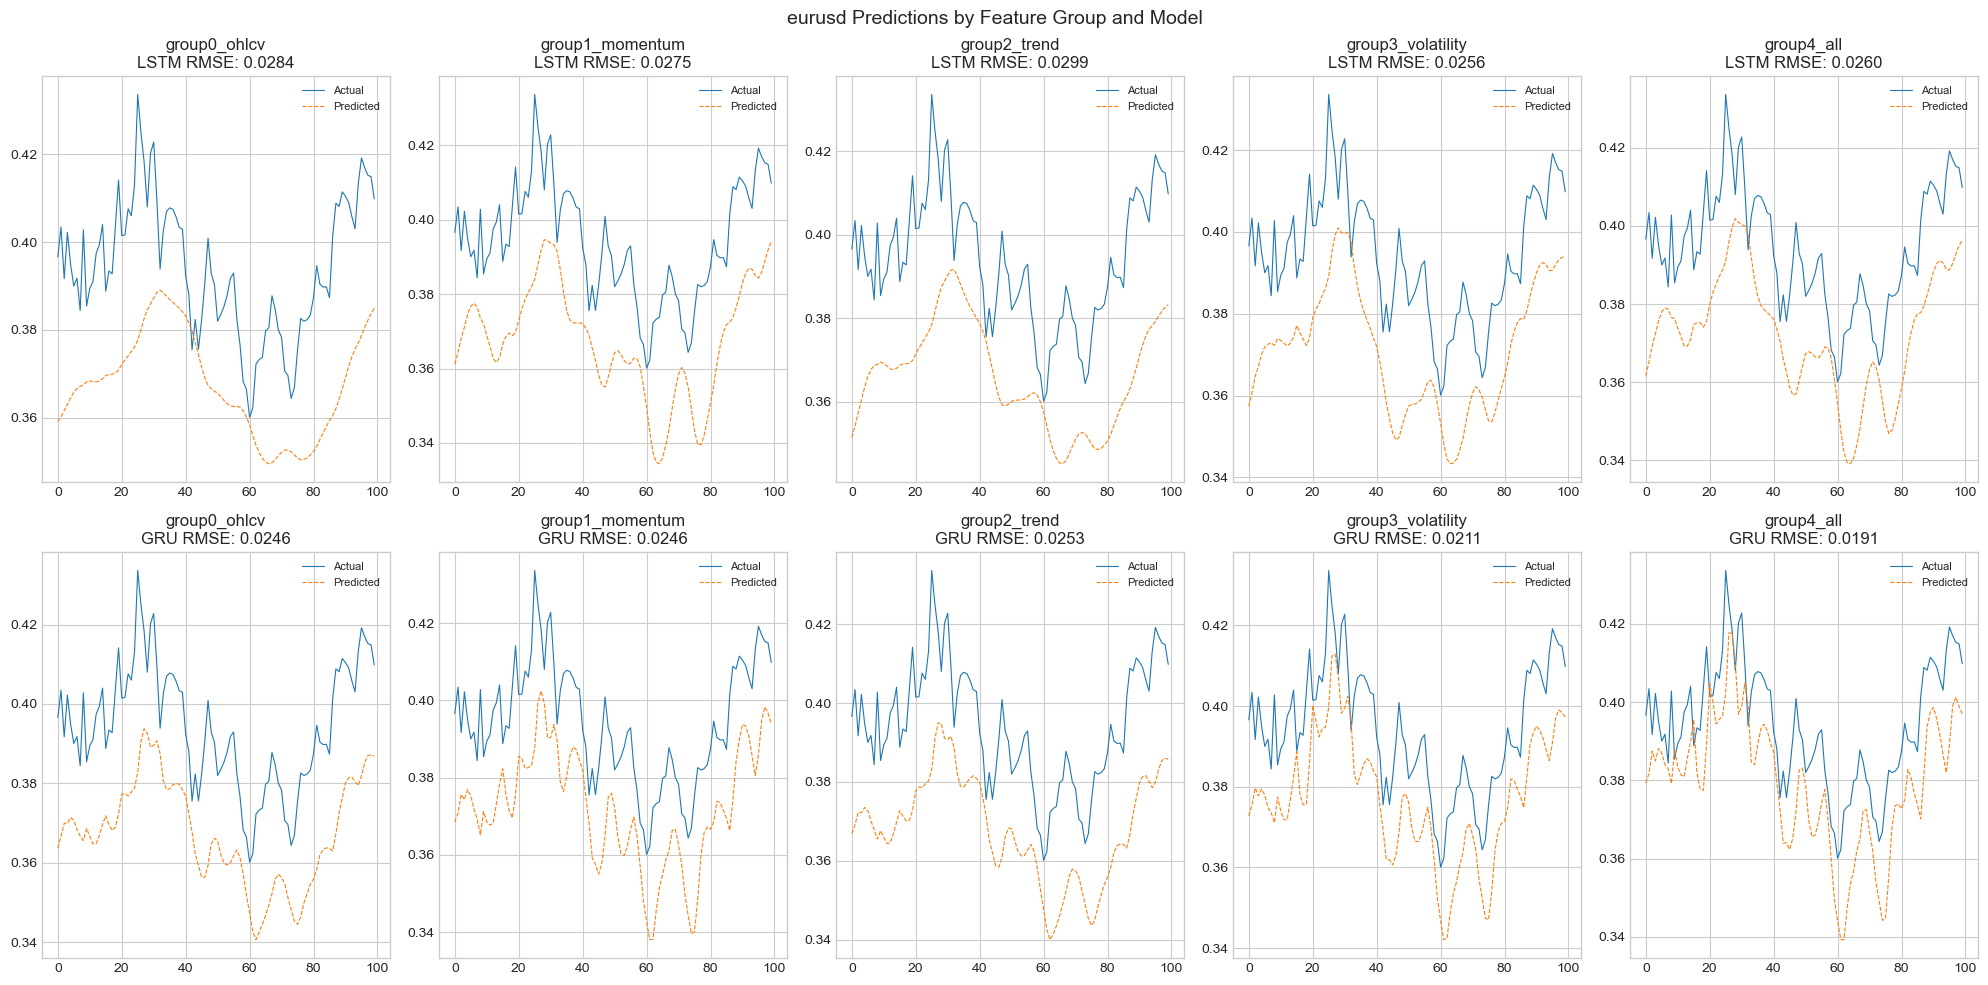

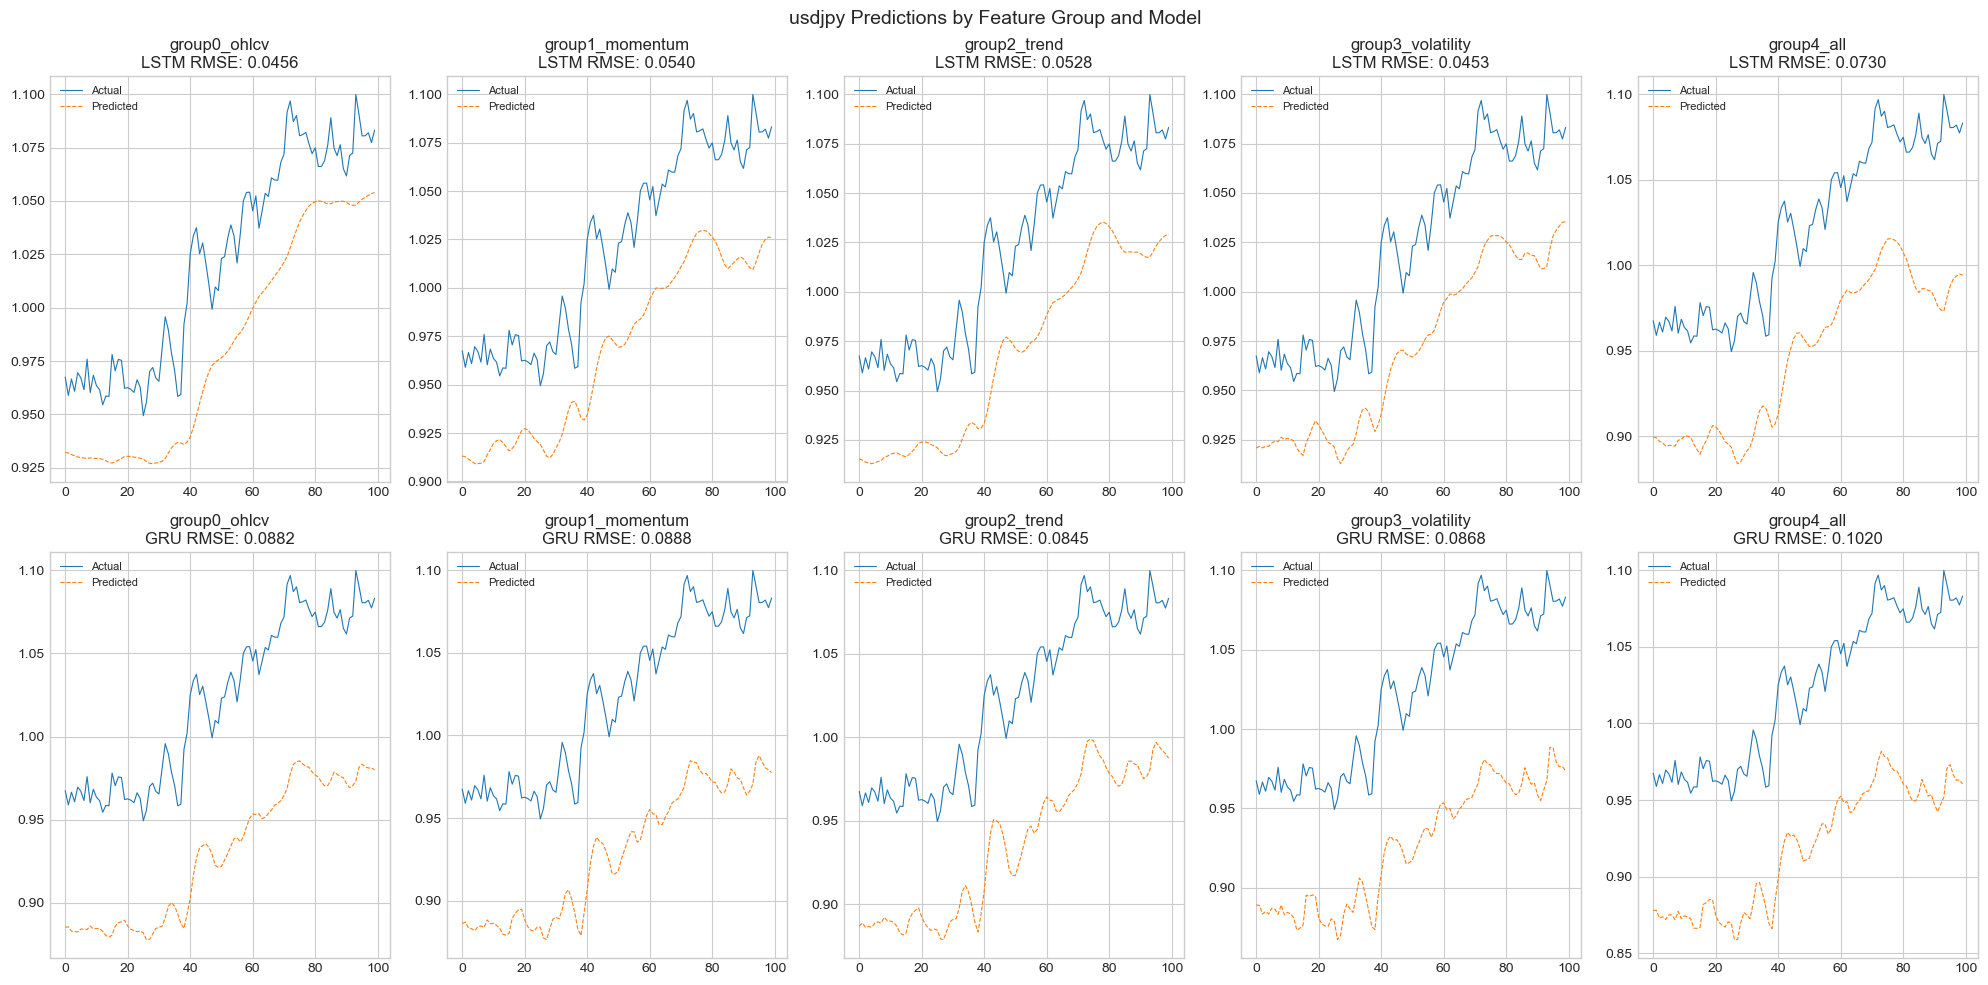

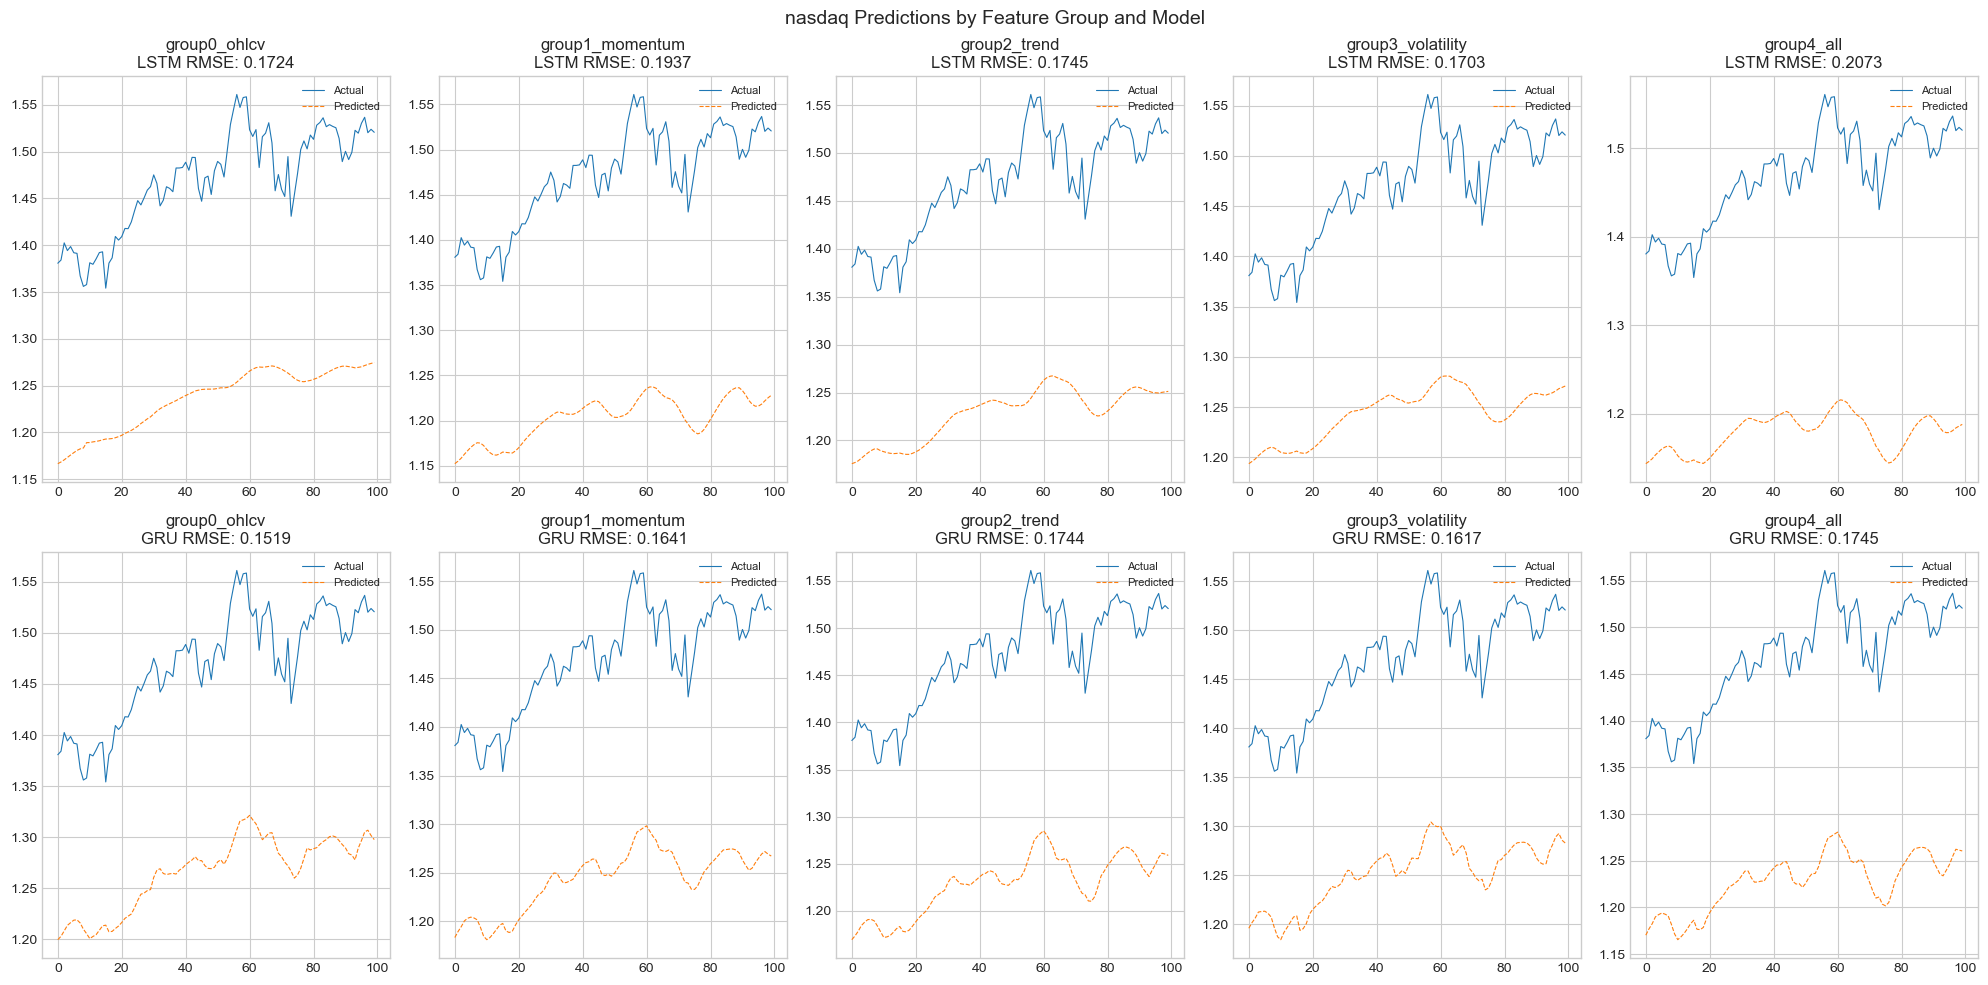

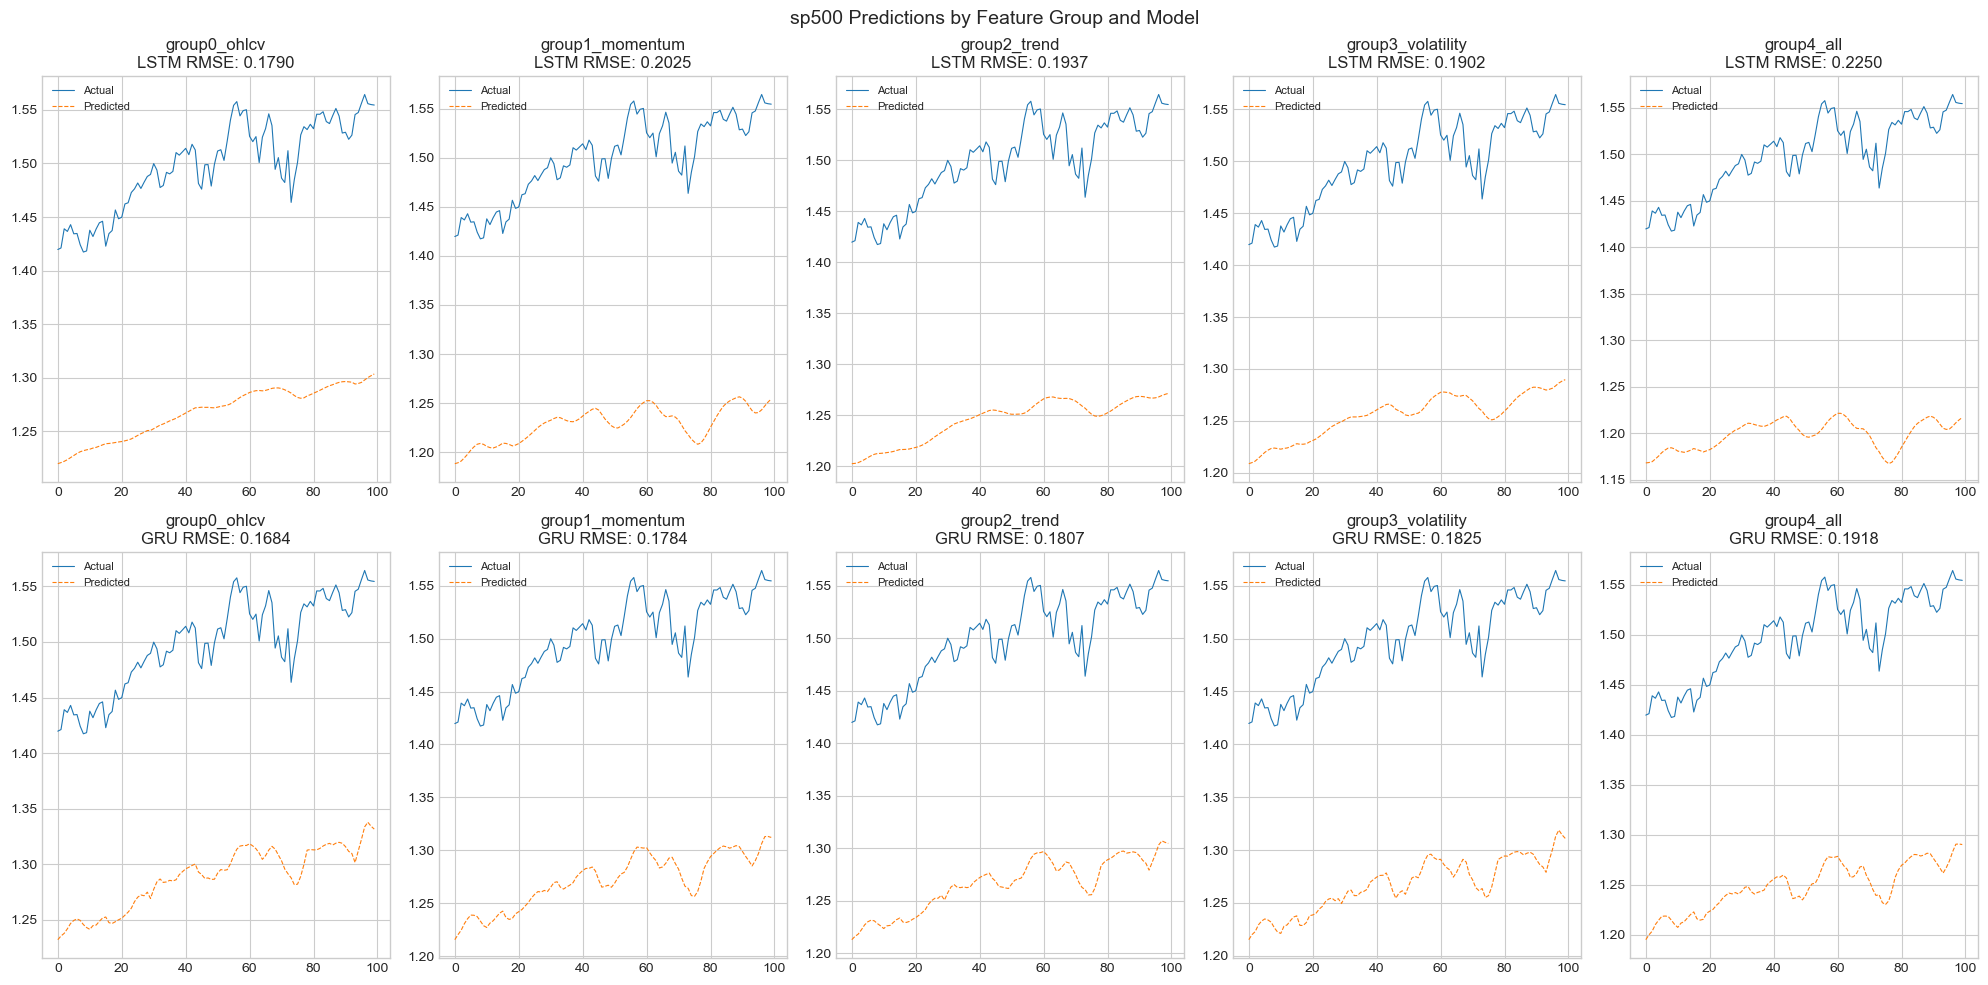

In [7]:
# Compare all groups for LSTM and GRU
for asset, predictions in all_predictions.items():
    if not predictions:
        continue
        
    asset_config = config.get_asset_config(asset)
    category = asset_config['category']
    
    fig, axes = plt.subplots(2, len(GROUPS), figsize=(20, 10))
    
    for idx, group in enumerate(GROUPS):
        for row, model_type in enumerate(['lstm', 'gru']):
            ax = axes[row, idx]
            key = f"{model_type}_{group}"
            
            if key in predictions:
                data = predictions[key]
                y_test = data['y_test'].flatten()[-100:]
                y_pred = data['y_pred'].flatten()[-100:]
                
                ax.plot(y_test, color='#1f77b4', label='Actual', linewidth=0.8)
                ax.plot(y_pred, color='#ff7f0e', linestyle='--', label='Predicted', linewidth=0.8)
                ax.set_title(f"{group}\n{model_type.upper()} RMSE: {data['metrics'][rmse]:.4f}")
                ax.legend(fontsize=8)
            else:
                ax.set_title(f"{group}\n{model_type.upper()}\nNo data")
    
    fig.suptitle(f'{asset} Predictions by Feature Group and Model', fontsize=14)
    plt.tight_layout()
    plt.show()

## 3. Metrics Comparison


Metrics for crudeoil:


,asset,model,group,rmse_ensemble,rmse_mean,rmse_std,mae_ensemble,mae_mean,mae_std,mape_ensemble,mape_mean,mape_std,da_ensemble,da_mean,da_std
0,crudeoil,LSTM,group0_ohlcv,0.023078,0.023837,0.004651,0.017287,0.018178,0.005158,2.917107,3.075139,0.878448,46.017699,45.545723,0.300827
1,crudeoil,LSTM,group1_momentum,0.025199,0.025708,0.003947,0.020581,0.021127,0.004176,3.486929,3.585000,0.715825,42.182891,43.421829,1.542973
2,crudeoil,LSTM,group2_trend,0.018853,0.024092,0.004423,0.013561,0.019175,0.004754,2.312353,3.293302,0.857791,41.887906,42.241888,1.229066
3,crudeoil,LSTM,group3_volatility,0.019032,0.025329,0.002219,0.014447,0.021199,0.002378,2.452451,3.634562,0.453673,43.952802,44.365782,0.886920
4,crudeoil,LSTM,group4_all,0.017621,0.023901,0.005109,0.012955,0.019426,0.005351,2.210685,3.327331,0.952794,45.722714,45.191740,1.683226
5,crudeoil,GRU,group0_ohlcv,0.015878,0.022253,0.005955,0.011705,0.019080,0.006587,1.965504,3.277698,1.131684,55.162242,55.634218,2.342116
6,crudeoil,GRU,group1_momentum,0.013372,0.021892,0.006534,0.009678,0.018592,0.006441,1.657197,3.217356,1.111742,50.442478,51.209440,1.365880
7,crudeoil,GRU,group2_trend,0.015092,0.019646,0.007102,0.010913,0.016264,0.007364,1.845428,2.794899,1.249052,53.392330,52.153392,1.587448
8,crudeoil,GRU,group3_volatility,0.014847,0.021789,0.008497,0.011407,0.018960,0.009059,1.930020,3.258037,1.553642,50.737463,50.383481,1.531653
9,crudeoil,GRU,group4_all,0.013185,0.015529,0.002634,0.009526,0.012082,0.002739,1.620503,2.066834,0.460837,46.607670,47.787611,1.194599


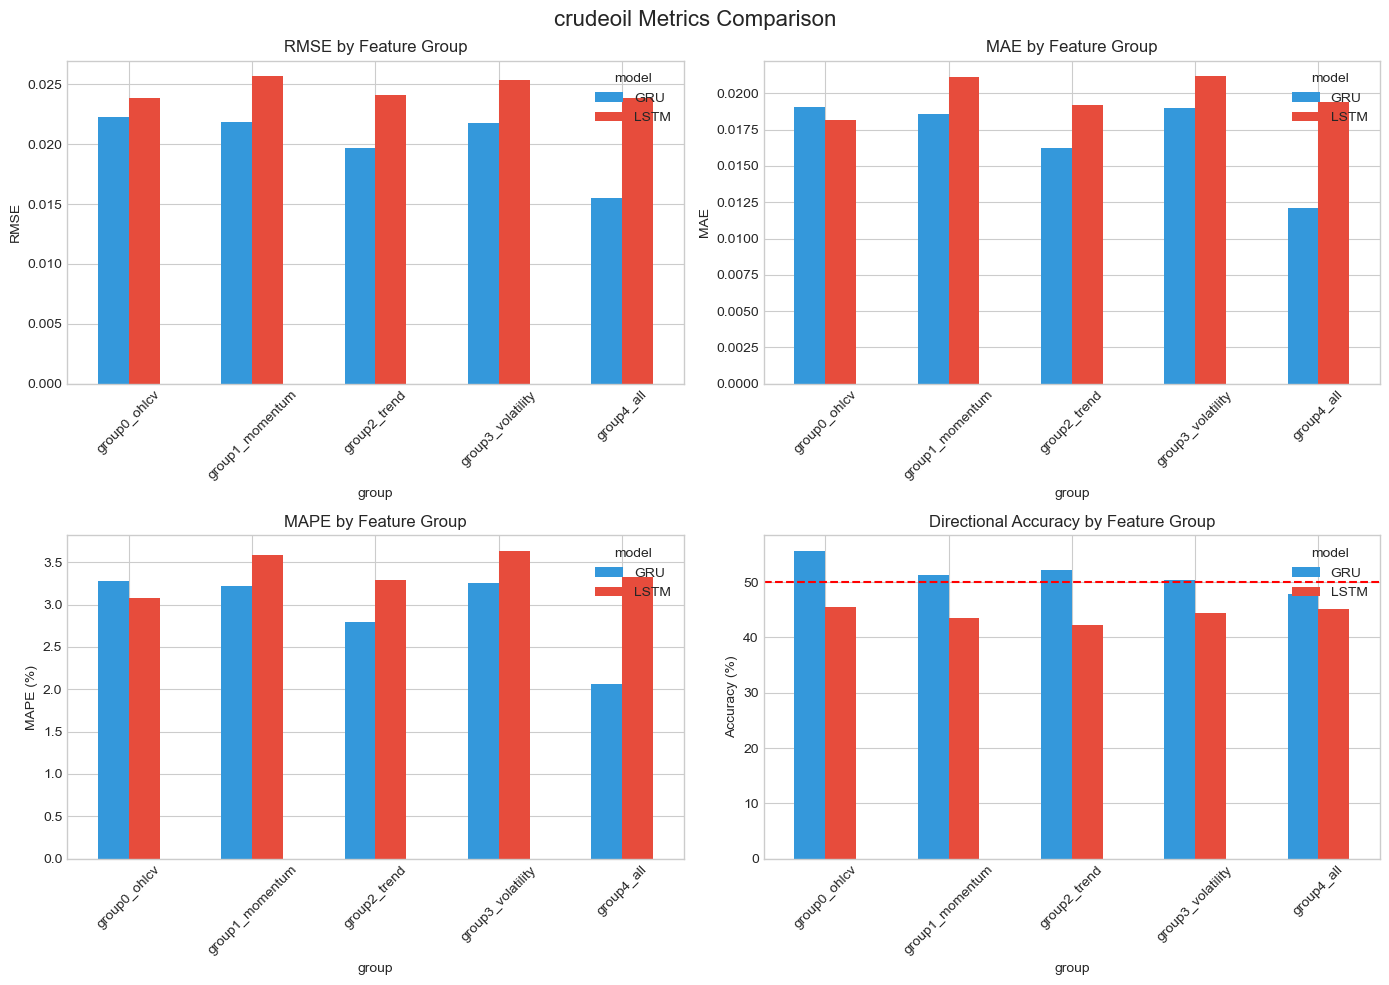

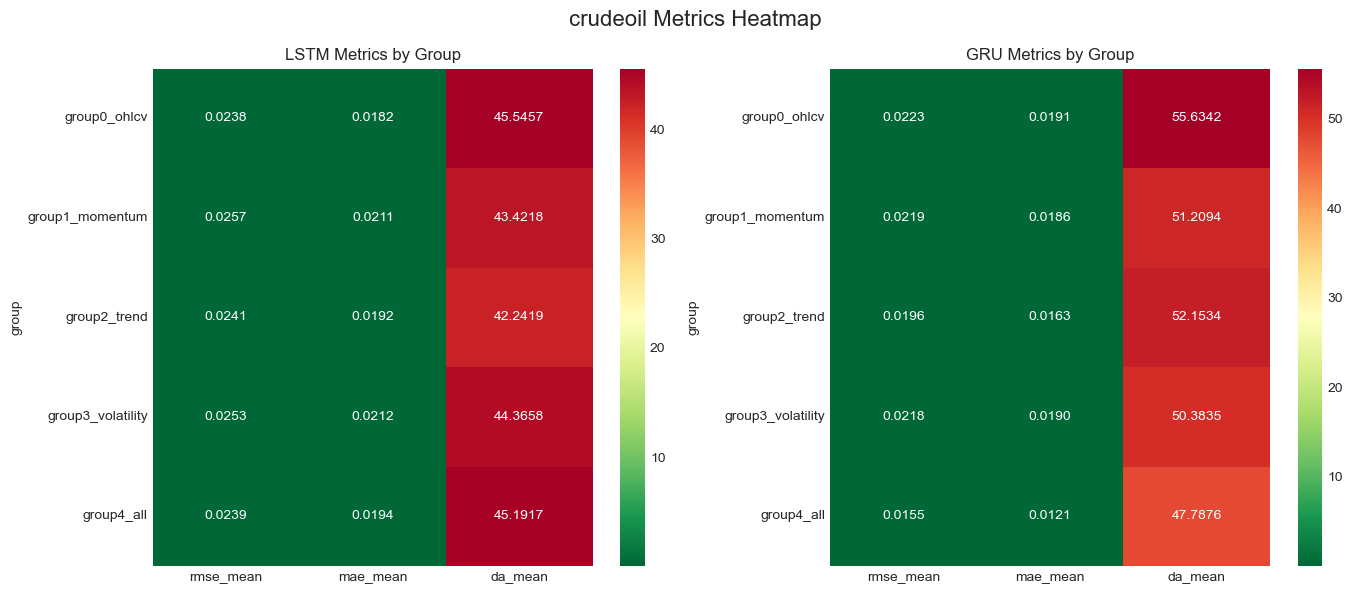


Metrics for gold:


,asset,model,group,rmse_ensemble,rmse_mean,rmse_std,mae_ensemble,mae_mean,mae_std,mape_ensemble,mape_mean,mape_std,da_ensemble,da_mean,da_std
0,gold,LSTM,group0_ohlcv,0.451684,0.452457,0.075948,0.376626,0.376673,0.068610,15.736052,15.739151,2.917324,58.875740,58.165680,0.762373
1,gold,LSTM,group1_momentum,0.784972,0.785157,0.081003,0.675038,0.675038,0.074414,28.437889,28.437890,3.231995,56.804734,55.562130,0.943040
2,gold,LSTM,group2_trend,0.832837,0.833056,0.061046,0.714127,0.714127,0.055625,30.019677,30.019677,2.421581,56.508876,55.798817,1.572228
3,gold,LSTM,group3_volatility,0.730097,0.731520,0.115429,0.622674,0.622674,0.117903,26.143614,26.143614,5.437206,58.284024,56.923077,0.480712
4,gold,LSTM,group4_all,0.866499,0.866958,0.109544,0.741991,0.741991,0.100555,31.146244,31.146244,4.368242,56.213018,54.792899,2.534037
5,gold,GRU,group0_ohlcv,0.640562,0.640695,0.086684,0.563145,0.563145,0.074106,24.052221,24.052221,3.107853,66.272189,66.094675,1.357082
6,gold,GRU,group1_momentum,0.737484,0.737575,0.105080,0.650524,0.650524,0.094591,27.824062,27.824063,4.077030,61.538462,60.532544,1.958928
7,gold,GRU,group2_trend,0.792063,0.792142,0.045823,0.699237,0.699237,0.042869,29.917860,29.917860,1.884994,59.467456,60.236686,2.356486
8,gold,GRU,group3_volatility,0.729190,0.729276,0.109162,0.642105,0.642105,0.096963,27.440219,27.440219,4.144856,64.497041,63.668639,2.112020
9,gold,GRU,group4_all,0.835101,0.835202,0.050179,0.736903,0.736903,0.046349,31.519365,31.519365,2.023809,56.804734,57.041420,1.288257


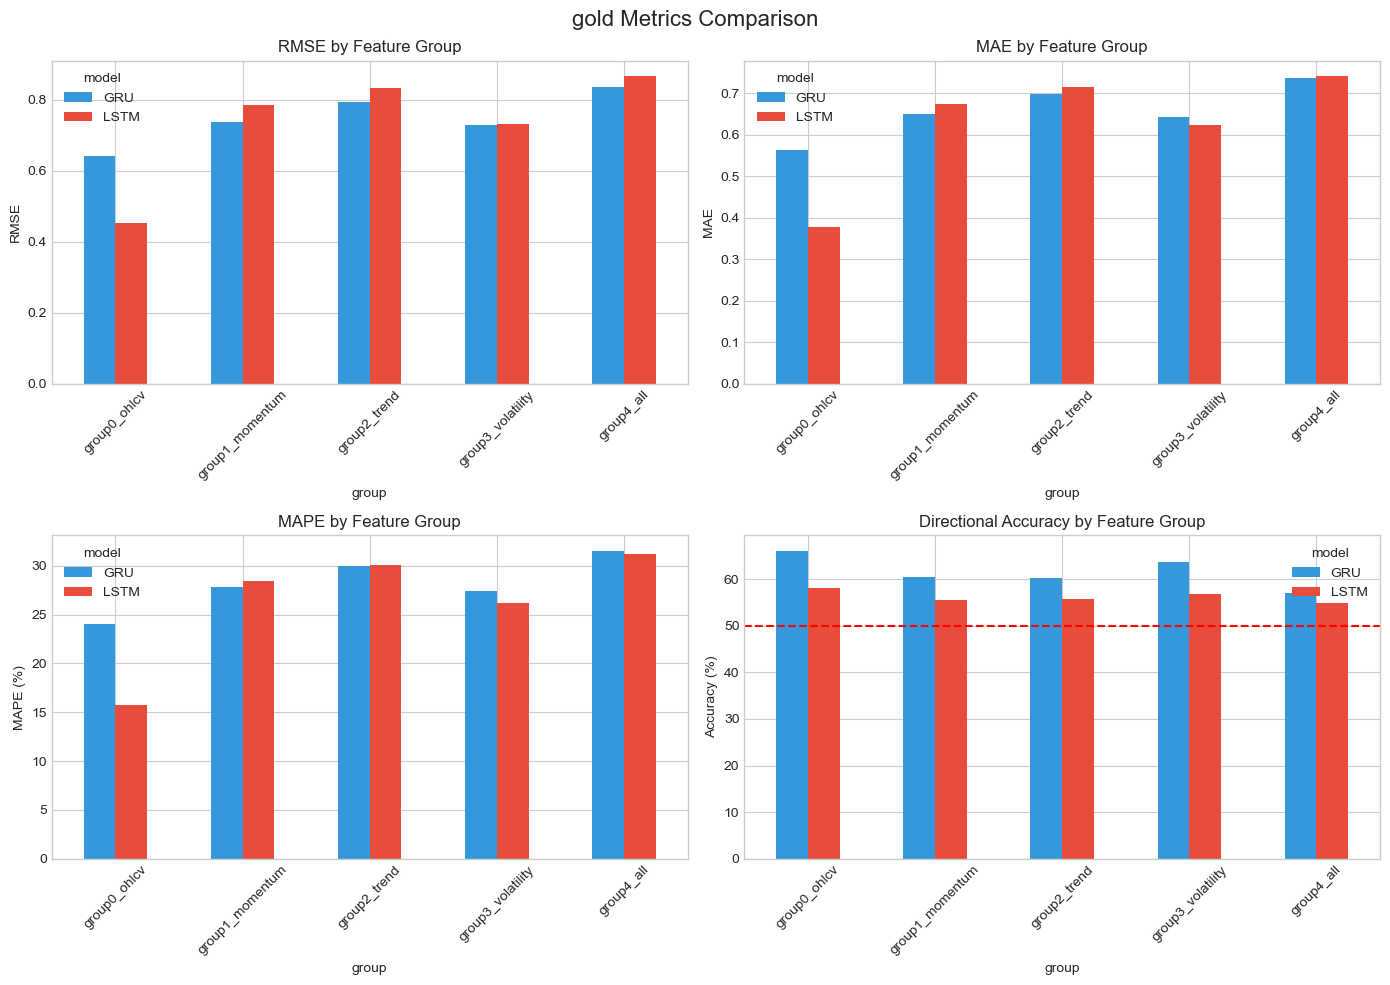

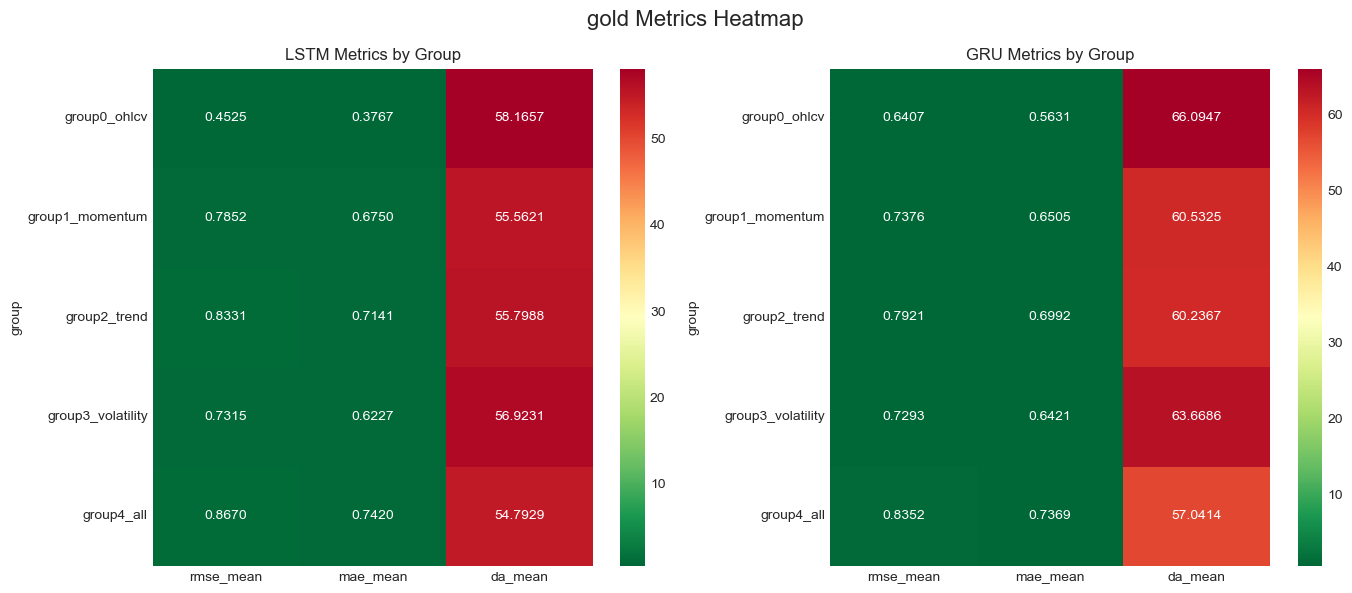


Metrics for bitcoin:


,asset,model,group,rmse_ensemble,rmse_mean,rmse_std,mae_ensemble,mae_mean,mae_std,mape_ensemble,mape_mean,mape_std,da_ensemble,da_mean,da_std
0,bitcoin,LSTM,group0_ohlcv,0.180760,0.181118,0.041220,0.170740,0.170855,0.040923,11.101220,11.110510,2.660823,54.441261,54.154728,1.102314
1,bitcoin,LSTM,group1_momentum,0.199123,0.199302,0.006018,0.187994,0.188017,0.005380,12.169410,12.171221,0.339796,51.002865,51.117479,0.388672
2,bitcoin,LSTM,group2_trend,0.299245,0.299656,0.037036,0.286635,0.286635,0.034762,18.607108,18.607108,2.212279,53.008596,52.550143,0.590007
3,bitcoin,LSTM,group3_volatility,0.208312,0.208612,0.038241,0.196366,0.196396,0.037866,12.698610,12.701114,2.468634,53.295129,52.378223,0.965748
4,bitcoin,LSTM,group4_all,0.348491,0.348737,0.031347,0.335605,0.335605,0.029784,21.835924,21.835924,1.912019,50.716332,50.773639,0.611867
5,bitcoin,GRU,group0_ohlcv,0.233579,0.233632,0.031338,0.224983,0.224983,0.030379,14.623947,14.623947,1.974269,67.048711,67.507163,2.739950
6,bitcoin,GRU,group1_momentum,0.269314,0.269435,0.036281,0.258416,0.258416,0.035034,16.764592,16.764592,2.270186,59.025788,58.452722,3.462191
7,bitcoin,GRU,group2_trend,0.284254,0.284411,0.018161,0.273372,0.273372,0.017874,17.754955,17.754955,1.173972,59.885387,59.312321,3.433617
8,bitcoin,GRU,group3_volatility,0.243201,0.243359,0.046307,0.233393,0.233393,0.044142,15.141389,15.141389,2.846844,62.750716,62.750716,2.742346
9,bitcoin,GRU,group4_all,0.306679,0.306744,0.007662,0.295938,0.295938,0.007770,19.257471,19.257471,0.513319,53.581662,53.696275,1.956833


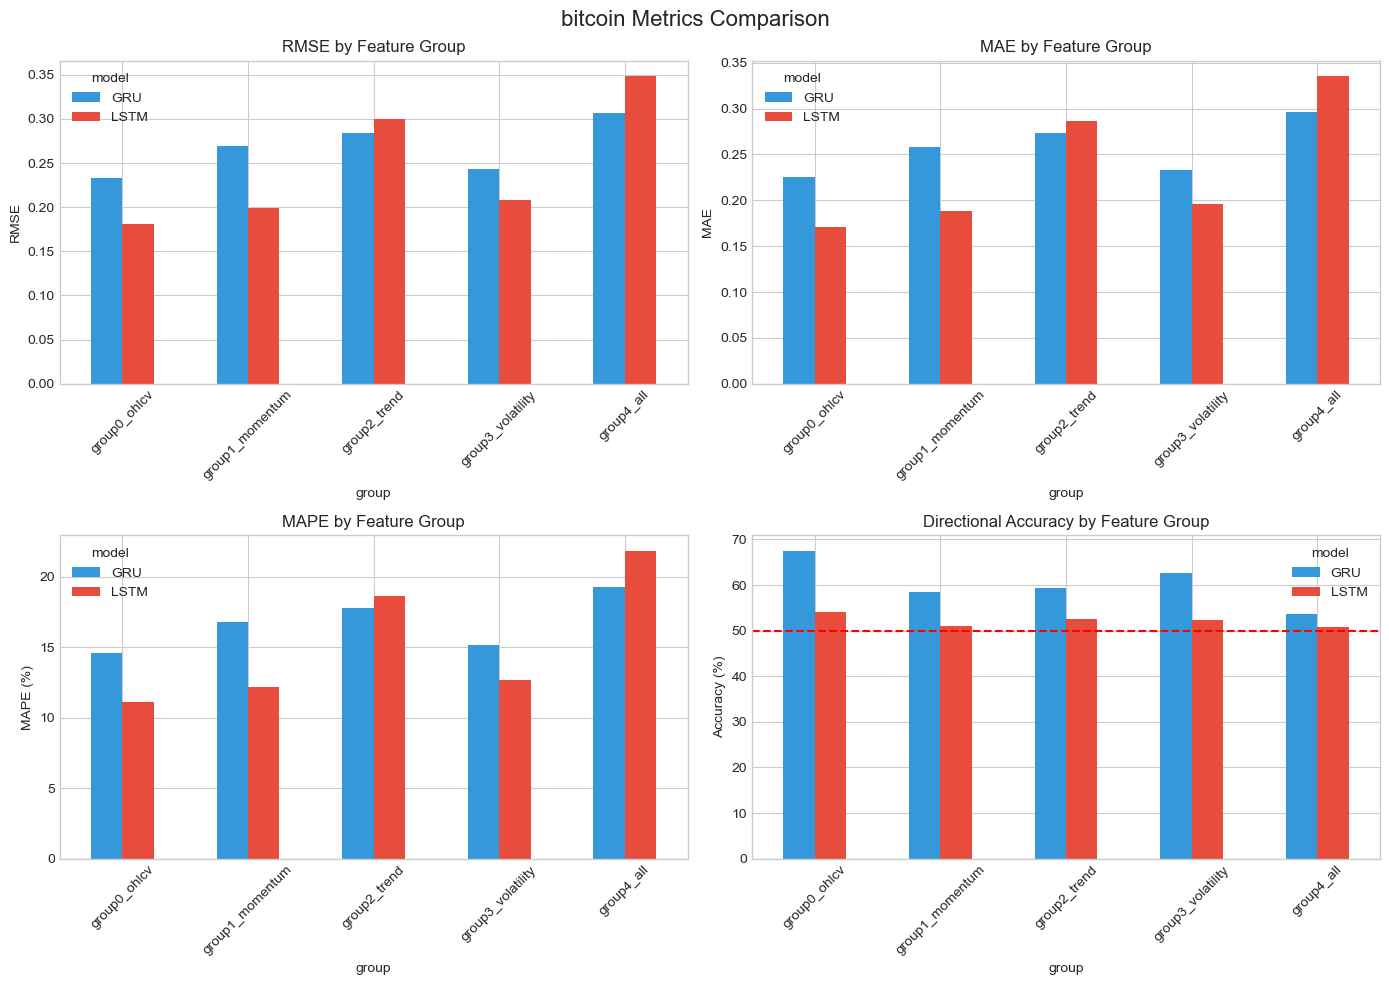

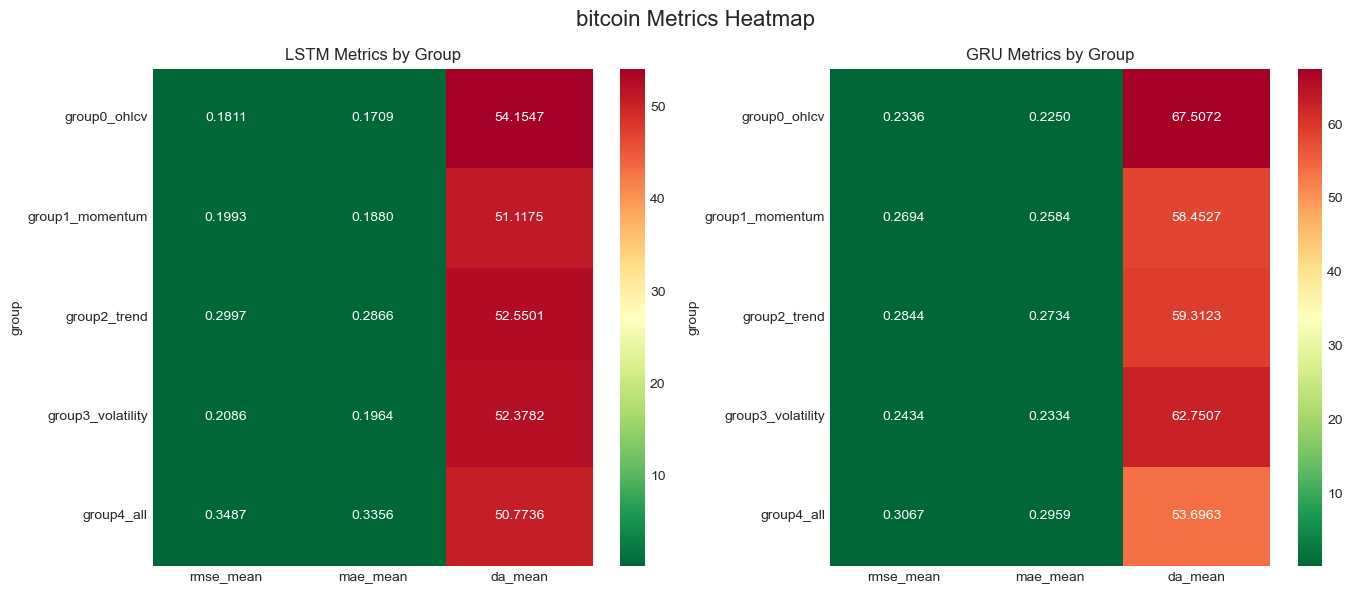


Metrics for ethereum:


,asset,model,group,rmse_ensemble,rmse_mean,rmse_std,mae_ensemble,mae_mean,mae_std,mape_ensemble,mape_mean,mape_std,da_ensemble,da_mean,da_std
0,ethereum,LSTM,group0_ohlcv,0.070255,0.070534,0.002127,0.056887,0.057108,0.001765,7.628730,7.667459,0.242340,52.564103,52.820513,0.745111
1,ethereum,LSTM,group1_momentum,0.071960,0.072171,0.005718,0.058699,0.058844,0.005484,7.884682,7.907772,0.735901,51.709402,51.965812,0.579686
2,ethereum,LSTM,group2_trend,0.067678,0.067964,0.003624,0.054686,0.054911,0.003324,7.353544,7.392763,0.456280,51.282051,52.478632,1.739059
3,ethereum,LSTM,group3_volatility,0.072702,0.073056,0.006035,0.060891,0.061088,0.005573,8.262333,8.291460,0.709957,52.991453,52.478632,1.060656
4,ethereum,LSTM,group4_all,0.068290,0.069398,0.009233,0.054045,0.055464,0.008382,7.144392,7.387320,1.087031,50.427350,50.598291,0.959399
5,ethereum,GRU,group0_ohlcv,0.046846,0.047227,0.006223,0.038586,0.039086,0.006434,5.142070,5.228025,0.922850,59.401709,59.658120,0.879968
6,ethereum,GRU,group1_momentum,0.048318,0.048907,0.005568,0.038757,0.039293,0.005305,5.067754,5.158640,0.718452,58.974359,56.923077,2.774818
7,ethereum,GRU,group2_trend,0.045161,0.045926,0.007089,0.036933,0.037631,0.007158,4.903992,5.019531,1.008317,59.401709,58.803419,1.495116
8,ethereum,GRU,group3_volatility,0.044425,0.045227,0.006304,0.036228,0.037052,0.006997,4.807077,4.947800,1.040772,58.547009,58.290598,2.270997
9,ethereum,GRU,group4_all,0.050591,0.050955,0.006454,0.041297,0.041542,0.005755,5.425710,5.466493,0.740758,57.264957,56.410256,1.666119


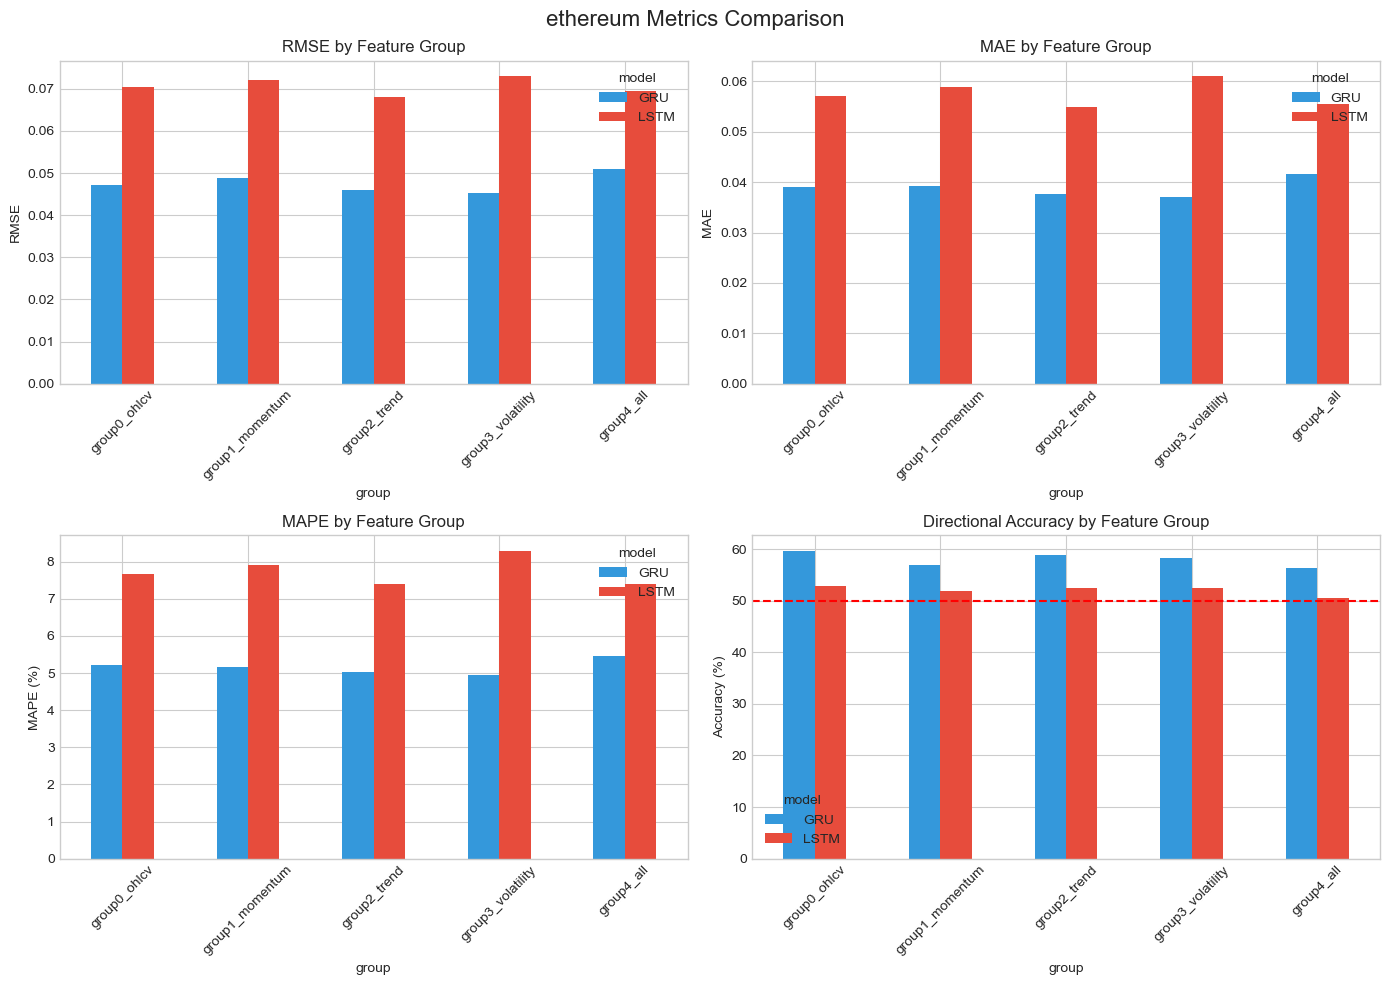

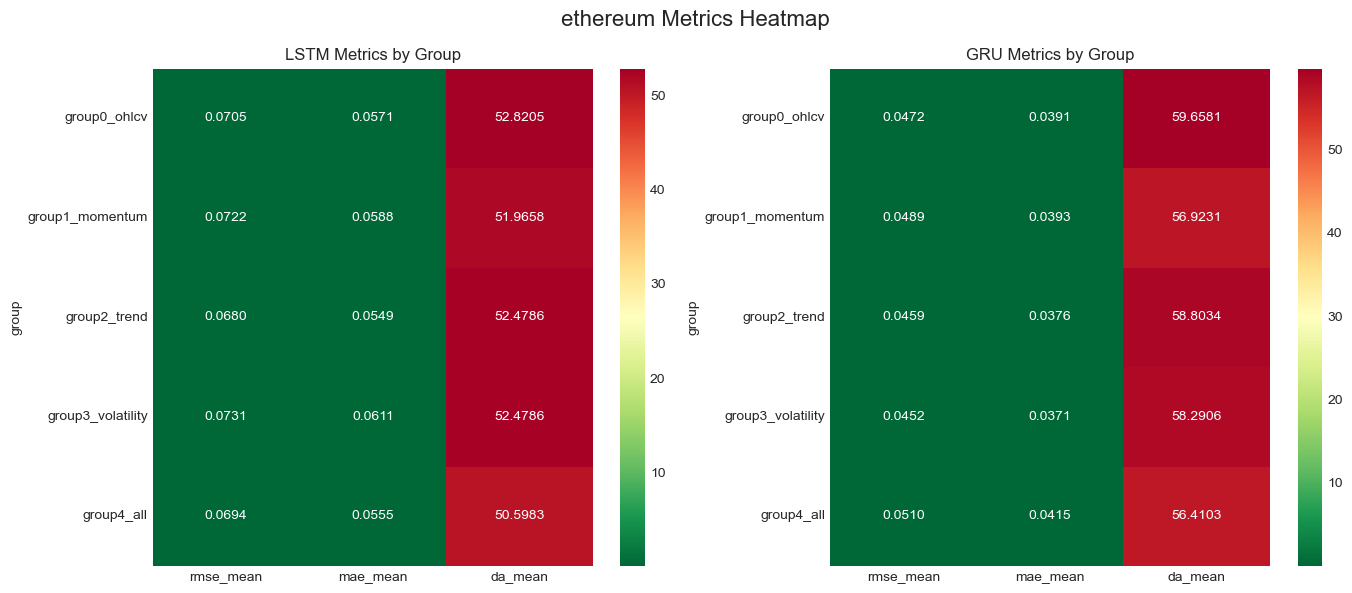


Metrics for apple:


,asset,model,group,rmse_ensemble,rmse_mean,rmse_std,mae_ensemble,mae_mean,mae_std,mape_ensemble,mape_mean,mape_std,da_ensemble,da_mean,da_std
0,apple,LSTM,group0_ohlcv,0.220114,0.220255,0.031911,0.207157,0.207221,0.030407,15.501288,15.507320,2.268553,53.392330,53.392330,0.618766
1,apple,LSTM,group1_momentum,0.252952,0.253035,0.025028,0.239817,0.239817,0.024067,17.977205,17.977205,1.804365,51.032448,51.386431,0.220747
2,apple,LSTM,group2_trend,0.221977,0.222202,0.031497,0.209549,0.209569,0.030329,15.703825,15.705768,2.271307,50.442478,51.032448,0.493605
3,apple,LSTM,group3_volatility,0.216233,0.216480,0.034222,0.204724,0.204788,0.033383,15.355920,15.362030,2.511325,53.982301,53.333333,1.924426
4,apple,LSTM,group4_all,0.242052,0.242222,0.035641,0.228962,0.229043,0.034182,17.161035,17.169362,2.566822,53.097345,51.799410,0.688018
5,apple,GRU,group0_ohlcv,0.175047,0.175145,0.014059,0.167060,0.167084,0.013547,12.562645,12.565100,1.016557,61.651917,61.474926,0.782684
6,apple,GRU,group1_momentum,0.192042,0.192202,0.022163,0.182426,0.182428,0.020314,13.688452,13.688696,1.496539,58.407080,57.463127,1.045430
7,apple,GRU,group2_trend,0.198144,0.198274,0.014316,0.188468,0.188482,0.014520,14.153283,14.154817,1.106938,56.932153,56.873156,1.662419
8,apple,GRU,group3_volatility,0.191453,0.191574,0.016321,0.181848,0.181848,0.015303,13.639398,13.639398,1.137094,59.882006,59.174041,1.715993
9,apple,GRU,group4_all,0.209161,0.209323,0.015664,0.198670,0.198675,0.014726,14.908815,14.909287,1.097349,55.457227,54.572271,1.237533


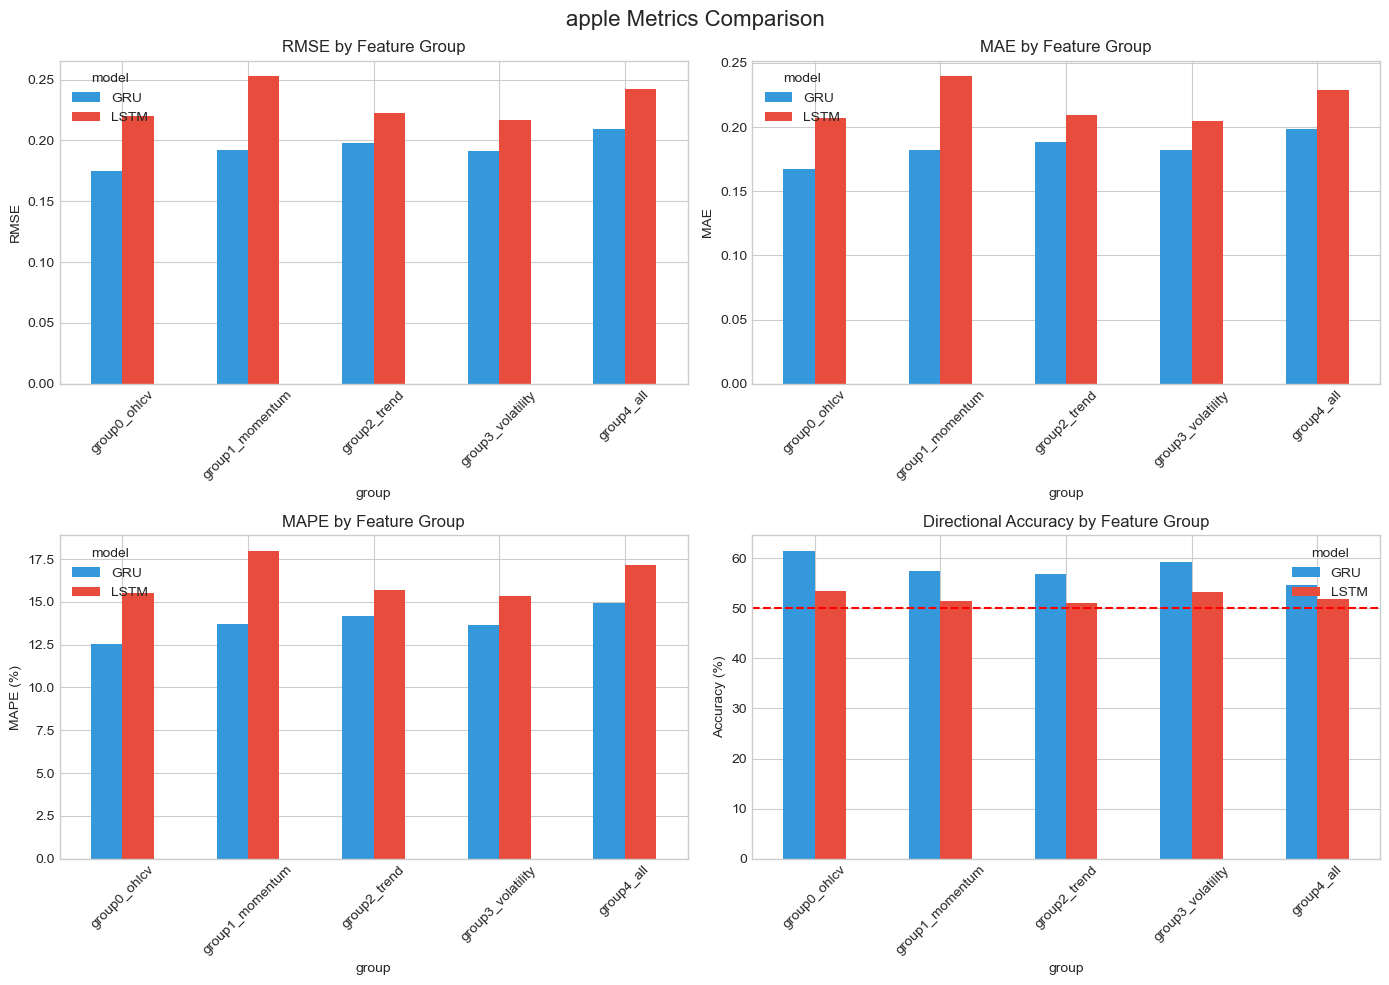

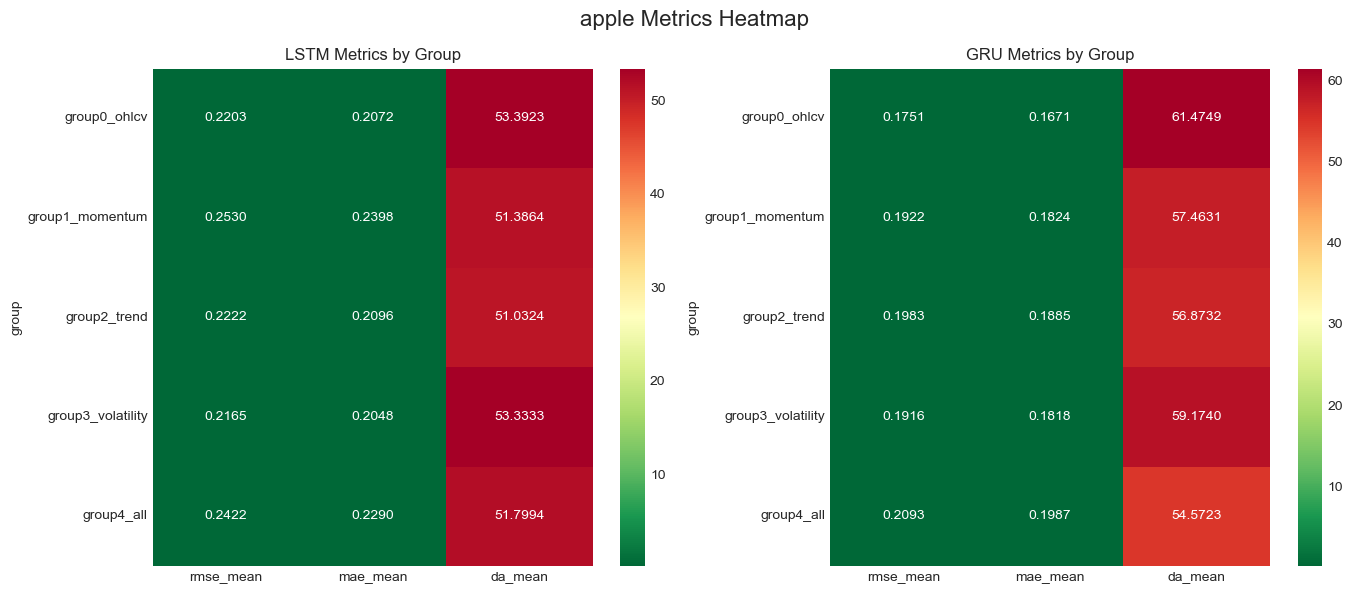


Metrics for microsoft:


,asset,model,group,rmse_ensemble,rmse_mean,rmse_std,mae_ensemble,mae_mean,mae_std,mape_ensemble,mape_mean,mape_std,da_ensemble,da_mean,da_std
0,microsoft,LSTM,group0_ohlcv,0.194906,0.195236,0.048146,0.183140,0.183171,0.045941,12.987503,12.990463,3.244279,51.327434,50.619469,0.514324
1,microsoft,LSTM,group1_momentum,0.212529,0.212815,0.036289,0.200523,0.200523,0.033203,14.221797,14.221797,2.314402,49.557522,49.026549,0.344009
2,microsoft,LSTM,group2_trend,0.245677,0.245897,0.037810,0.233247,0.233247,0.036776,16.589806,16.589806,2.629236,48.082596,48.908555,1.363330
3,microsoft,LSTM,group3_volatility,0.170575,0.171020,0.022899,0.157971,0.157971,0.020944,11.156752,11.156752,1.457211,48.967552,50.796460,1.214824
4,microsoft,LSTM,group4_all,0.238505,0.239081,0.042425,0.225566,0.225579,0.041477,16.027418,16.028638,2.972646,47.787611,47.964602,1.715993
5,microsoft,GRU,group0_ohlcv,0.193079,0.193196,0.015638,0.184750,0.184750,0.015552,13.170141,13.170141,1.123860,57.522124,56.637168,1.469015
6,microsoft,GRU,group1_momentum,0.213185,0.213332,0.022054,0.202934,0.202934,0.020030,14.428961,14.428961,1.391031,53.982301,53.923304,1.413469
7,microsoft,GRU,group2_trend,0.219385,0.219658,0.019842,0.208646,0.208646,0.019461,14.829914,14.829914,1.401783,52.212389,52.330383,1.522535
8,microsoft,GRU,group3_volatility,0.206690,0.206850,0.016694,0.197277,0.197277,0.015168,14.042768,14.042768,1.051446,54.572271,55.339233,2.065739
9,microsoft,GRU,group4_all,0.233989,0.234106,0.011234,0.223963,0.223963,0.010438,15.965469,15.965469,0.732453,49.262537,49.498525,0.707965


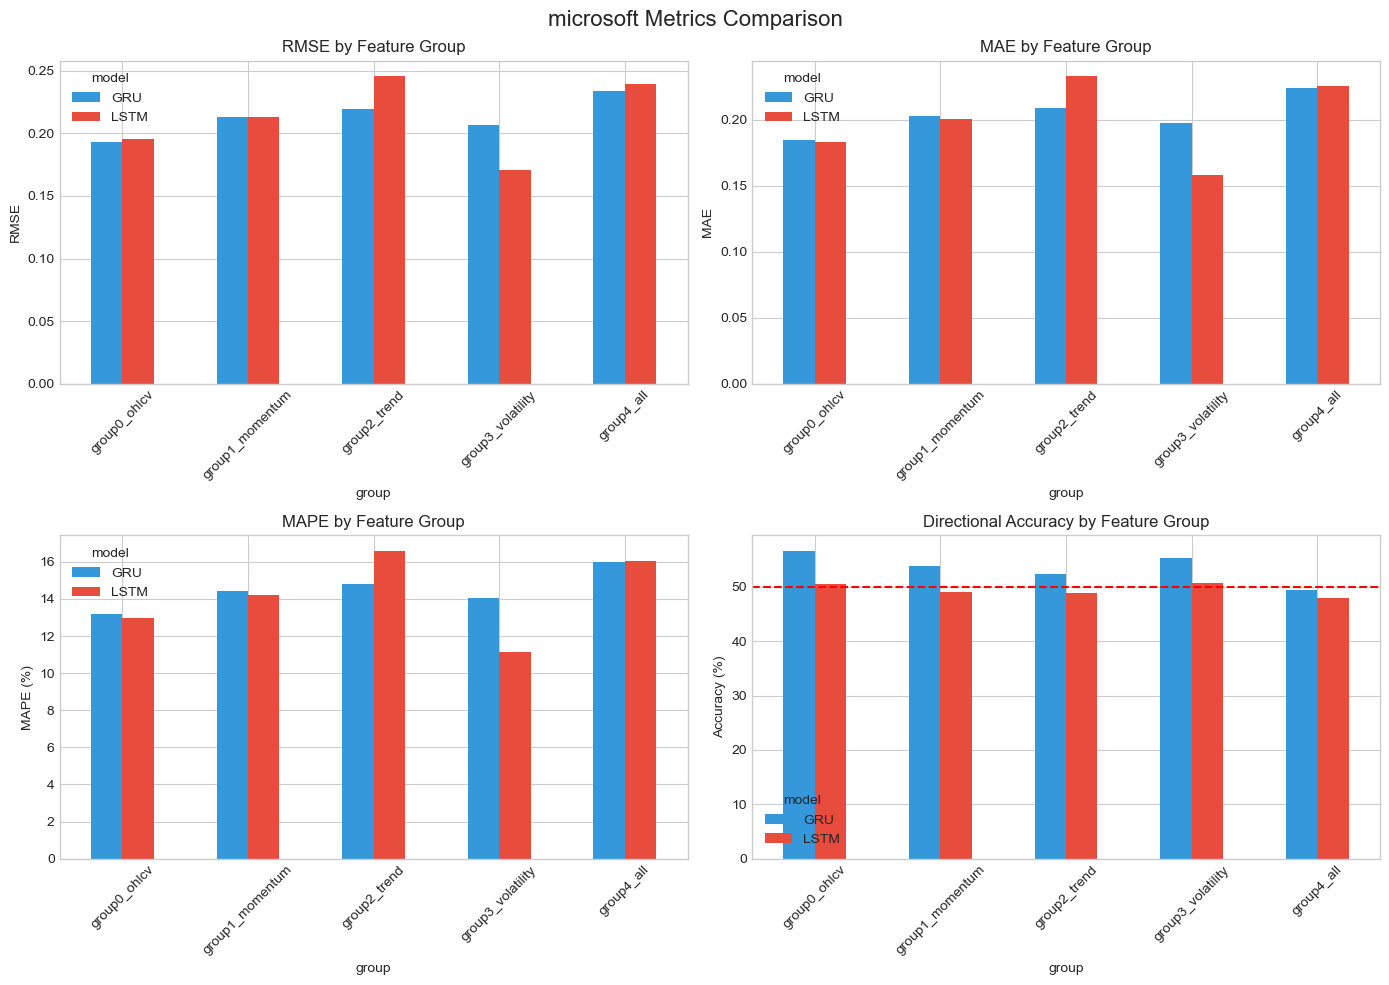

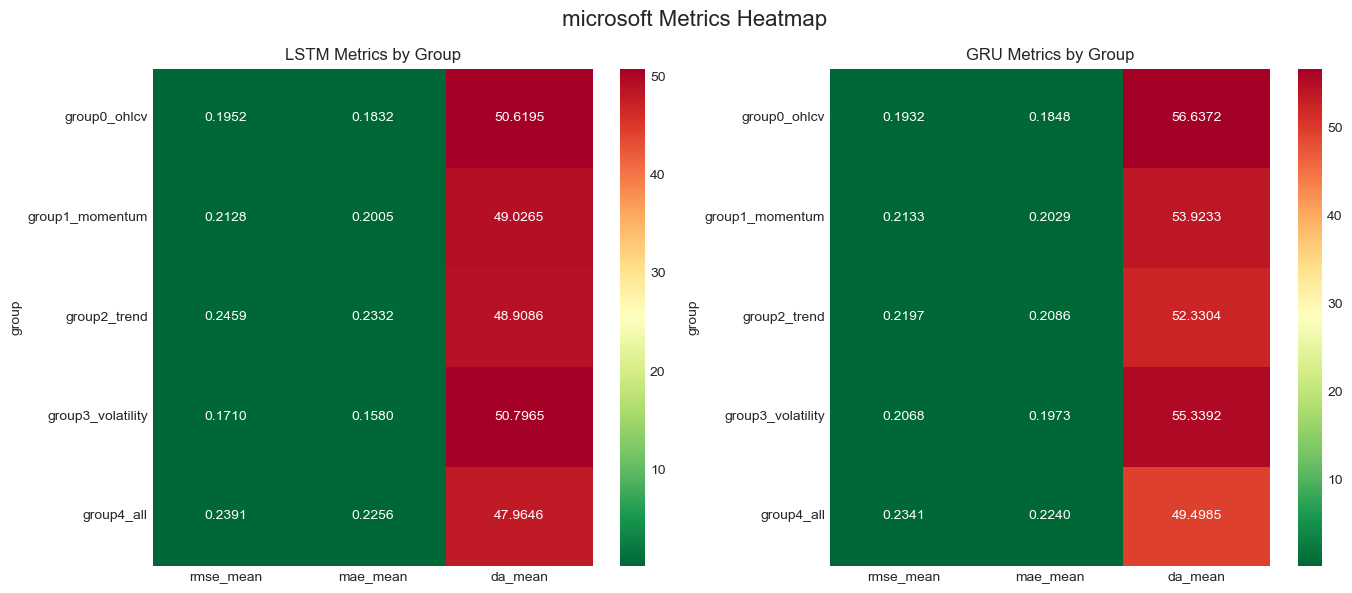


Metrics for eurusd:


,asset,model,group,rmse_ensemble,rmse_mean,rmse_std,mae_ensemble,mae_mean,mae_std,mape_ensemble,mape_mean,mape_std,da_ensemble,da_mean,da_std
0,eurusd,LSTM,group0_ohlcv,0.028281,0.028440,0.001794,0.023017,0.023211,0.001553,7.709795,7.809741,0.403180,46.175637,46.232295,0.330366
1,eurusd,LSTM,group1_momentum,0.027253,0.027489,0.001449,0.022694,0.022945,0.001452,7.487281,7.636588,0.454154,48.441926,47.365439,0.416344
2,eurusd,LSTM,group2_trend,0.029536,0.029950,0.003540,0.024166,0.024747,0.003225,8.033388,8.302118,0.936489,46.458924,47.195467,0.684592
3,eurusd,LSTM,group3_volatility,0.025434,0.025636,0.001551,0.020825,0.021000,0.001530,6.977559,7.069512,0.425570,46.458924,47.308782,0.620649
4,eurusd,LSTM,group4_all,0.025675,0.026047,0.002915,0.021166,0.021396,0.002786,7.198291,7.289203,0.780567,48.725212,48.215297,0.828824
5,eurusd,GRU,group0_ohlcv,0.024521,0.024558,0.000836,0.021236,0.021285,0.000965,7.032107,7.059780,0.353535,52.691218,51.104816,0.772702
6,eurusd,GRU,group1_momentum,0.020622,0.024564,0.004788,0.017386,0.021344,0.004824,5.725191,7.284332,1.257232,50.991501,50.368272,1.271952
7,eurusd,GRU,group2_trend,0.024698,0.025274,0.001670,0.021236,0.021941,0.001631,6.995500,7.429950,0.466956,49.291785,49.575071,0.537498
8,eurusd,GRU,group3_volatility,0.019078,0.021136,0.004900,0.015893,0.017943,0.004813,5.420568,6.183741,1.422785,49.008499,49.405099,1.236115
9,eurusd,GRU,group4_all,0.017699,0.019108,0.004293,0.014652,0.015863,0.004312,5.129068,5.653194,1.362910,49.575071,49.745042,1.236115


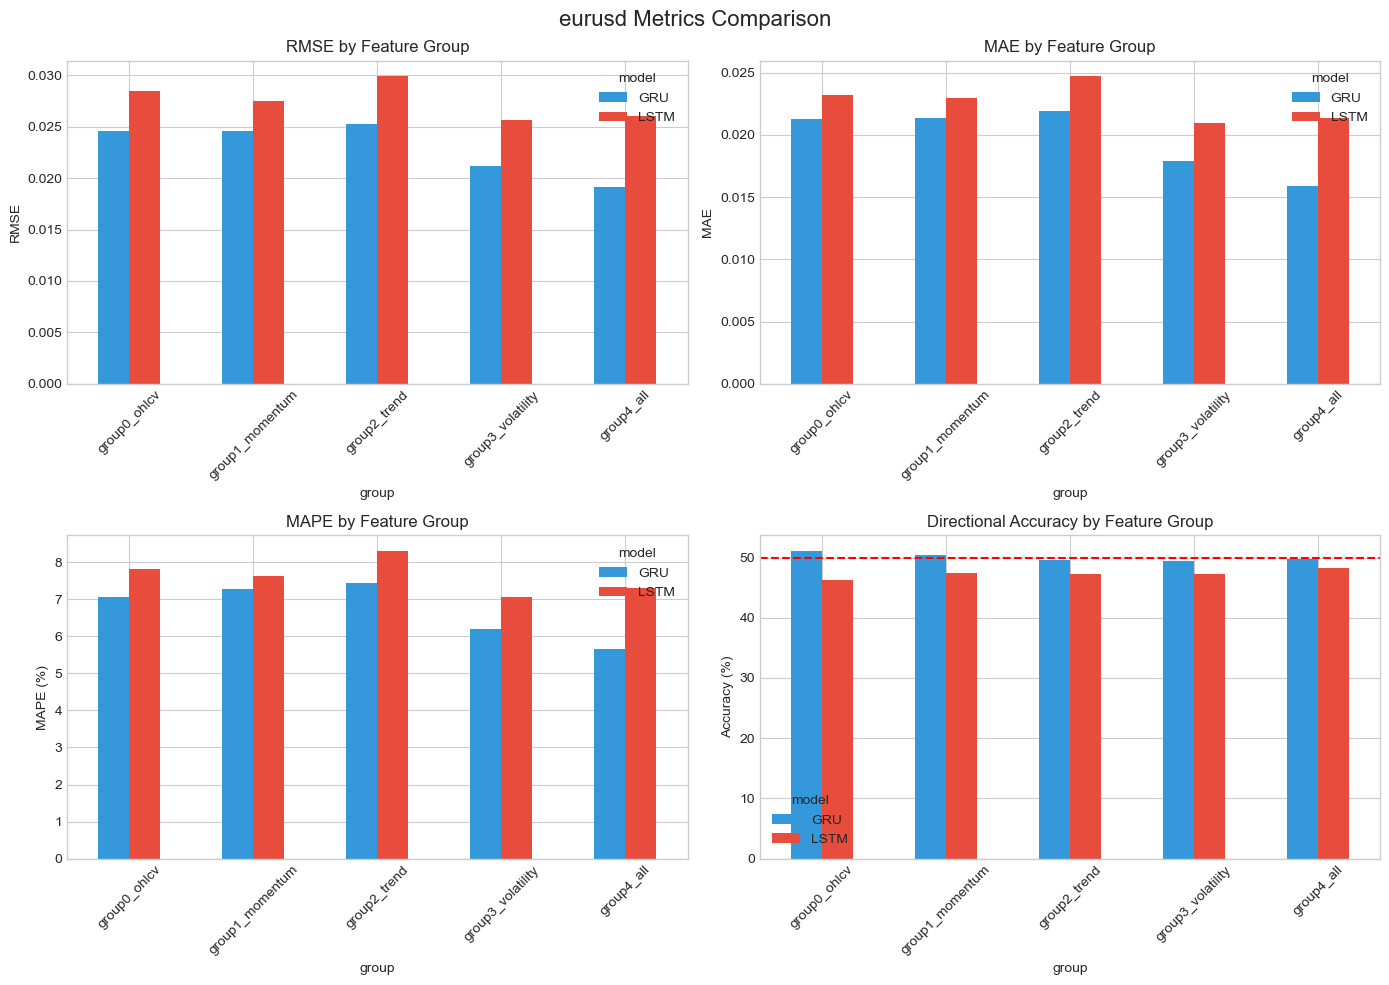

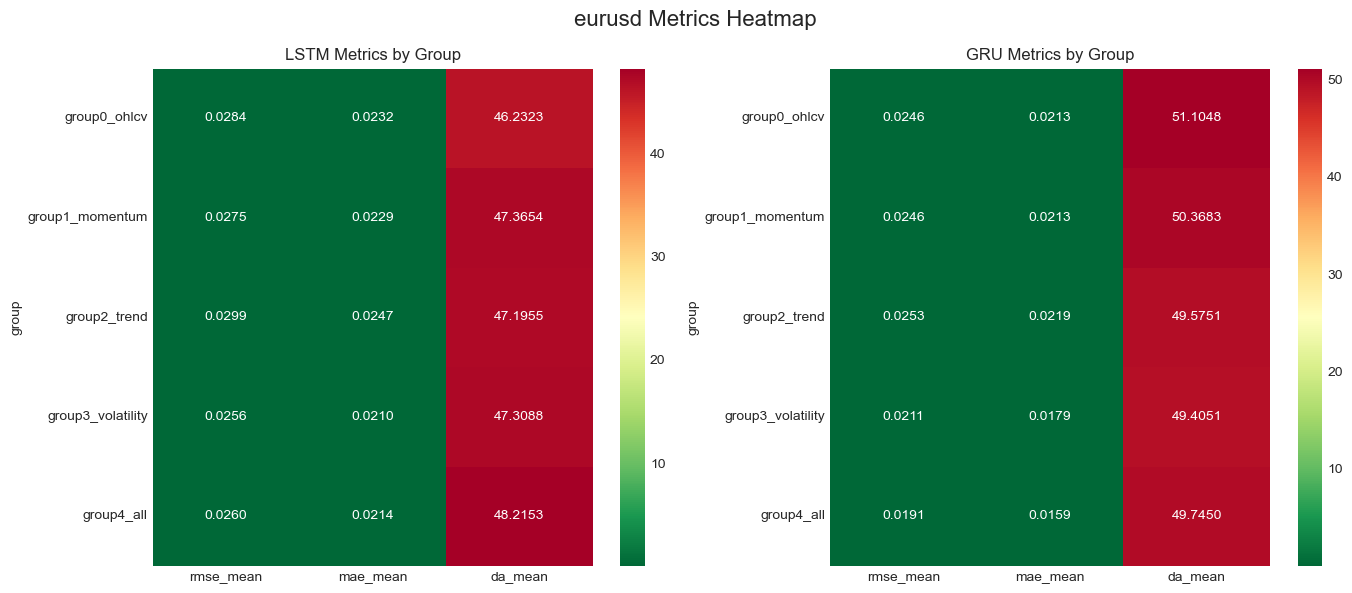


Metrics for usdjpy:


,asset,model,group,rmse_ensemble,rmse_mean,rmse_std,mae_ensemble,mae_mean,mae_std,mape_ensemble,mape_mean,mape_std,da_ensemble,da_mean,da_std
0,usdjpy,LSTM,group0_ohlcv,0.043902,0.045572,0.010267,0.037777,0.040150,0.010843,3.792440,4.036949,1.089726,51.274788,50.538244,0.924051
1,usdjpy,LSTM,group1_momentum,0.053192,0.053994,0.011864,0.049235,0.049965,0.012647,4.907992,4.987866,1.285244,48.441926,49.518414,1.220434
2,usdjpy,LSTM,group2_trend,0.051576,0.052835,0.018346,0.047647,0.048870,0.019171,4.765404,4.897618,1.935884,50.424929,50.651558,0.630908
3,usdjpy,LSTM,group3_volatility,0.044316,0.045300,0.007005,0.039088,0.039672,0.006174,3.882683,3.943937,0.595996,49.858357,50.821530,0.924051
4,usdjpy,LSTM,group4_all,0.071920,0.072964,0.009648,0.068889,0.069021,0.010107,6.921681,6.934884,1.023644,52.407932,50.878187,0.832688
5,usdjpy,GRU,group0_ohlcv,0.088114,0.088176,0.010510,0.086435,0.086435,0.010358,8.659715,8.659715,1.028440,54.107649,54.220963,2.109293
6,usdjpy,GRU,group1_momentum,0.088654,0.088790,0.016451,0.086774,0.086774,0.016261,8.684215,8.684215,1.618968,50.424929,50.254958,0.729977
7,usdjpy,GRU,group2_trend,0.084308,0.084478,0.017953,0.082890,0.082890,0.017591,8.320450,8.320450,1.747575,51.558074,51.501416,1.152804
8,usdjpy,GRU,group3_volatility,0.086686,0.086800,0.015803,0.084502,0.084502,0.015649,8.443347,8.443347,1.564156,52.407932,51.274788,0.716663
9,usdjpy,GRU,group4_all,0.101902,0.102028,0.012200,0.100487,0.100487,0.012142,10.096092,10.096092,1.228697,51.558074,49.971671,1.483943


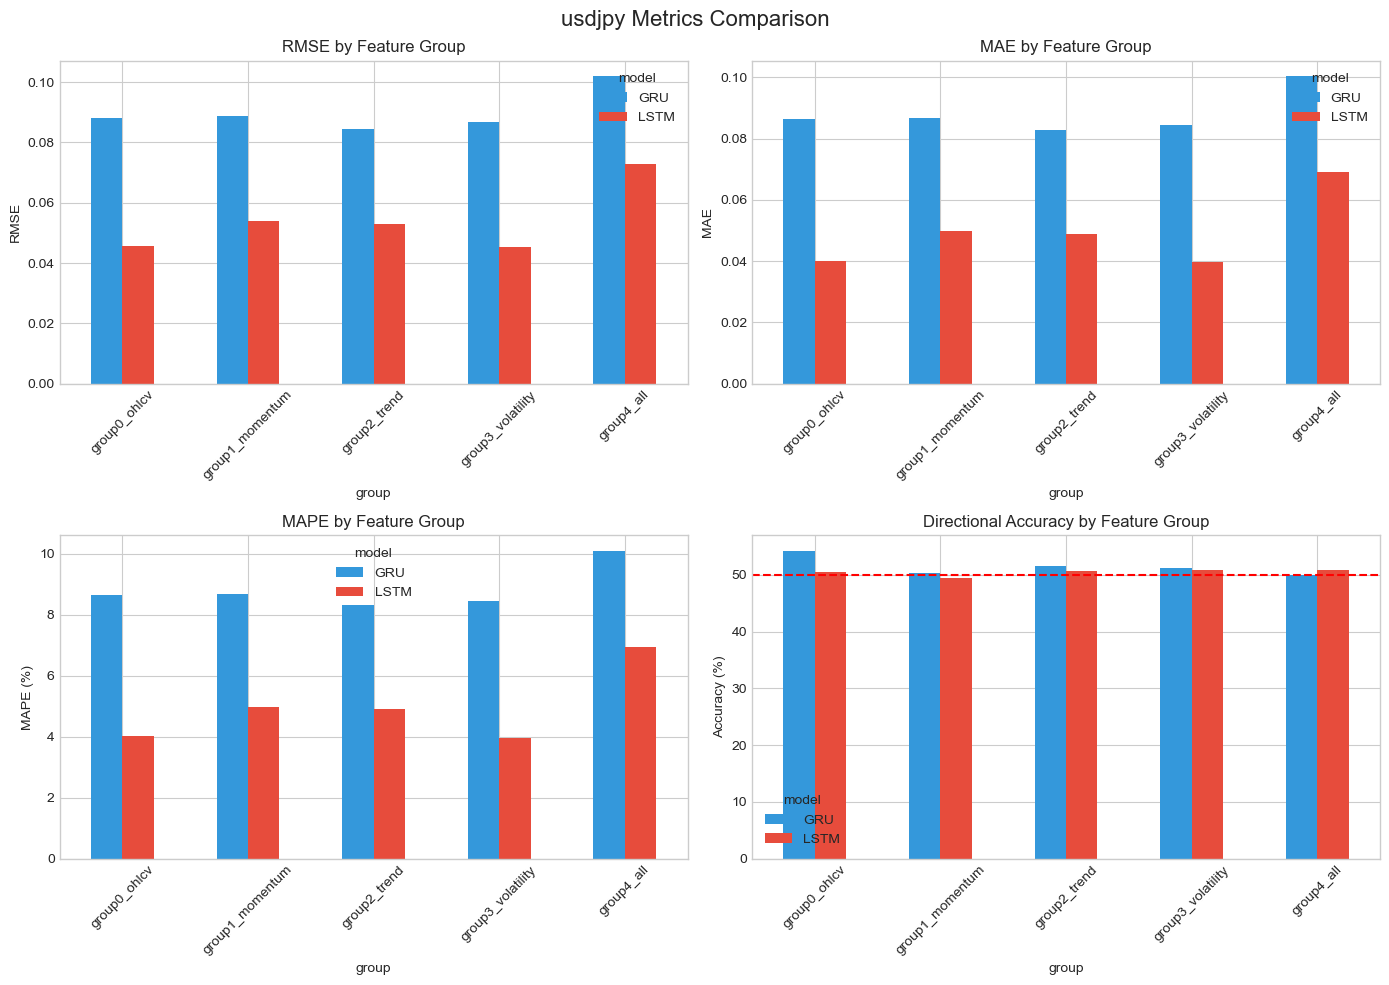

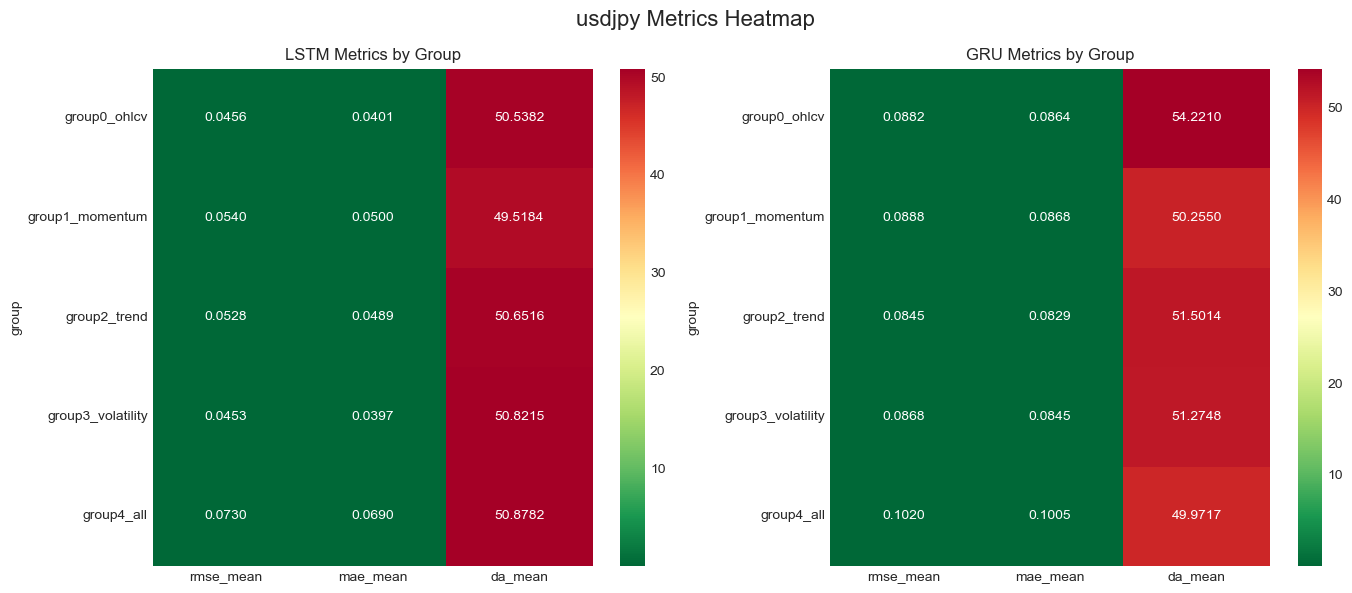


Metrics for nasdaq:


,asset,model,group,rmse_ensemble,rmse_mean,rmse_std,mae_ensemble,mae_mean,mae_std,mape_ensemble,mape_mean,mape_std,da_ensemble,da_mean,da_std
0,nasdaq,LSTM,group0_ohlcv,0.171791,0.172444,0.019561,0.159225,0.159368,0.020356,12.103682,12.117510,1.591466,55.752212,55.280236,0.760124
1,nasdaq,LSTM,group1_momentum,0.193439,0.193747,0.016454,0.181050,0.181077,0.016121,13.789538,13.792300,1.243061,51.327434,51.032448,1.021859
2,nasdaq,LSTM,group2_trend,0.174266,0.174543,0.011204,0.162532,0.162545,0.011071,12.367525,12.368841,0.857602,48.672566,50.147493,0.834344
3,nasdaq,LSTM,group3_volatility,0.169896,0.170253,0.022128,0.159551,0.159563,0.021144,12.219644,12.220854,1.591494,52.212389,51.622419,0.894735
4,nasdaq,LSTM,group4_all,0.207151,0.207290,0.018796,0.192913,0.192944,0.017216,14.675747,14.679116,1.295170,49.852507,50.206490,0.507512
5,nasdaq,GRU,group0_ohlcv,0.151595,0.151877,0.011658,0.143202,0.143302,0.011963,10.948758,10.959166,0.939687,56.637168,57.463127,0.433538
6,nasdaq,GRU,group1_momentum,0.163869,0.164088,0.014662,0.153791,0.153846,0.012977,11.722213,11.727814,0.963208,51.032448,52.035398,1.287164
7,nasdaq,GRU,group2_trend,0.174072,0.174440,0.012527,0.163254,0.163271,0.012902,12.442421,12.444225,1.014504,53.392330,52.684366,1.880517
8,nasdaq,GRU,group3_volatility,0.161505,0.161731,0.010418,0.152948,0.152995,0.010161,11.698590,11.703426,0.784725,56.342183,55.575221,1.015024
9,nasdaq,GRU,group4_all,0.174335,0.174527,0.009816,0.163961,0.163969,0.009861,12.515236,12.516099,0.773618,51.622419,50.855457,1.245942


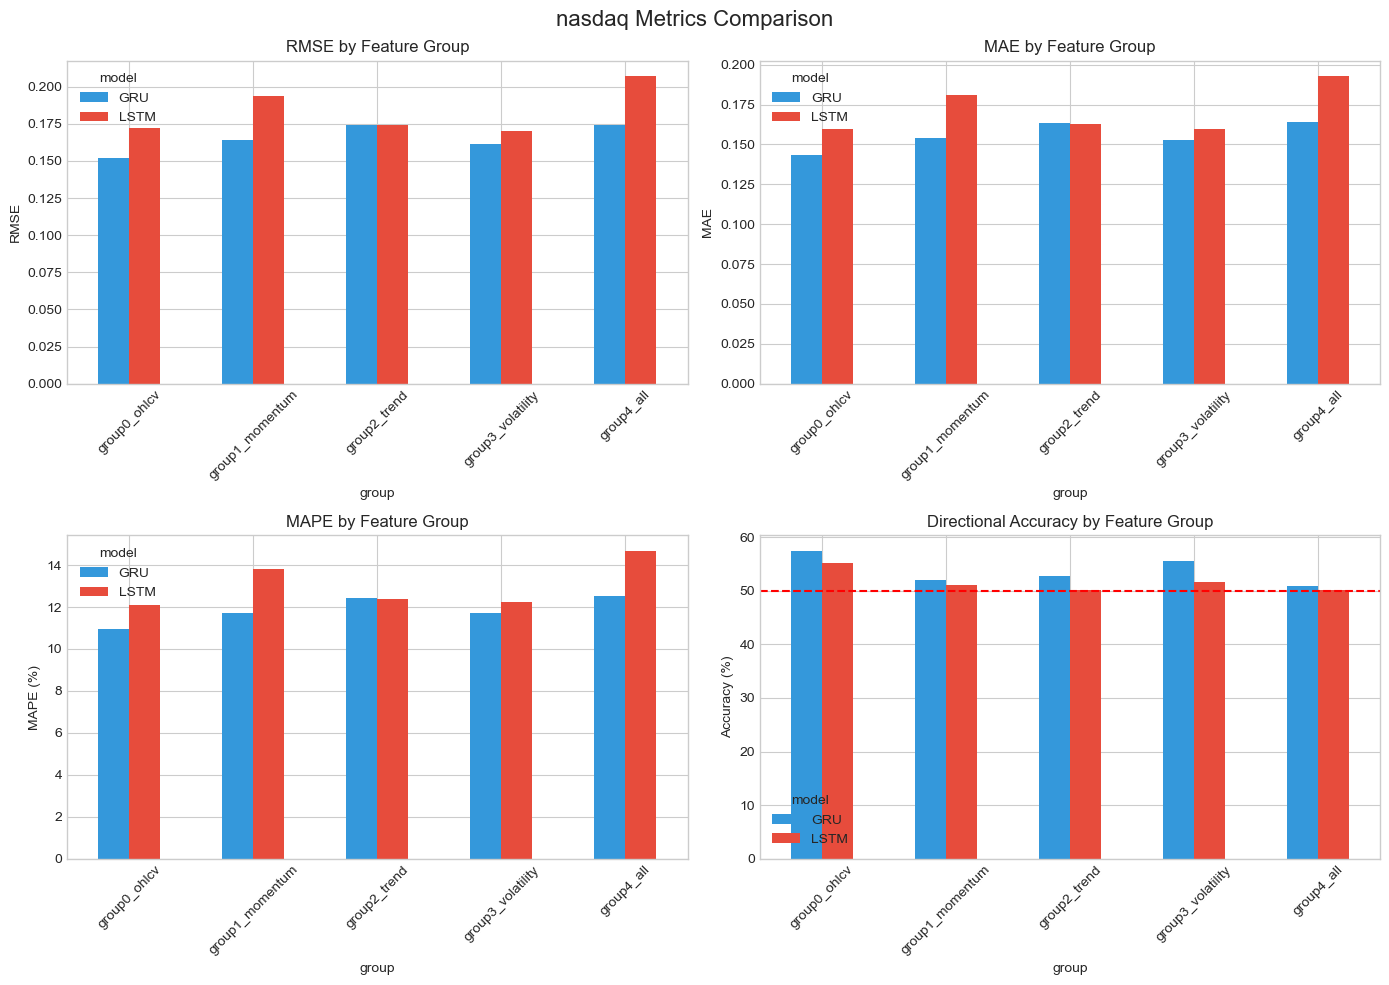

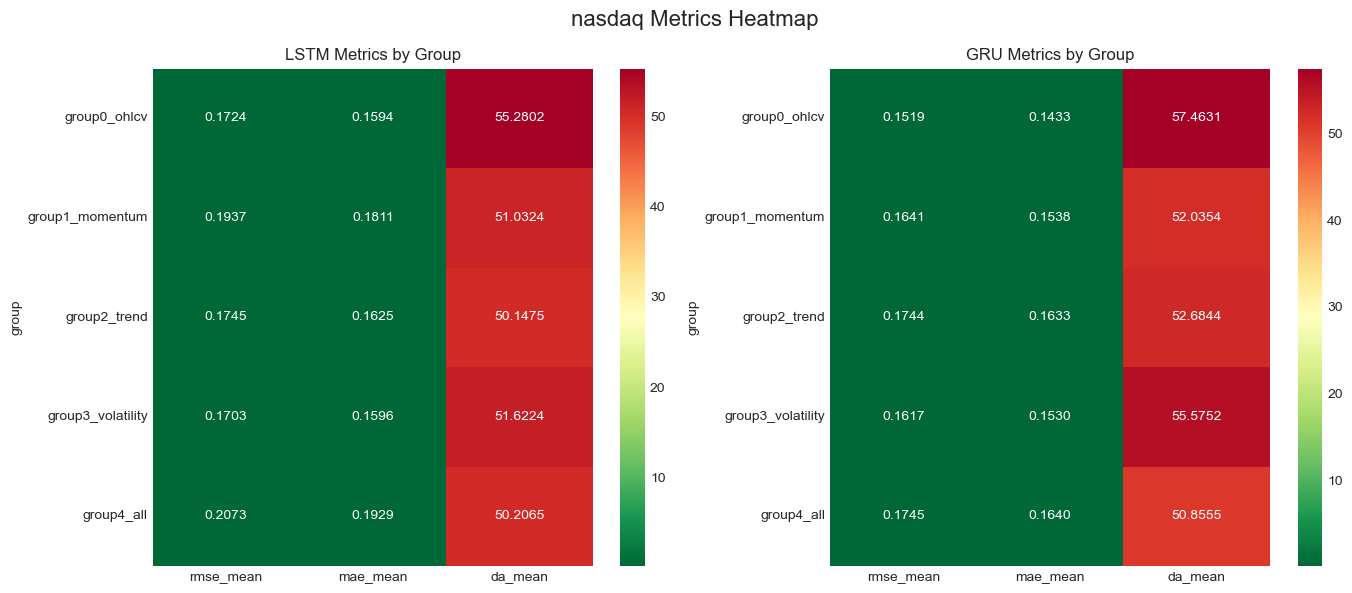


Metrics for sp500:


,asset,model,group,rmse_ensemble,rmse_mean,rmse_std,mae_ensemble,mae_mean,mae_std,mape_ensemble,mape_mean,mape_std,da_ensemble,da_mean,da_std
0,sp500,LSTM,group0_ohlcv,0.178836,0.178998,0.011228,0.171598,0.171615,0.011848,12.535550,12.537049,0.889112,59.292035,59.174041,0.886920
1,sp500,LSTM,group1_momentum,0.202428,0.202537,0.018341,0.193486,0.193523,0.017389,14.111884,14.115374,1.264958,50.147493,50.324484,1.188758
2,sp500,LSTM,group2_trend,0.193621,0.193735,0.018438,0.185935,0.185935,0.017935,13.581438,13.581438,1.311777,56.932153,56.932153,1.637102
3,sp500,LSTM,group3_volatility,0.189700,0.190198,0.045547,0.182783,0.182838,0.043894,13.378529,13.383618,3.184513,55.457227,56.519174,0.906330
4,sp500,LSTM,group4_all,0.224901,0.224999,0.023873,0.215098,0.215136,0.022781,15.695215,15.698862,1.659868,50.442478,49.793510,0.940258
5,sp500,GRU,group0_ohlcv,0.168351,0.168392,0.011128,0.163871,0.163877,0.010599,12.027545,12.028109,0.768139,58.407080,58.171091,0.800275
6,sp500,GRU,group1_momentum,0.178279,0.178386,0.019370,0.172815,0.172815,0.018163,12.660714,12.660714,1.308135,54.572271,54.808260,2.055605
7,sp500,GRU,group2_trend,0.180598,0.180697,0.020543,0.174192,0.174192,0.019918,12.736783,12.736783,1.455745,56.047198,54.749263,2.148335
8,sp500,GRU,group3_volatility,0.182394,0.182526,0.017535,0.176992,0.177025,0.017312,12.971197,12.974302,1.274245,55.457227,55.929204,1.499500
9,sp500,GRU,group4_all,0.191615,0.191754,0.008109,0.184823,0.184852,0.007981,13.520328,13.523160,0.580266,53.392330,52.448378,1.171058


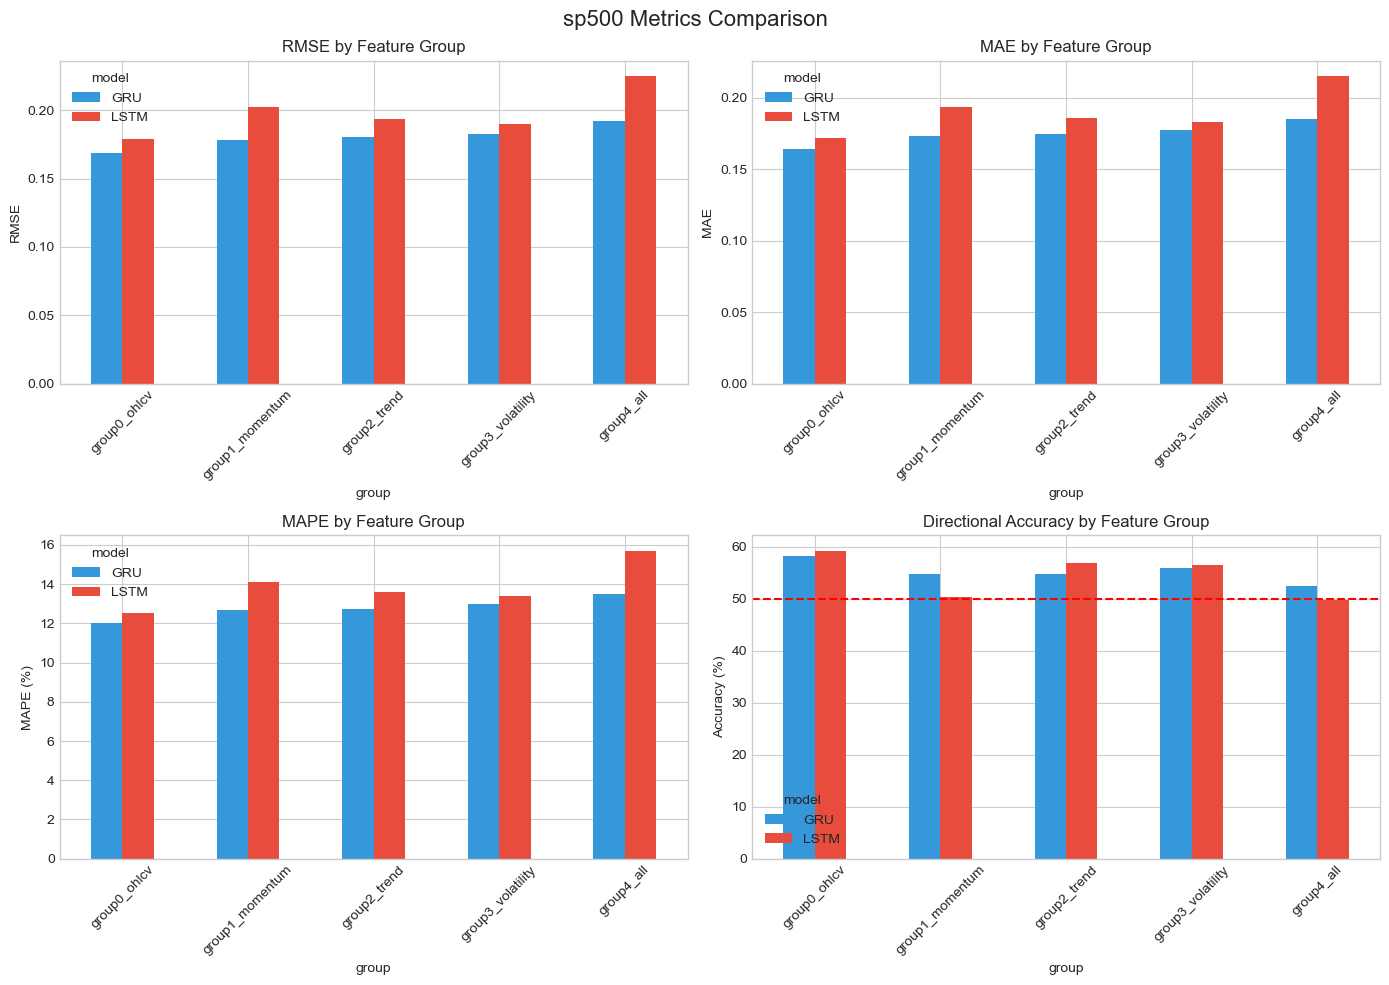

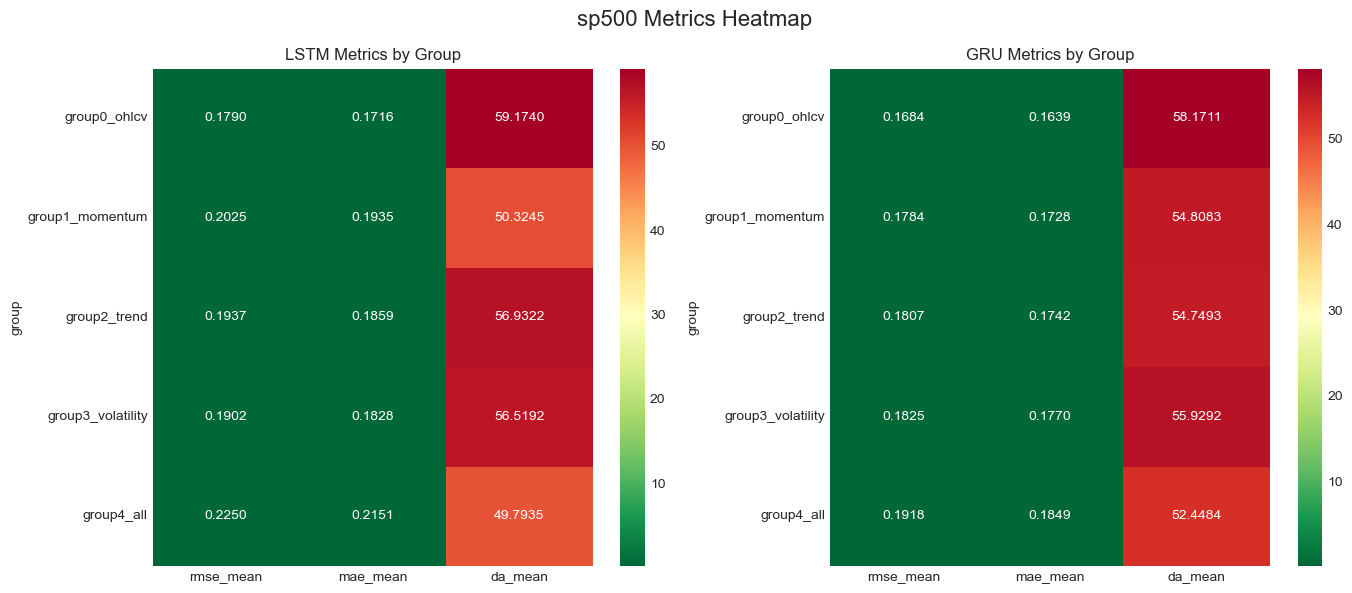

In [8]:


for asset in assets:
    asset_metrics = [m for m in all_metrics if m['asset'] == asset]
    if not asset_metrics:
        continue
        
    metrics_df = pd.DataFrame(asset_metrics)
    
    print(f"\nMetrics for {asset}:")
    display(metrics_df)
    
    # RMSE comparison bar plot
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # RMSE
    pivot_rmse = metrics_df.pivot(index='group', columns='model', values=rmse)
    pivot_rmse.plot(kind='bar', ax=axes[0, 0])
    axes[0, 0].set_title('RMSE by Feature Group')
    axes[0, 0].set_ylabel('RMSE')
    axes[0, 0].tick_params(axis='x', rotation=45)
    
    # MAE
    pivot_mae = metrics_df.pivot(index='group', columns='model', values=mae)
    pivot_mae.plot(kind='bar', ax=axes[0, 1])
    axes[0, 1].set_title('MAE by Feature Group')
    axes[0, 1].set_ylabel('MAE')
    axes[0, 1].tick_params(axis='x', rotation=45)
    
    # MAPE
    pivot_mape = metrics_df.pivot(index='group', columns='model', values=mape)
    pivot_mape.plot(kind='bar', ax=axes[1, 0])
    axes[1, 0].set_title('MAPE by Feature Group')
    axes[1, 0].set_ylabel('MAPE (%)')
    axes[1, 0].tick_params(axis='x', rotation=45)
    
    # Directional Accuracy
    pivot_da = metrics_df.pivot(index='group', columns='model', values=directional_accuracy)
    pivot_da.plot(kind='bar', ax=axes[1, 1])
    axes[1, 1].axhline(50, color='r', linestyle='--', label='Random')
    axes[1, 1].set_title('Directional Accuracy by Feature Group')
    axes[1, 1].set_ylabel('Accuracy (%)')
    axes[1, 1].tick_params(axis='x', rotation=45)
    
    plt.suptitle(f'{asset} Metrics Comparison', fontsize=16)
    plt.tight_layout()
    
    # Save figure
    asset_config = config.get_asset_config(asset)
    category = asset_config['category']
    figures_dir = config.get_path('results') / category / asset / 'figures'
    figures_dir.mkdir(parents=True, exist_ok=True)
    plt.savefig(figures_dir / 'metrics_comparison.png', dpi=300)
    plt.show()
    
    # Heatmap of metrics
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    # LSTM metrics heatmap
    lstm_metrics = metrics_df[metrics_df['model'] == 'LSTM'].set_index('group')[[rmse, mae, directional_accuracy]]
    sns.heatmap(lstm_metrics, annot=True, fmt='.4f', cmap='RdYlGn_r', ax=axes[0])
    axes[0].set_title('LSTM Metrics by Group')
    
    # GRU metrics heatmap
    gru_metrics = metrics_df[metrics_df['model'] == 'GRU'].set_index('group')[[rmse, mae, directional_accuracy]]
    sns.heatmap(gru_metrics, annot=True, fmt='.4f', cmap='RdYlGn_r', ax=axes[1])
    axes[1].set_title('GRU Metrics by Group')
    
    plt.suptitle(f'{asset} Metrics Heatmap', fontsize=16)
    plt.tight_layout()
    plt.savefig(figures_dir / 'metrics_heatmap.png', dpi=300)
    plt.show()

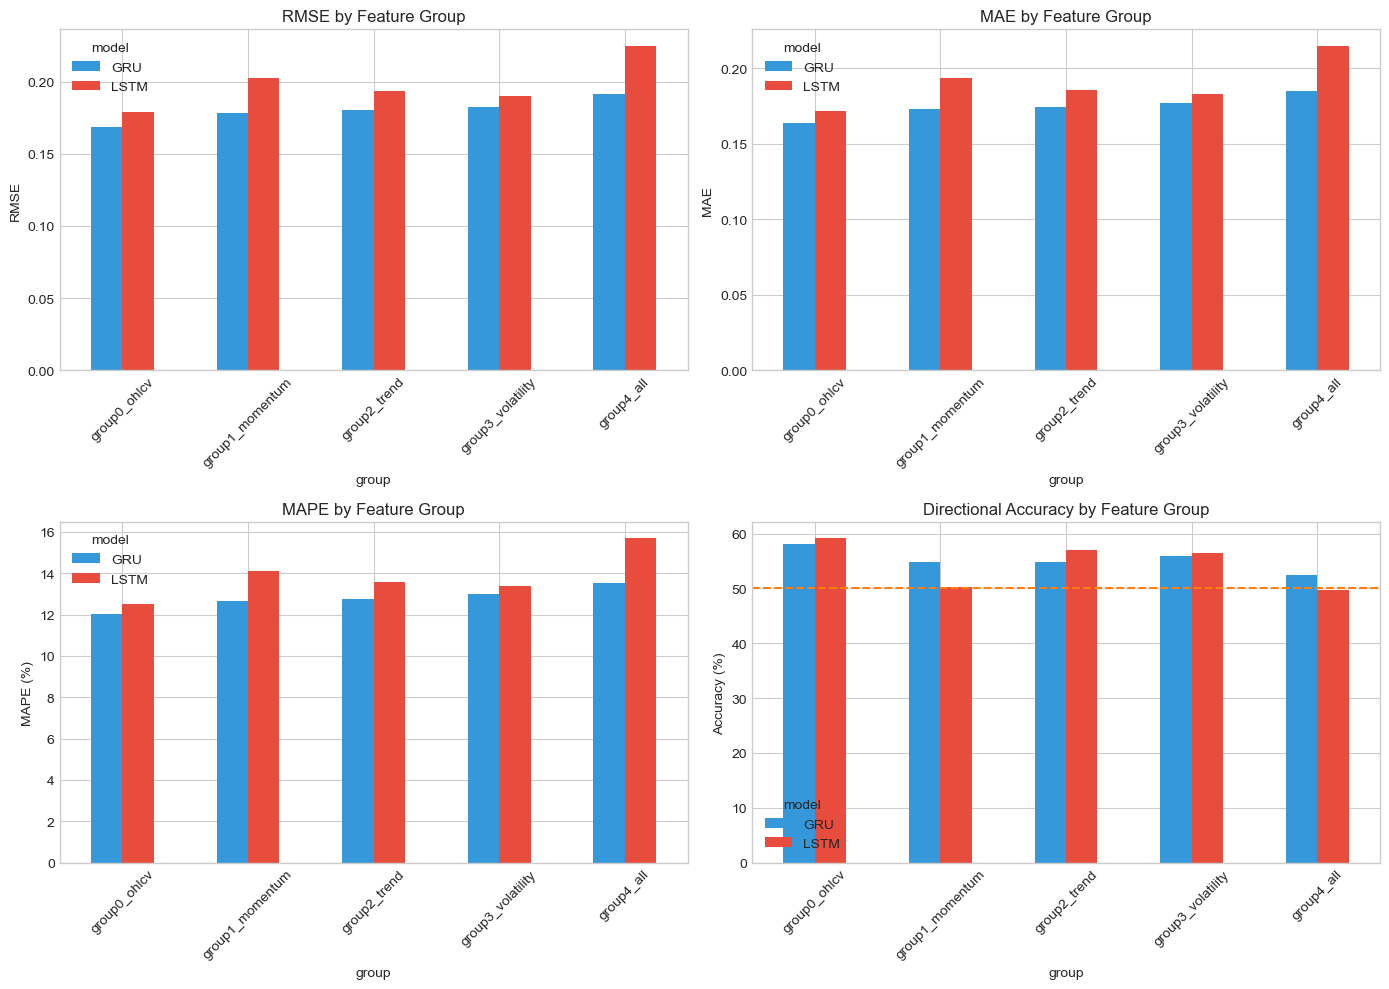

In [9]:
# RMSE comparison bar plot
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# RMSE
pivot_rmse = metrics_df.pivot(index='group', columns='model', values=rmse)
pivot_rmse.plot(kind='bar', ax=axes[0, 0])
axes[0, 0].set_title('RMSE by Feature Group')
axes[0, 0].set_ylabel('RMSE')
axes[0, 0].tick_params(axis='x', rotation=45)

# MAE
pivot_mae = metrics_df.pivot(index='group', columns='model', values=mae)
pivot_mae.plot(kind='bar', ax=axes[0, 1])
axes[0, 1].set_title('MAE by Feature Group')
axes[0, 1].set_ylabel('MAE')
axes[0, 1].tick_params(axis='x', rotation=45)

# MAPE
pivot_mape = metrics_df.pivot(index='group', columns='model', values=mape)
pivot_mape.plot(kind='bar', ax=axes[1, 0])
axes[1, 0].set_title('MAPE by Feature Group')
axes[1, 0].set_ylabel('MAPE (%)')
axes[1, 0].tick_params(axis='x', rotation=45)

# Directional Accuracy
pivot_da = metrics_df.pivot(index='group', columns='model', values=directional_accuracy)
pivot_da.plot(kind='bar', ax=axes[1, 1])
axes[1, 1].axhline(50, color='#ff7f0e', linestyle='--', label='Random')
axes[1, 1].set_title('Directional Accuracy by Feature Group')
axes[1, 1].set_ylabel('Accuracy (%)')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(config.get_path('results') / category / asset / 'figures' / 'metrics_comparison.png', dpi=300)
plt.show()

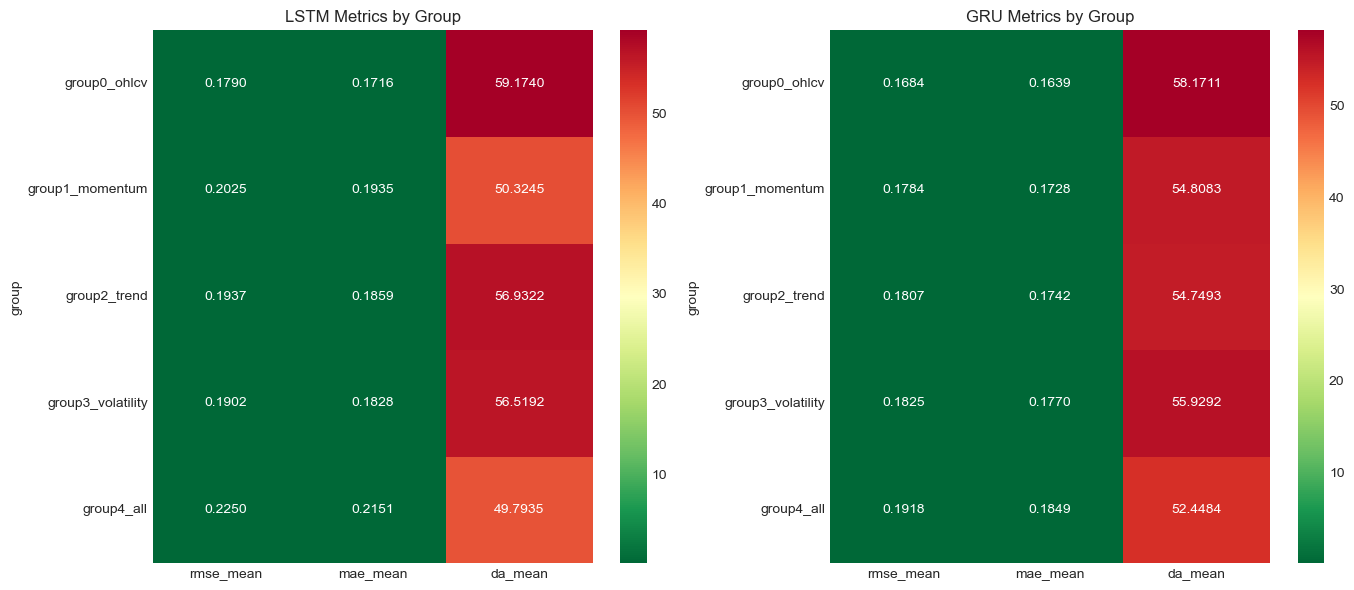

In [10]:
# Heatmap of metrics
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# LSTM metrics heatmap
lstm_metrics = metrics_df[metrics_df['model'] == 'LSTM'].set_index('group')[[rmse, mae, directional_accuracy]]
sns.heatmap(lstm_metrics, annot=True, fmt='.4f', cmap='RdYlGn_r', ax=axes[0])
axes[0].set_title('LSTM Metrics by Group')

# GRU metrics heatmap
gru_metrics = metrics_df[metrics_df['model'] == 'GRU'].set_index('group')[[rmse, mae, directional_accuracy]]
sns.heatmap(gru_metrics, annot=True, fmt='.4f', cmap='RdYlGn_r', ax=axes[1])
axes[1].set_title('GRU Metrics by Group')

plt.tight_layout()
plt.show()

## 4. Feature Group Impact Analysis

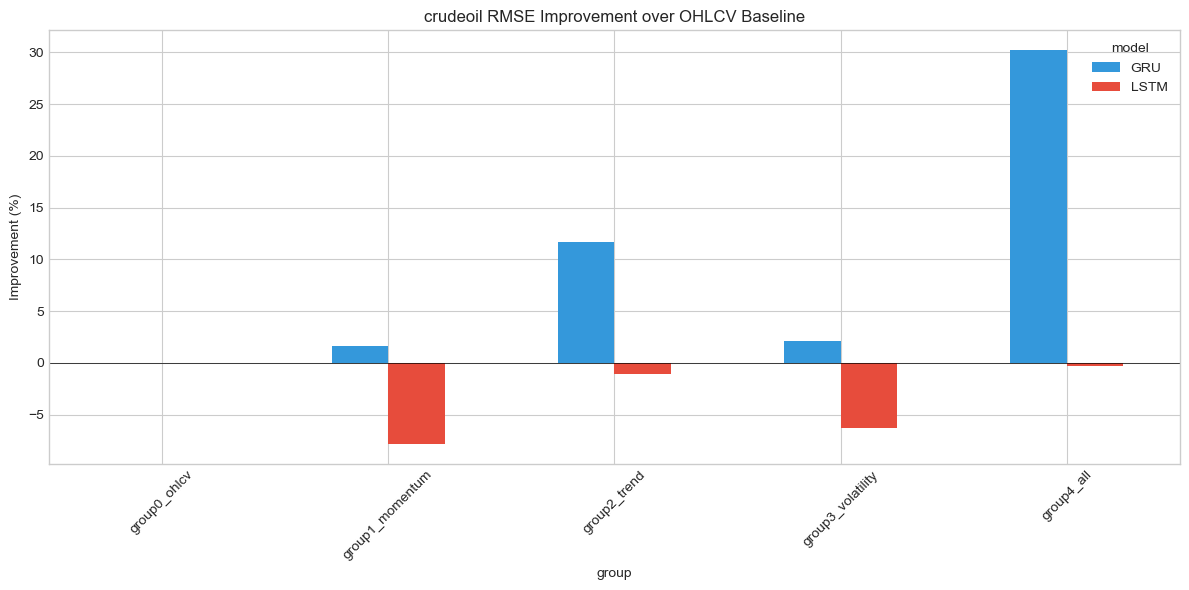

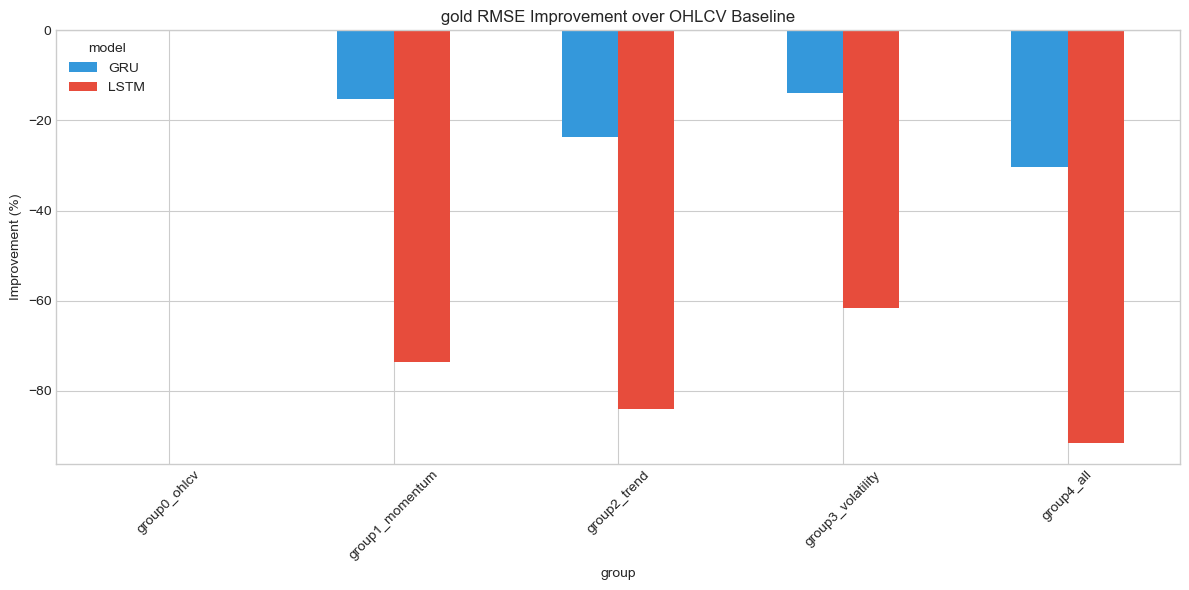

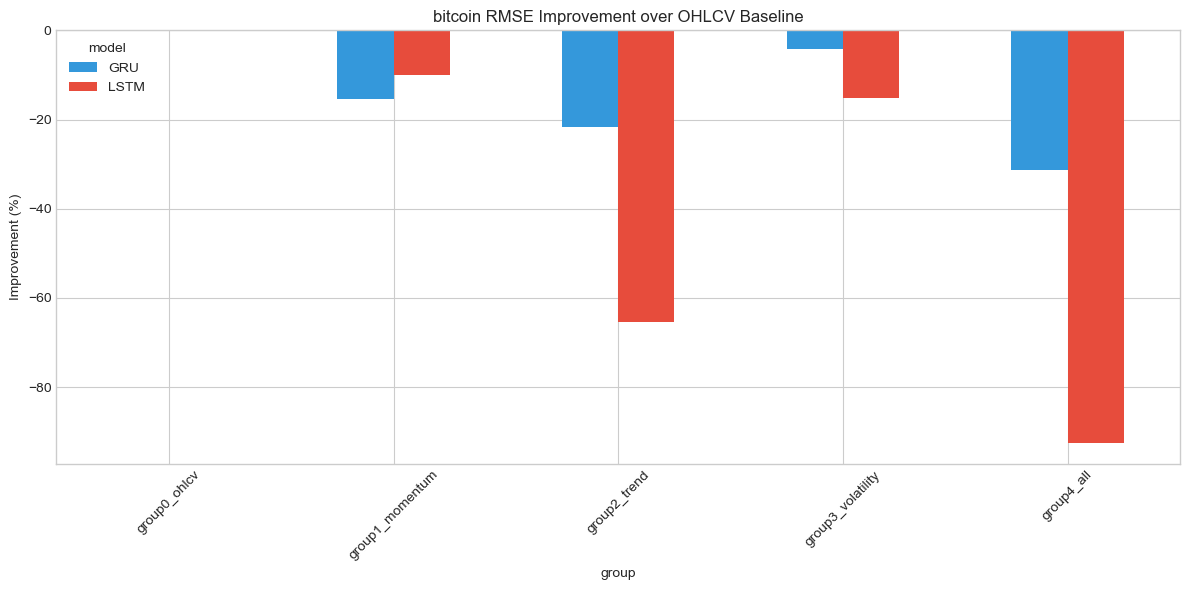

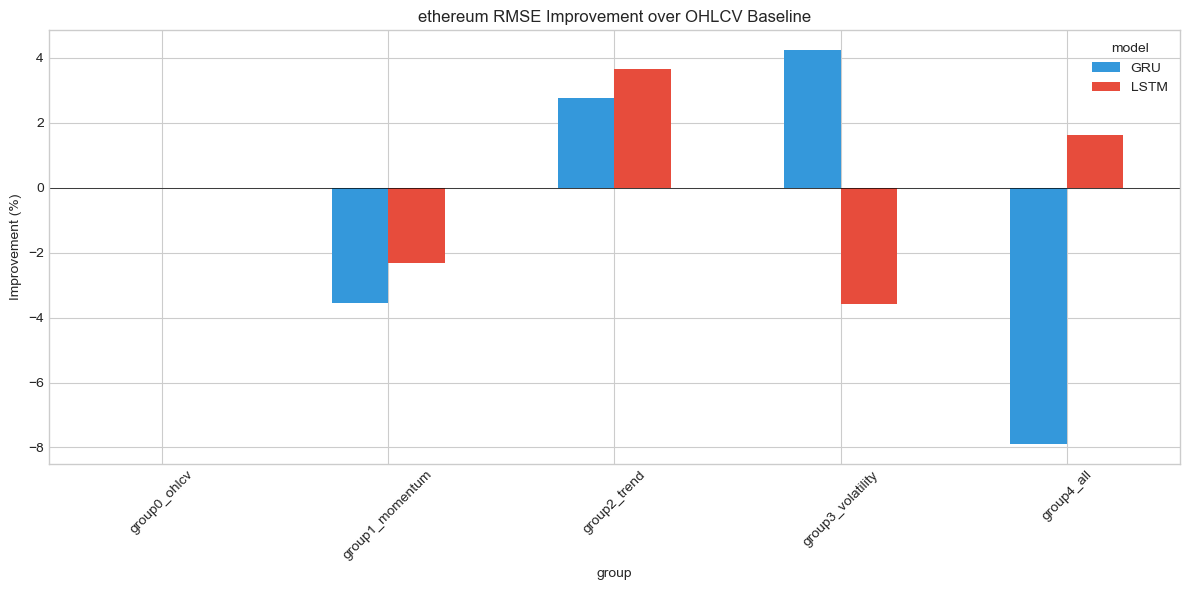

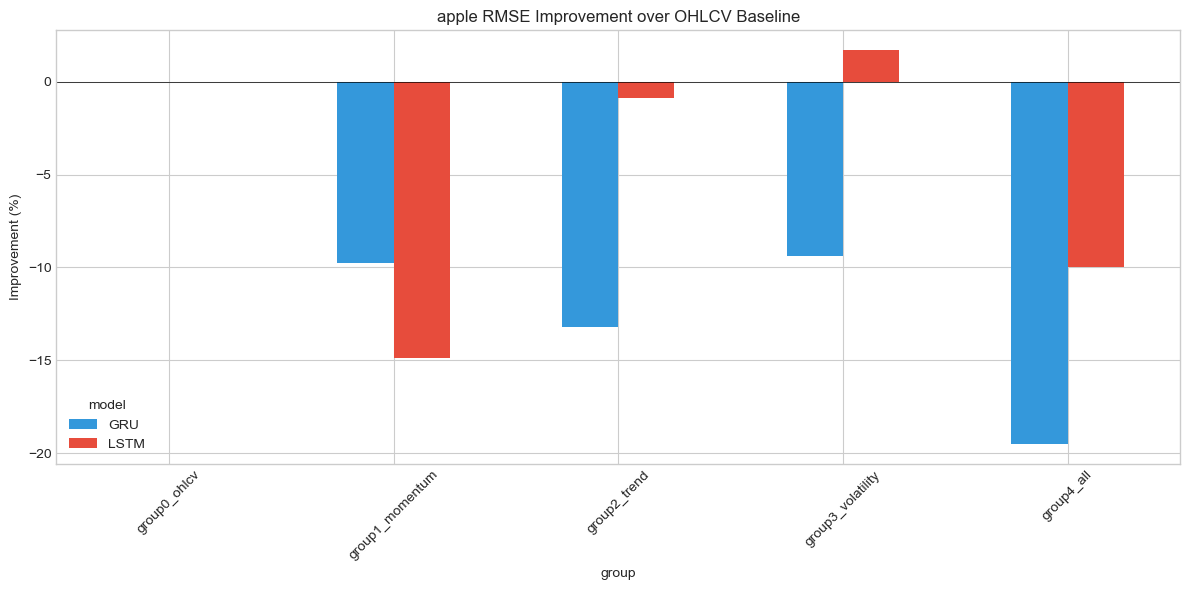

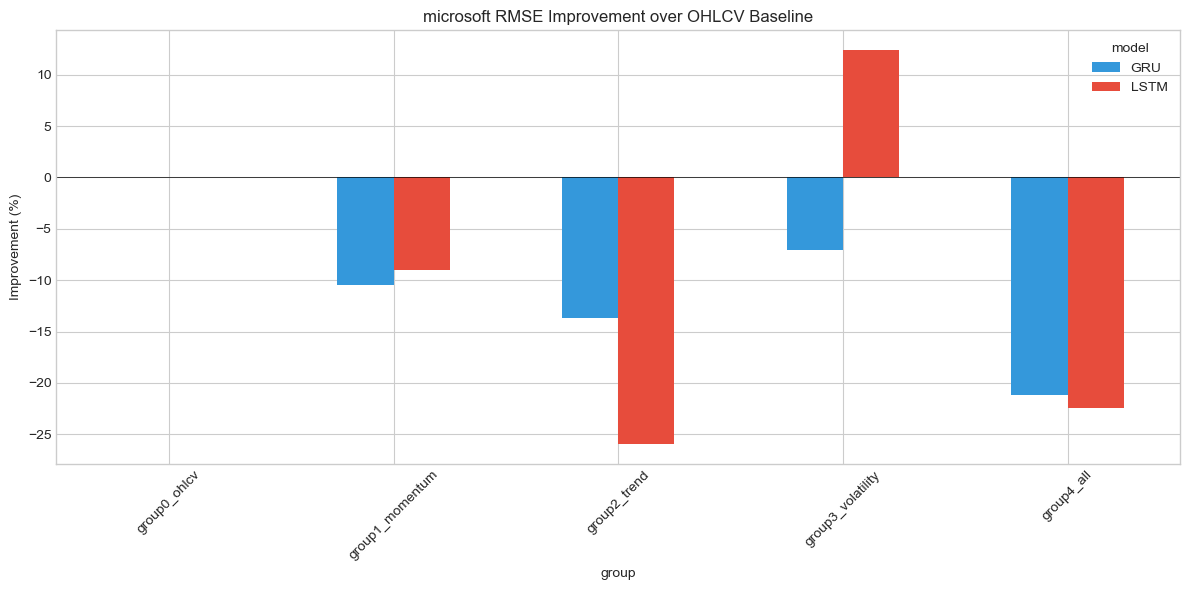

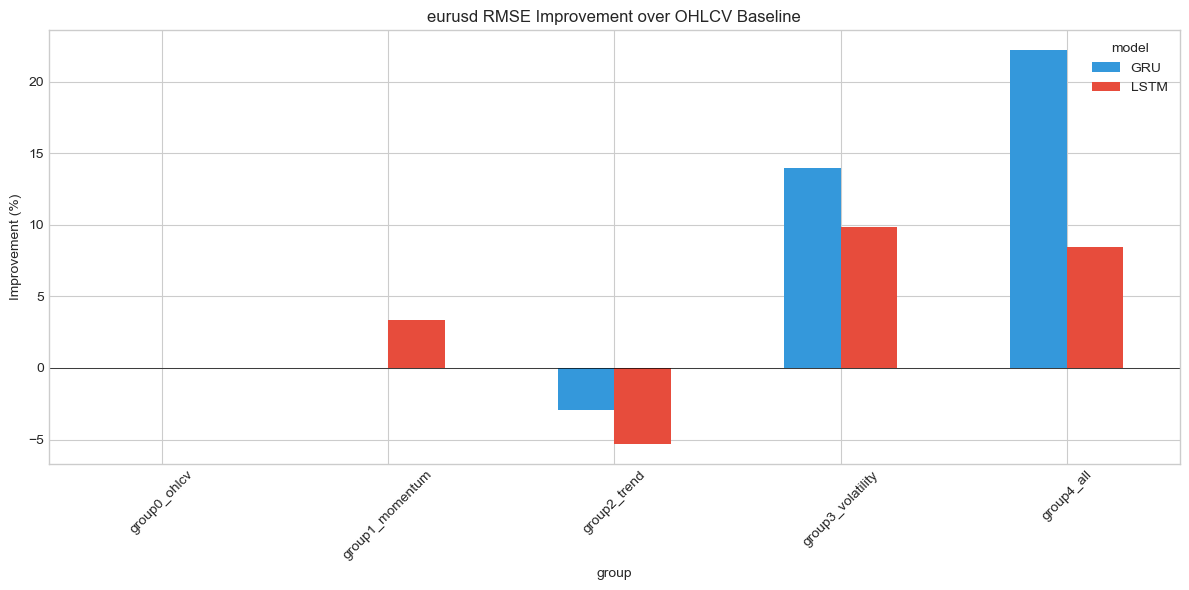

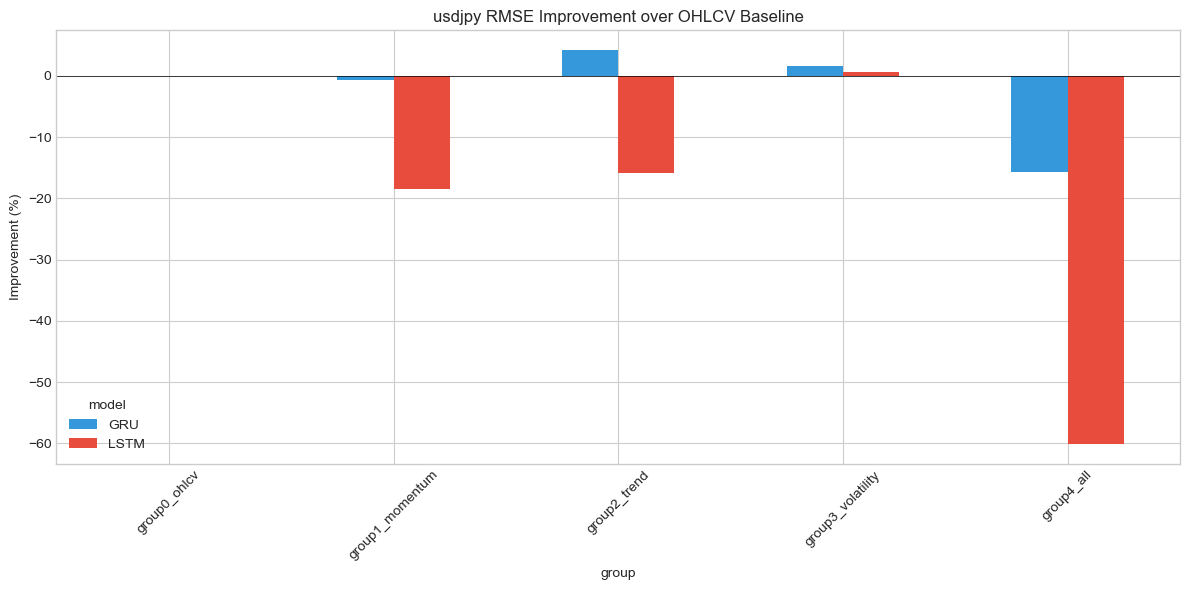

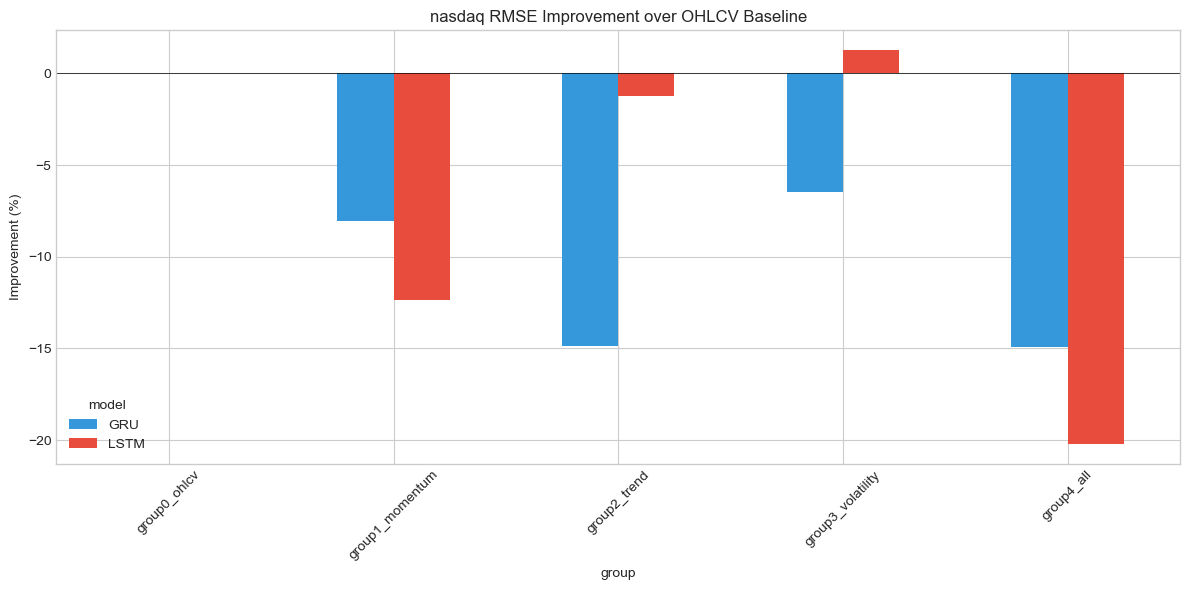

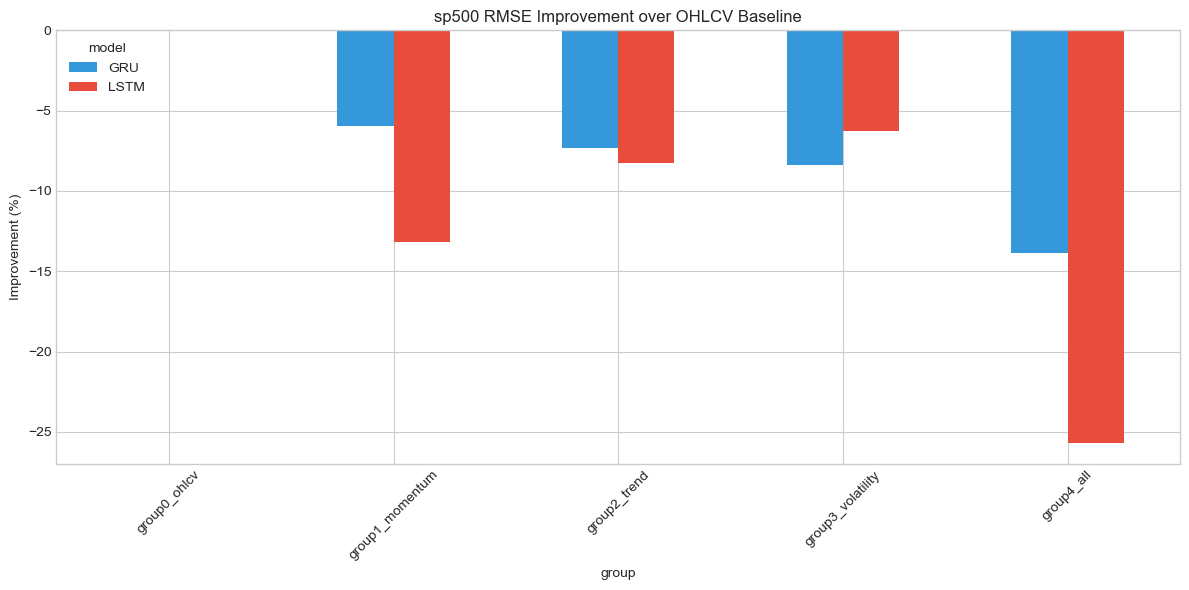

In [11]:
# Feature Group Impact Analysis
for asset in assets:
    asset_metrics = [m for m in all_metrics if m['asset'] == asset]
    if not asset_metrics:
        continue
        
    metrics_df = pd.DataFrame(asset_metrics)
    
    # Calculate improvement over baseline (OHLCV)
    baseline_rmse_lstm = metrics_df[(metrics_df['model'] == 'LSTM') & (metrics_df['group'] == 'group0_ohlcv')][rmse].values
    baseline_rmse_gru = metrics_df[(metrics_df['model'] == 'GRU') & (metrics_df['group'] == 'group0_ohlcv')][rmse].values
    
    if len(baseline_rmse_lstm) == 0 or len(baseline_rmse_gru) == 0:
        continue
        
    baseline_rmse_lstm = baseline_rmse_lstm[0]
    baseline_rmse_gru = baseline_rmse_gru[0]
    
    improvement_data = []
    
    for _, row in metrics_df.iterrows():
        baseline = baseline_rmse_lstm if row['model'] == 'LSTM' else baseline_rmse_gru
        improvement = (baseline - row[rmse]) / baseline * 100
        improvement_data.append({
            'model': row['model'],
            'group': row['group'],
            'improvement_pct': improvement
        })
    
    improvement_df = pd.DataFrame(improvement_data)
    
    # Plot improvement
    fig, ax = plt.subplots(figsize=(12, 6))
    
    pivot_imp = improvement_df.pivot(index='group', columns='model', values='improvement_pct')
    pivot_imp.plot(kind='bar', ax=ax)
    ax.axhline(0, color='k', linestyle='-', linewidth=0.5)
    ax.set_title(f'{asset} RMSE Improvement over OHLCV Baseline')
    ax.set_ylabel('Improvement (%)')
    ax.tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    
    # Save figure
    asset_config = config.get_asset_config(asset)
    category = asset_config['category']
    figures_dir = config.get_path('results') / category / asset / 'figures'
    figures_dir.mkdir(parents=True, exist_ok=True)
    plt.savefig(figures_dir / 'improvement_over_baseline.png', dpi=300)
    plt.show()

## 5. Save Results

In [12]:
# Save Results
for asset in assets:
    asset_metrics = [m for m in all_metrics if m['asset'] == asset]
    if not asset_metrics:
        continue
        
    metrics_df = pd.DataFrame(asset_metrics)
    
    # Calculate improvement
    baseline_rmse_lstm = metrics_df[(metrics_df['model'] == 'LSTM') & (metrics_df['group'] == 'group0_ohlcv')][rmse].values
    baseline_rmse_gru = metrics_df[(metrics_df['model'] == 'GRU') & (metrics_df['group'] == 'group0_ohlcv')][rmse].values
    
    improvement_data = []
    if len(baseline_rmse_lstm) > 0 and len(baseline_rmse_gru) > 0:
        baseline_rmse_lstm = baseline_rmse_lstm[0]
        baseline_rmse_gru = baseline_rmse_gru[0]
        
        for _, row in metrics_df.iterrows():
            baseline = baseline_rmse_lstm if row['model'] == 'LSTM' else baseline_rmse_gru
            improvement = (baseline - row[rmse]) / baseline * 100
            improvement_data.append({
                'model': row['model'],
                'group': row['group'],
                'improvement_pct': improvement
            })
    
    improvement_df = pd.DataFrame(improvement_data)
    
    # Save to CSV
    asset_config = config.get_asset_config(asset)
    category = asset_config['category']
    tables_dir = config.get_path('results') / category / asset / 'tables'
    tables_dir.mkdir(parents=True, exist_ok=True)
    
    metrics_df.to_csv(tables_dir / 'model_metrics.csv', index=False)
    if not improvement_df.empty:
        improvement_df.to_csv(tables_dir / 'improvement_analysis.csv', index=False)
    
    print(f"Results saved for {asset} to: {tables_dir}")

Results saved for crudeoil to: C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\results\commodity\crudeoil\tables
Results saved for gold to: C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\results\commodity\gold\tables
Results saved for bitcoin to: C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\results\crypto\bitcoin\tables
Results saved for ethereum to: C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\results\crypto\ethereum\tables
Results saved for apple to: C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\results\equity\apple\tables
Results saved for microsoft to: C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\results\equity\microsoft\tables
Results saved for eurusd to: C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\results\forex\eurusd\tables
Results saved for usdjpy to: C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\results\forex\usdjpy\tables
Results sa

## 6. Summary

In [13]:
# Summary
for asset in assets:
    asset_metrics = [m for m in all_metrics if m['asset'] == asset]
    if not asset_metrics:
        continue
        
    metrics_df = pd.DataFrame(asset_metrics)
    
    asset_config = config.get_asset_config(asset)
    category = asset_config['category']
    
    print(f"\n{'='*60}")
    print(f"RESULTS SUMMARY FOR {asset}")
    print(f"{'='*60}")
    
    if len(metrics_df) > 0:
        # Best overall model
        best_overall = metrics_df.loc[metrics_df[rmse].idxmin()]
        print(f"\nBest Overall Model:")
        print(f"  Model: {best_overall['model']}")
        print(f"  Group: {best_overall['group']}")
        print(f"  RMSE: {best_overall[rmse]:.6f}")
        print(f"  DA: {best_overall[directional_accuracy]:.2f}%")
        
        # Best for each model type
        print(f"\nBest by Model Type:")
        for model in ['LSTM', 'GRU']:
            subset = metrics_df[metrics_df['model'] == model]
            if len(subset) > 0:
                best = subset.loc[subset[rmse].idxmin()]
                print(f"  {model}: {best['group']} (RMSE={best[rmse]:.6f})")
        
        # Feature group impact
        baseline_rmse_lstm = metrics_df[(metrics_df['model'] == 'LSTM') & (metrics_df['group'] == 'group0_ohlcv')][rmse].values
        baseline_rmse_gru = metrics_df[(metrics_df['model'] == 'GRU') & (metrics_df['group'] == 'group0_ohlcv')][rmse].values
        
        if len(baseline_rmse_lstm) > 0 and len(baseline_rmse_gru) > 0:
            print(f"\nFeature Group Impact (vs OHLCV baseline):")
            for group in GROUPS[1:]:  # Skip baseline
                lstm_imp = metrics_df[(metrics_df['model'] == 'LSTM') & (metrics_df['group'] == group)][rmse].values
                gru_imp = metrics_df[(metrics_df['model'] == 'GRU') & (metrics_df['group'] == group)][rmse].values
                
                if len(lstm_imp) > 0 and len(gru_imp) > 0:
                    avg_baseline = (baseline_rmse_lstm[0] + baseline_rmse_gru[0]) / 2
                    avg_rmse = (lstm_imp[0] + gru_imp[0]) / 2
                    imp = (avg_baseline - avg_rmse) / avg_baseline * 100
                    print(f"  {group}: {imp:+.2f}%")
        
        # Save summary to file
        summaries_dir = config.get_path('results') / 'summaries'
        summaries_dir.mkdir(parents=True, exist_ok=True)
        
        with open(summaries_dir / f'{asset}_results_summary.txt', 'w') as f:
            f.write(f"{'='*60}\n")
            f.write(f"RESULTS SUMMARY FOR {asset}\n")
            f.write(f"{'='*60}\n")
            
            f.write(f"\nBest Overall Model:\n")
            f.write(f"  Model: {best_overall['model']}\n")
            f.write(f"  Group: {best_overall['group']}\n")
            f.write(f"  RMSE: {best_overall[rmse]:.6f}\n")
            f.write(f"  DA: {best_overall[directional_accuracy]:.2f}%\n")
            
            f.write(f"\nBest by Model Type:\n")
            for model in ['LSTM', 'GRU']:
                subset = metrics_df[metrics_df['model'] == model]
                if len(subset) > 0:
                    best = subset.loc[subset[rmse].idxmin()]
                    f.write(f"  {model}: {best['group']} (RMSE={best[rmse]:.6f})\n")
            
            if len(baseline_rmse_lstm) > 0 and len(baseline_rmse_gru) > 0:
                f.write(f"\nFeature Group Impact (vs OHLCV baseline):\n")
                for group in GROUPS[1:]:  # Skip baseline
                    lstm_imp = metrics_df[(metrics_df['model'] == 'LSTM') & (metrics_df['group'] == group)][rmse].values
                    gru_imp = metrics_df[(metrics_df['model'] == 'GRU') & (metrics_df['group'] == group)][rmse].values
                    
                    if len(lstm_imp) > 0 and len(gru_imp) > 0:
                        avg_baseline = (baseline_rmse_lstm[0] + baseline_rmse_gru[0]) / 2
                        avg_rmse = (lstm_imp[0] + gru_imp[0]) / 2
                        imp = (avg_baseline - avg_rmse) / avg_baseline * 100
                        f.write(f"  {group}: {imp:+.2f}%\n")
        
        print(f"\nSummary saved to: {summaries_dir / f'{asset}_results_summary.txt'}")


RESULTS SUMMARY FOR crudeoil

Best Overall Model:
  Model: GRU
  Group: group4_all
  RMSE: 0.015529
  DA: 47.79%

Best by Model Type:
  LSTM: group0_ohlcv (RMSE=0.023837)
  GRU: group4_all (RMSE=0.015529)

Feature Group Impact (vs OHLCV baseline):
  group1_momentum: -3.27%
  group2_trend: +5.10%
  group3_volatility: -2.23%
  group4_all: +14.45%

Summary saved to: C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\results\summaries\crudeoil_results_summary.txt

RESULTS SUMMARY FOR gold

Best Overall Model:
  Model: LSTM
  Group: group0_ohlcv
  RMSE: 0.452457
  DA: 58.17%

Best by Model Type:
  LSTM: group0_ohlcv (RMSE=0.452457)
  GRU: group0_ohlcv (RMSE=0.640695)

Feature Group Impact (vs OHLCV baseline):
  group1_momentum: -39.30%
  group2_trend: -48.67%
  group3_volatility: -33.63%
  group4_all: -55.71%

Summary saved to: C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\results\summaries\gold_results_summary.txt

RESULTS SUMMARY FOR bitcoin

Best Overall M